# San Ramon 2015: the deep-learning picker inside SeisComP against the NCSS analyst picks

**What is checked here.** SED's scdlrtpicker plugin puts deep-learning (DL) phase pickers inside SeisComP's automatic
picker *scautopick*. The usual detector (an STA/LTA trigger) finds candidate arrivals; a neural network (an ONNX model)
then decides whether, and exactly where, there is a P arrival in a window around each trigger. After a P pick it
starts a second network that looks for the S arrival. Step 12 of this project ran the plugin offline on the test events
of the 2015 San Ramon swarm (Northern California, public NCEDC data) with four models, on two sets of station bindings,
and compared the picks with the reviewed picks of the Northern California Seismic System (NCSS) analysts. It also
checked the first-motion polarity of `eqtp_ncedc`, cross-checked `eqtp_ncedc` against SeisBench, and measured the
cost.

**This notebook does no picking.** It loads the result files of step 12, recomputes the summary numbers it shows from
the per-pick files as a check, and draws eight figures. Every number in the text below a figure is formatted from the
loaded files; none is typed in. The functions of the step 12 analysis scripts are imported (their main programs are
not run) and reused.

**Terms used throughout, in plain words**

- *Pick*: the time at which a program (or a person) marks the arrival of a wave at a station.
- *P and S waves*: the P wave (compressional) is faster and arrives first; the S wave (shear) arrives later and is
  strongest on the horizontal components.
- *Analyst picks*: the reviewed NCSS picks. Each carries a *weight code* from 0 to 3 that says how sure the analyst
  was (0 = most sure, a sharp "impulsive" onset; 3 = least sure). Out-weighted picks (codes 5 to 8) are left out.
  Many P picks also carry a *first motion*: whether the ground first moved up (U) or down (D).
- *3-component sensor*: a sensor with a vertical and two horizontal channels. All four models need all three; a
  station with only a vertical channel cannot be used by them.
- *Triggered record*: some strong-motion recorders save data only when the shaking passes a threshold, so their record
  starts shortly before the event instead of running continuously.
- *initTime*: scautopick waits this long after the first sample of a record before its detector starts (it first
  needs a noise level). An arrival earlier than that cannot start a picker.
- *Model, variant, binding set*: a model is one trained network (for example PhaseNet with the INSTANCE weights). A
  binding tells scautopick which sensor of a station to use. The *main set* uses one sensor per station, velocity
  sensors first; the *accelerometer set* (variant names ending in `_hn`) uses the accelerometer at the stations whose
  main sensor is a velocity sensor, so the two kinds of sensor can be compared at the same sites.
- *Match*: a DL pick and an analyst pick of the same station and phase whose times are within the matching tolerance
  (section 1.3). Pairs are formed one-to-one, closest first.
- *Recall*: of all the arrivals the analysts picked, the share the DL picker also picked. "Did it find what the
  analysts found?" Recall is given over four sets of analyst picks (Figure 1 explains why).
- *Precision*: of all the DL picks inside the event windows, the share that an analyst also picked. "Are its picks ones
  the analysts agree with?" The analysts did not pick every station, and picked S only rarely, so a DL pick without an
  analyst partner is not necessarily wrong. Precision here is therefore a **lower bound**. *Precision counting
  plausible arrivals* also counts as correct the unmatched DL picks that lie close to the predicted arrival time (an
  upper bound).
- *F1*: one number that combines recall (R) and precision (P), F1 = 2RP / (R + P). It is high only when both are high.
- *dt*: DL pick time minus analyst pick time of a matched pair. *Median |dt|* is the typical size of the difference,
  *p95 |dt|* the size that 95% of the pairs stay below.
- *minConfidence*: the smallest network output (between 0 and 1) that the plugin accepts as a pick.
  *polarityMinConfidence*: the same for the polarity of a P pick.
- *Station-hour*: one hour of data at one station. *CPU-s*: seconds of processor time.

**Contents**

0. Parameters, imports
1. Inputs, consistency checks and the settings of the runs
2. Figure 1: which analyst picks a 3-component picker can reach
3. Figure 2: recall and precision per model
4. Figure 3: pick-time differences against the analysts
5. Figure 4: the swarm overlap, and a foreshock seconds before the mainshock
6. Figure 5: example waveforms of the mainshock
7. Figure 6: accelerometer against velocity sensor at the same sites
8. Figure 7: first-motion polarity of `eqtp_ncedc`
9. Figure 8: plugin against SeisBench, and the cost
10. Comprehensive summary

## 0. Parameters

Every setting of this notebook is in the next cell: the input folders, the picker runs shown, the histogram ranges,
the waveform filter, the rules that choose the waveform examples, and the polarity thresholds. Nothing further down
changes them.

In [1]:
# ============================== PARAMETERS ==============================
# every setting of this notebook; nothing below changes these values (the markdown text quotes them)
import time as _time
T_START = _time.time()                               # the run time is printed at the very end
PROJECT = "/home/msseo/works/74.SeisComP_rtDD_DLpicker"
DATA = f"{PROJECT}/data/sanramon_2015"
RUN = f"{PROJECT}/runs/sanramon/dlpicker"           # step 12 (scautopick + scdlrtpicker), read only
ANA = f"{RUN}/analysis"                              # comparison tables of step 12
SB_DIR = f"{RUN}/seisbench"                          # SeisBench cross-check of step 12
CONFIG_DIR = f"{RUN}/config"                         # bindings, record coverage, bound channels
SETTINGS_DIR = f"{RUN}/settings"                     # resolved scautopick and plugin settings per variant
PICK_DIR = f"{RUN}/output"                           # picks.xml and scautopick logs per variant and event
SORTED_DIR = f"{RUN}/input"                          # the sorted miniSEED files scautopick read (only to check the copies)
SCRIPTS = f"{RUN}/scripts"                           # step 12 analysis scripts (imported, main() not run)
PLAYBACK_DIR = f"{DATA}/inputs/playback"             # event miniSEED files, origin -120 s to +120 s (waveform figures)
STATIONXML = f"{DATA}/inputs/stations.xml"           # sensitivity sign and dip of the plotted channels
REF_PICKS = f"{DATA}/reference_tables/picks_ncss.csv"   # NCSS analyst picks (reference)
EVENTS = f"{DATA}/inputs/dl_subset_events.csv"       # the 26 test events
CATALOG = f"{DATA}/reference_tables/ncss_catalog.csv"   # NCSS catalog (neighbouring events, magnitude types)
WAVEFORM_TOOL = f"{DATA}/tools/download_waveforms.py"   # its DL_MAX_KM / DL_WIN = radius and window of the playback files (read, not run)
NOTE12 = f"{PROJECT}/docs/results/12_sanramon_dlpicker.md"   # only to cross-check the numbers it quotes
OUT = f"{PROJECT}/runs/sanramon/dlpicker_nb07"       # what this notebook writes: key-number tables, summary.json
FIG_DIR = f"{PROJECT}/notebooks/figures"             # every figure as 07_*.png (200 dpi) and 07_*.pdf
LIB = f"{PROJECT}/notebooks/lib"                     # nbfont.py and nb07_helpers.py

# --- the picker runs compared (step 12 names) ---
MODELS = ["phasenet_instance", "phasenet_original", "phasenet_scedc", "eqtp_ncedc"]   # main binding set
HN_SUFFIX = "_hn"                  # the same models on the accelerometer binding set (13 co-located sites)
POLARITY_MODEL = "eqtp_ncedc"      # the only model with first-motion polarity outputs
SB_MODEL = "eqtp_ncedc"            # the model also run with SeisBench's continuous picking (its test events)
SB_REFERENCE_MODEL = "phasenet_instance"   # plugin model shown beside the SeisBench comparison, same events

# --- Figure 1 ---
TRIG_BIN_S = 5.0                   # histogram bin of the analyst pick time after the record start
TRIG_XMAX_S = 150.0                # histogram range 0 to this (s)

# --- Figure 3 ---
DT_XLIM_S = 0.30                   # x-range of the time-difference histograms, +-0.30 s (pairs beyond it are counted)
DT_BIN_S = 0.01                    # bin width = one sample at 100 Hz

# --- waveform figures (4 and 5): the band of step 12's SNR measurement (12_compare.py) ---
BAND_HZ = (2.0, 20.0)              # band-pass
FILTER_CORNERS = 4
FILTER_ZEROPHASE = False           # causal (one pass): cannot move energy ahead of an onset
TAPER_FRACTION = 0.05              # taper of the whole 240-s record before filtering

# --- Figure 4 (swarm overlap) ---
SWARM_EVENT = "72540760"           # the foreshock
SWARM_NEIGHBOUR = "72540765"       # the mainshock that follows it
SWARM_STATION_MODEL = "phasenet_instance"   # station rule: this model missed the foreshock P as 'window picked another time'
SWARM_VIEW_S = (-3.0, 12.0)        # time after the station's analyst P pick of the foreshock (s)
NONE_X = 250.0                     # x position (s) of the events with no other catalog event within 120 s
NEAR_S = 15.0                      # shading of 'neighbour within 15 s' (step 12's class boundary)
SWARM_ZOOM_S = (-0.5, 1.5)         # panel (d): the foreshock P enlarged (s after its analyst P pick)

# --- Figure 5 (waveforms of the M3.6) ---
WF_EVENT = "72540765"
WF_SPAN_S = (-1.0, 2.0)            # vertical: around the analyst P pick; horizontals: around the analyst (or predicted) S
WF_RULES = [("EH", "3c_complete", "nearest"), ("HH", "3c_complete", "nearest"), ("HH", "3c_complete", "farthest"),
            ("HN", "3c_complete", "nearest"), ("HN", "3c_incomplete", "nearest")]   # (bound sensor, record tier, which)

# --- Figure 7 (polarity) ---
POL_THRESHOLDS = (0.5, 0.7)        # polarityMinConfidence: plugin default and the stricter value of step 12
POL_SWEEP = (0.50, 0.95, 0.01)     # threshold sweep (start, stop, step); picks do not depend on it
POL_MIN_N = 10                     # agreement is drawn only where at least this many pairs of a group have a DL polarity

# --- Figure 8 ---
SB_HIST_LIM_S = 0.30               # plugin minus SeisBench, shown from -0.30 to +0.30 s (pairs beyond are counted)
SB_HIST_BIN_S = 0.01

In [2]:
# imports, Helvetica, versions, colors and labels
import os
import sys
import glob
import json
import re
import importlib
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from IPython.display import display, Markdown
import obspy
from obspy import read, read_inventory, UTCDateTime

sys.path.insert(0, LIB)
import nbfont
import nb07_helpers as h
importlib.reload(h)

FONT_FAMILY = nbfont.use_helvetica(verbose=True)
print("resolved font family:", FONT_FAMILY, "| font file matplotlib uses for text:",
      matplotlib.font_manager.findfont(matplotlib.font_manager.FontProperties(family=["sans-serif"])))
plt.rcParams.update({"font.size": 9, "axes.titlesize": 9.0, "axes.labelsize": 9, "legend.fontsize": 8,
                     "xtick.labelsize": 8, "ytick.labelsize": 8, "figure.dpi": 100, "hatch.linewidth": 0.7,
                     "axes.spines.top": True, "axes.spines.right": True, "axes.spines.left": True,
                     "axes.spines.bottom": True,
                     "mathtext.cal": "Helvetica:italic"})   # unused calligraphic slot; avoids a 'cursive' font lookup
os.makedirs(OUT, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)
pd.set_option("display.width", 230)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 140)

# the step 12 analysis scripts, imported as modules (only their functions are used; main() is not run); no bytecode cache is
# written next to them, so the step 12 run folder stays as it is
sys.dont_write_bytecode = True
C12 = h.import_script(f"{SCRIPTS}/12_compare.py", "s12_compare")
CSB = h.import_script(f"{SCRIPTS}/12_compare_seisbench.py", "s12_compare_seisbench")
CBI = h.import_script(f"{SCRIPTS}/12_bindings.py", "s12_bindings")
print("imported from the step 12 scripts:", "12_compare.py (read_scml_picks, match, dtstats, parse_log, TIERS),",
      "12_compare_seisbench.py (dstats), 12_bindings.py (polarity_sense)")

# one color and one marker per model, kept in every figure; PhaseNet INSTANCE and PhaseNet original as in notebook 03,
# the two models new here get two further colorblind-safe colors (checked: OKLab difference >= 10 under simulated
# protanopia and deuteranopia between every pair, and between each model and the analyst color)
COL = {"phasenet_instance": "#56B4E9", "phasenet_original": "#E69F00", "phasenet_scedc": "#882255",
       "eqtp_ncedc": "#332288"}
MARK = {"phasenet_instance": "D", "phasenet_original": "s", "phasenet_scedc": "h", "eqtp_ncedc": "o"}
LABEL = {"phasenet_instance": "PhaseNet (INSTANCE weights)", "phasenet_original": "PhaseNet (original weights)",
         "phasenet_scedc": "PhaseNet (SCEDC weights)", "eqtp_ncedc": "EQTP (EQTransformer with polarity, NCEDC weights)"}
SHORT = {"phasenet_instance": "PhaseNet INSTANCE", "phasenet_original": "PhaseNet original",
         "phasenet_scedc": "PhaseNet SCEDC", "eqtp_ncedc": "EQTP NCEDC"}
for m in MODELS:
    COL[m + HN_SUFFIX], MARK[m + HN_SUFFIX] = COL[m], MARK[m]
    SHORT[m + HN_SUFFIX] = SHORT[m] + ", accelerometer set"
ANALYST = "#0072B2"          # analyst picks in the waveform figures (the reference color of notebook 03)
VARIANTS = MODELS + [m + HN_SUFFIX for m in MODELS]
PH = ["P", "S"]
FIGS = {}
print("versions: python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__,
      "| obspy", obspy.__version__, "| matplotlib", matplotlib.__version__)

font family in use: Helvetica (8 faces registered)
resolved font family: Helvetica | font file matplotlib uses for text: /home/msseo/.local/share/fonts/helvetica-family/Helvetica-Regular.otf
imported from the step 12 scripts: 12_compare.py (read_scml_picks, match, dtstats, parse_log, TIERS), 12_compare_seisbench.py (dstats), 12_bindings.py (polarity_sense)
versions: python 3.12.15 | numpy 2.5.4 | pandas 3.0.6 | obspy 1.5.1 | matplotlib 3.11.2


## 1. Inputs, consistency checks and settings

### 1.1 The result files of step 12

All tables below are read as they are on disk. The next cell lists each file with its modification time and size, so
that it is clear which version was plotted, and scans every scautopick log for error and warning lines.

In [3]:
# 1.1 load every result file of step 12 that the figures use
FILES = {
    "summary_by_model": f"{ANA}/summary_by_model.csv", "by_tier": f"{ANA}/by_tier.csv", "by_event": f"{ANA}/by_event.csv",
    "by_neighbour": f"{ANA}/by_neighbour.csv", "by_weight_code": f"{ANA}/by_weight_code.csv",
    "by_bound_sensor": f"{ANA}/by_bound_sensor.csv",
    "accelerometer_vs_velocity": f"{ANA}/accelerometer_vs_velocity.csv", "event_neighbours": f"{ANA}/event_neighbours.csv",
    "reference_picks": f"{ANA}/reference_picks.csv", "reference_vs_dl": f"{ANA}/reference_vs_dl.csv",
    "dl_picks_all": f"{ANA}/dl_picks_all.csv", "missed_reference_diagnosis": f"{ANA}/missed_reference_diagnosis.csv",
    "unmatched_in_window": f"{ANA}/unmatched_in_window.csv", "outside_window": f"{ANA}/outside_window.csv",
    "polarity_pairs": f"{ANA}/polarity_pairs.csv", "cost": f"{ANA}/cost.csv", "cost_per_run": f"{ANA}/cost_per_run.csv",
    "station_hours": f"{ANA}/station_hours.csv", "summary_json": f"{ANA}/summary.json", "best_model": f"{ANA}/best_model.json",
    "normalization_test": f"{ANA}/normalization_test.json", "polarity_reference_check": f"{ANA}/polarity_reference_check.json",
    "seisbench_pairs": f"{SB_DIR}/compare_seisbench_pairs.csv", "seisbench_vs_reference": f"{SB_DIR}/compare_seisbench_vs_reference.csv",
    "seisbench_summary": f"{SB_DIR}/compare_seisbench_summary.json", "seisbench_run": f"{SB_DIR}/run.json",
    "seisbench_weights_check": f"{SB_DIR}/weights_check.json", "seisbench_settings": f"{SB_DIR}/{SB_MODEL}_settings.json",
    "stations_bound": f"{CONFIG_DIR}/stations_bound.csv", "coverage_bound": f"{CONFIG_DIR}/coverage_bound.csv",
    "bound_channels": f"{CONFIG_DIR}/bound_channels.csv",
    "analyst_picks": REF_PICKS, "events": EVENTS, "ncss_catalog": CATALOG, "stationxml": STATIONXML, "note12": NOTE12,
    "waveform_tool": WAVEFORM_TOOL}
display(pd.DataFrame([{"Name": k, "File": v.replace(PROJECT + "/", ""),
                       "Modified (local time)": pd.Timestamp(os.path.getmtime(v), unit="s", tz="UTC").tz_convert("Asia/Seoul").strftime("%Y-%m-%d %H:%M"),
                       "Size (kB)": round(os.path.getsize(v) / 1024, 1)} for k, v in FILES.items()]).set_index("Name"))

DTYPES = {"event_id": str, "location": str, "location_raw": str, "matched_event_id": str, "nearest_other_event": str}
rd = lambda k: pd.read_csv(FILES[k], dtype=DTYPES, low_memory=False)
rj = lambda k: json.load(open(FILES[k]))
EV = pd.read_csv(EVENTS, dtype={"event_id": str}).set_index("event_id")
EV["origin_ts"] = h.ts_utc(EV.origin_time_utc)
CAT = pd.read_csv(CATALOG, dtype={"event_id": str}).set_index("event_id")
MAGT = CAT.pref_mag_type.to_dict()
MAGT.update(EV.pref_mag_type.to_dict())
SBM = rd("summary_by_model")
ALL = SBM.set_index(["variant", "phase"])
BYTIER, BYEV, BYNB, BYW, BYSENS = (rd(k) for k in ("by_tier", "by_event", "by_neighbour", "by_weight_code", "by_bound_sensor"))
BYEV["event_id"] = BYEV["value"].str.split().str[0]
AVV = rd("accelerometer_vs_velocity")
NBR = rd("event_neighbours").set_index("event_id")
REF = h.bool_cols(rd("reference_picks"), ["usable", "benchmark_event", "ref_outlier", "has_data", "is_3c"])
RVD = h.bool_cols(rd("reference_vs_dl"), ["usable", "benchmark_event", "ref_outlier", "has_data", "is_3c", "matched"])
DLP = h.bool_cols(rd("dl_picks_all"), ["in_window", "matched", "in_searchable_span"])
MISS = h.bool_cols(rd("missed_reference_diagnosis"), ["ref_outlier"])
UNM = rd("unmatched_in_window")
OUTW = rd("outside_window")
POL = h.bool_cols(rd("polarity_pairs"), ["matched", "same_channel_as_analyst", "has_data", "is_3c", "ref_outlier"])
for c in ("dl_fm", "analyst_fm", "dl_fm_raw_counts", "dl_channel_sense"):
    POL[c] = POL[c].fillna("")
COST = rd("cost").set_index("variant")
COSTRUN = rd("cost_per_run")
SHRS = rd("station_hours")
SUMJ, BEST, NORMJ, PREFJ = rj("summary_json"), rj("best_model"), rj("normalization_test"), rj("polarity_reference_check")
BEST_MODEL = BEST["best_model"]
SBP = rd("seisbench_pairs")
SBR = rd("seisbench_vs_reference")
SBS, SBRUN, WCHK, SBSET = rj("seisbench_summary"), rj("seisbench_run"), rj("seisbench_weights_check"), rj("seisbench_settings")
SB_EVENTS = [str(e) for e in SBS["events"]]
STB = pd.read_csv(FILES["stations_bound"], dtype=str).fillna("")
STB["nsta"] = STB.network + "." + STB.station
COV = rd("coverage_bound")
COV["nsta"] = COV.network + "." + COV.station
COV["location"] = COV.location.fillna("")
BCH = rd("bound_channels")
BCH["nsta"] = BCH.network + "." + BCH.station
BCH["location"] = BCH.location.fillna("")
NOTE = open(NOTE12).read()
m_ = re.search(r"DL_MAX_KM, DL_WIN = ([0-9.]+), \(([-0-9.]+), ([-0-9.]+)\)", open(WAVEFORM_TOOL).read())
PLAYBACK_KM, PLAYBACK_WIN = float(m_.group(1)), (float(m_.group(2)), float(m_.group(3)))
print(f"playback files (download_waveforms.py): every sensor within {PLAYBACK_KM:g} km, origin {PLAYBACK_WIN[0]:+g} s to {PLAYBACK_WIN[1]:+g} s")
SETS = {v: json.load(open(f"{SETTINGS_DIR}/scautopick_{v}.settings.json")) for v in VARIANTS}
RVD["ts"] = h.ts_utc(RVD["time"])
DLP["ts"] = h.ts_utc(DLP["time"])
REF["ts"] = h.ts_utc(REF["time"])
TIERS = list(C12.TIERS)
assert set(DLP.variant) == set(VARIANTS), "the variants in dl_picks_all.csv differ from VARIANTS"
assert set(EV.index) == set(REF.event_id), "reference_picks.csv covers other events than dl_subset_events.csv"
assert BEST_MODEL in MODELS
print(f"{len(EV)} events, magnitude {EV.pref_mag.min():.2f}-{EV.pref_mag.max():.2f} (types: "
      + ", ".join(f"{k} {n}" for k, n in EV.pref_mag_type.value_counts().items()) + f"); {len(REF)} usable analyst picks "
      f"({(REF.phase == 'P').sum()} P, {(REF.phase == 'S').sum()} S); {DLP.variant.nunique()} picker runs; best model by "
      f"step 12's fixed rule: {BEST_MODEL}")

# scautopick logs: [error] and [warning] lines of every run (start-up probes included)
LOGS = sorted(glob.glob(f"{PICK_DIR}/*/*/scautopick.log"))
n_err = n_warn = 0
warn_kinds = {}
for f in LOGS:
    for line in open(f, errors="replace"):
        if "[error]" in line:
            n_err += 1
        elif "[warning]" in line:
            n_warn += 1
            k = re.sub(r" on .*", "", line.split("[warning]", 1)[1].strip())[:40]
            warn_kinds[k] = warn_kinds.get(k, 0) + 1
n_probe = sum("startup_probe" in f for f in LOGS)
LOGSTAT = dict(n_logs=len(LOGS), n_event_runs=len(LOGS) - n_probe, n_probe_runs=n_probe, n_error=n_err, n_warning=n_warn,
               warning_kinds=warn_kinds)
print(f"scautopick logs: {len(LOGS)} ({len(LOGS) - n_probe} event runs = {len(VARIANTS)} variants x {len(EV)} events, plus "
      f"{n_probe} start-up probes); [error] lines: {n_err}; [warning] lines: {n_warn} {warn_kinds}")

,File,Modified (local time),Size (kB)
Name,,,
summary_by_model,runs/sanramon/dlpicker/analysis/summary_by_mod...,2026-10-17 22:22,4.4
by_tier,runs/sanramon/dlpicker/analysis/by_tier.csv,2026-10-17 22:22,10.7
by_event,runs/sanramon/dlpicker/analysis/by_event.csv,2026-10-17 22:22,98.2
by_neighbour,runs/sanramon/dlpicker/analysis/by_neighbour.csv,2026-10-17 22:22,17.2
by_weight_code,runs/sanramon/dlpicker/analysis/by_weight_code...,2026-10-17 22:22,13.1
by_bound_sensor,runs/sanramon/dlpicker/analysis/by_bound_senso...,2026-10-17 22:22,21.2
accelerometer_vs_velocity,runs/sanramon/dlpicker/analysis/accelerometer_...,2026-10-17 22:22,3.4
event_neighbours,runs/sanramon/dlpicker/analysis/event_neighbou...,2026-10-17 22:20,1.4
reference_picks,runs/sanramon/dlpicker/analysis/reference_pick...,2026-10-17 22:23,800.6


playback files (download_waveforms.py): every sensor within 80 km, origin -120 s to +120 s
26 events, magnitude 0.81-3.60 (types: D 21, W 4, L 1); 2585 usable analyst picks (2422 P, 163 S); 8 picker runs; best model by step 12's fixed rule: phasenet_instance


scautopick logs: 216 (208 event runs = 8 variants x 26 events, plus 8 start-up probes); [error] lines: 0; [warning] lines: 75 {'Duplicate pick': 75}


### 1.2 Consistency checks

Each summary number used in the figures is recomputed here from the per-pick files (the analyst-pick table, the
pair table, the DL pick table, the polarity pairs and the cost per run), partly with the functions of the step 12
scripts themselves (`dtstats`, `dstats`, `polarity_sense`, `read_scml_picks`). The differences must be rounding only
(the CSV files carry 4 decimals). A failed check is listed in the summary at the end. The checks against the
numbers quoted in note 12 come at the end of the notebook (section 10).

In [4]:
# 1.2 recompute the summary numbers from the per-pick files
CHK = []


def chk(name, file_value, recomputed, tol):
    a = np.atleast_1d(np.asarray(file_value, float))
    b = np.atleast_1d(np.asarray(recomputed, float))
    d = float(np.nanmax(np.abs(a - b))) if len(a) else 0.0
    CHK.append({"Check": name, "Values compared": len(a), "Largest difference": d, "Tolerance": tol, "OK": bool(d <= tol)})


PLAUSIBLE = ["plausible_no_analyst_pick", "reference_outlier", "plausible_other_event_arrival"]
# (a) the tiers of the analyst picks
tf = SUMJ["n_reference"]["tiers"]
tr_ = REF.groupby(["tier", "phase"]).size()
chk("summary.json tier counts = reference_picks.csv", [tf[t].get(p, 0) for t in TIERS for p in PH],
    [tr_.get((t, p), 0) for t in TIERS for p in PH], 0)
chk(f"reference_picks.csv = analyst picks with weight 0-3 of the {len(EV)} events (picks_ncss.csv)", len(REF),
    int((lambda a: (a.event_id.isin(EV.index) & a.usable.astype(str).str.lower().eq("true")).sum())(pd.read_csv(REF_PICKS, dtype={"event_id": str}))), 0)
# (b) recall counts, precision counts and dt statistics per variant and phase
rows = []
for v in VARIANTS:
    for ph in PH:
        r = RVD[(RVD.variant == v) & (RVD.phase == ph)]
        d = DLP[(DLP.variant == v) & (DLP.phase == ph) & DLP.in_window]
        st_ = C12.dtstats(r[r.matched].dt_s.to_numpy())
        rows.append(dict(variant=v, phase=ph, n_ref_all=len(r), n_matched_all=int(r.matched.sum()),
                         n_ref_with_data=int((r.tier != "no_data").sum()), n_matched_with_data=int((r.matched & (r.tier != "no_data")).sum()),
                         n_ref_3c=int(r.is_3c.sum()), n_matched_3c=int((r.matched & r.is_3c).sum()),
                         n_ref_3c_complete=int((r.tier == "3c_complete").sum()),
                         n_matched_3c_complete=int((r.matched & (r.tier == "3c_complete")).sum()),
                         n_dl_in_window=len(d), n_dl_matched_any_event=int(d.matched.sum()),
                         n_dl_plausible_unmatched=int(d["class"].isin(PLAUSIBLE).sum()),
                         median_abs_dt_s=st_["median_abs_dt_s"], p95_abs_dt_s=st_["p95_abs_dt_s"], mean_dt_s=st_["mean_dt_s"],
                         mad_dt_s=st_["mad_dt_s"]))
RC = pd.DataFrame(rows).set_index(["variant", "phase"])
for c in ("n_ref_all", "n_matched_all", "n_ref_with_data", "n_matched_with_data", "n_ref_3c", "n_matched_3c",
          "n_ref_3c_complete", "n_matched_3c_complete", "n_dl_in_window", "n_dl_matched_any_event", "n_dl_plausible_unmatched"):
    chk(f"summary_by_model.csv {c} = per-pick count", ALL.loc[RC.index, c], RC[c], 0)
for c in ("median_abs_dt_s", "p95_abs_dt_s", "mean_dt_s", "mad_dt_s"):
    chk(f"summary_by_model.csv {c} = dtstats() of reference_vs_dl.csv", ALL.loc[RC.index, c], RC[c], 2e-4)
for k in ("all", "with_data", "3c", "3c_complete"):
    chk(f"summary_by_model.csv recall_{k} = n_matched / n_ref", ALL[f"recall_{k}"], ALL[f"n_matched_{k}"] / ALL[f"n_ref_{k}"], 6e-5)
chk("summary_by_model.csv precision = matched / DL picks in window", ALL.precision, ALL.n_dl_matched_any_event / ALL.n_dl_in_window, 6e-5)
chk("summary_by_model.csv precision counting plausible", ALL.precision_counting_plausible,
    (ALL.n_dl_matched_any_event + ALL.n_dl_plausible_unmatched) / ALL.n_dl_in_window, 6e-5)
chk("summary_by_model.csv F1 = 2RP / (R + P), R = recall over 3-C stations", ALL.f1,
    2 * ALL.recall_3c * ALL.precision / (ALL.recall_3c + ALL.precision), 2e-4)
rk = pd.DataFrame(BEST["ranking"]).set_index("variant")
chk("best_model.json F1 ranking = summary_by_model.csv pooled P+S F1", rk.f1, ALL.xs("P+S", level="phase").loc[rk.index, "f1"], 6e-5)
# (c) per event, per neighbour class and per weight code (P recall) from reference_vs_dl.csv
RVD["neighbour_class"] = RVD.event_id.map(NBR.neighbour_class)
for name, tab, key, col in (("by_event.csv", BYEV, "event_id", "event_id"), ("by_neighbour.csv", BYNB, "neighbour_class", "value"),
                             ("by_weight_code.csv", BYW, "weight_code", "value")):
    t = tab[(tab.phase != "P+S") & tab.variant.isin(VARIANTS)]
    kk = t[col] if key != "weight_code" else t[col].astype(int)
    g = RVD.groupby(["variant", "phase", key])
    rc_ = pd.DataFrame({"n_ref_3c_complete": g.apply(lambda x: (x.tier == "3c_complete").sum(), include_groups=False),
                        "n_matched_3c_complete": g.apply(lambda x: (x.matched & (x.tier == "3c_complete")).sum(), include_groups=False),
                        "n_matched_3c": g.apply(lambda x: (x.matched & x.is_3c).sum(), include_groups=False)})
    idx = list(zip(t.variant, t.phase, kk))
    chk(f"{name} complete-record and 3-C matched counts = reference_vs_dl.csv",
        t[["n_ref_3c_complete", "n_matched_3c_complete", "n_matched_3c"]].to_numpy(), rc_.reindex(idx).fillna(0).to_numpy(), 0)
# (d) accelerometer against velocity sensor at the same stations
HNST = set(STB.loc[STB.hn_sensor != "", "nsta"])
a_ = []
for r in AVV.itertuples():
    q = RVD[(RVD.variant == r.variant) & (RVD.phase == r.phase) & RVD.nsta.isin(HNST) & RVD.has_data]
    a_.append([len(q), q.matched.sum()])
N13 = len(HNST)
chk(f"accelerometer_vs_velocity.csv picks and matches = reference_vs_dl.csv ({N13} stations, picks with data)",
    AVV[["n_ref_all", "n_matched_all"]].to_numpy(), np.array(a_), 0)
# (e) polarity of eqtp_ncedc: coverage and agreement at both thresholds, per group (rules of 12_compare.py)
PJ = SUMJ["polarity"]
grp = {"all": lambda q: q, "direct_sense": lambda q: q[q.dl_channel_sense == "Direct"],
       "inverted_sense": lambda q: q[q.dl_channel_sense == "Inverted"], "weight_0": lambda q: q[q.weight_code == 0],
       "weight_1": lambda q: q[q.weight_code == 1], "onset_E": lambda q: q[q.onset == "E"], "onset_I": lambda q: q[q.onset == "I"]}
for v in (POLARITY_MODEL, POLARITY_MODEL + HN_SUFFIX):
    q0 = POL[POL.variant == v]
    for thr in POL_THRESHOLDS:
        js = PJ[v][f"thr_{thr}"]
        for g_, f_ in grp.items():
            ca = h.coverage_agreement(f_(q0), thr)
            chk(f"summary.json polarity {v} {g_} at {thr} (coverage, agreement, swap undone) = polarity_pairs.csv",
                [js[g_]["coverage"], js[g_]["agreement"], js[g_]["agreement_raw_counts"]],
                [ca["coverage"], ca["agreement"], ca["agreement_swap_undone"]], 1e-9)
zb = BCH[BCH.component_role == "Z"]
chk("bound_channels.csv polarity sense = 12_bindings.polarity_sense(dip, gain)",
    (zb.polarity_sense == "Inverted").astype(int), [int(CBI.polarity_sense(d, g) == "Inverted") for d, g in zip(zb.dip, zb.gain)], 0)
# (f) why analyst picks were missed, and the classes of unmatched DL picks
mc = MISS.groupby(["variant", "phase", "why_missed"]).size()
js = pd.Series({(k.split("|")[0], k.split("|")[1], c): n for k, d_ in SUMJ["missed_reference_counts"].items() for c, n in d_.items() if n > 0})
chk("missed_reference_diagnosis.csv reason counts = summary.json", js.sort_index(), mc.reindex(js.sort_index().index).fillna(0), 0)
uc = UNM.groupby(["variant", "phase", "class"]).size()
ju = pd.Series({(k.split("|")[0], k.split("|")[1], c): n for k, d_ in SUMJ["unmatched_in_window_counts"].items() for c, n in d_.items() if n > 0})
chk("unmatched_in_window.csv class counts = summary.json", ju.sort_index(), uc.reindex(ju.sort_index().index).fillna(0), 0)
# (g) cost and false-pick rates
cr = COSTRUN[COSTRUN.event_id != "startup_probe"].groupby("variant")[["user_s", "sys_s"]].sum().sum(axis=1)
chk("cost.csv CPU s = sum of cost_per_run.csv (event runs)", COST.cpu_s_total, cr.loc[COST.index], 0.011)
chk("cost.csv CPU s per station-hour = CPU s / station-hours", COST.cpu_s_per_station_hour, COST.cpu_s_total / COST.station_hours, 2e-4)
chk("cost.csv station-hours = station_hours.csv (tolerance: rows x 0.5e-5 h, the rounding of its 5 decimals)", COST.station_hours,
    SHRS.groupby("variant").span_h.sum().loc[COST.index], 0.5e-5 * SHRS.groupby("variant").size().max())
ow = OUTW.set_index(["variant", "phase"])
chk("outside_window.csv false picks per station-hour = (coincident + isolated in span) / searchable hours",
    ow.false_per_station_hour_searchable, ow.n_false_in_searchable_span / ow.station_hours_searchable, 2e-4)
fs_ = DLP[~DLP.in_window & DLP["class"].isin(["coincident", "isolated"]) & DLP.in_searchable_span].groupby(["variant", "phase"]).size()
chk("outside_window.csv false picks in the searchable span = dl_picks_all.csv", ow.n_false_in_searchable_span, fs_.reindex(ow.index).fillna(0), 0)
# (h) SeisBench cross-check
for ph in PH:
    q = SBP[SBP.phase == ph]
    d = CSB.dstats(q.dt_plugin_minus_seisbench_s)
    s_ = SBS["plugin_vs_seisbench"][ph]
    chk(f"SeisBench {ph}: pairs, median |dt|, within 0.05 s, p95, mean = dstats() of compare_seisbench_pairs.csv",
        [s_["n_pairs"], s_["median_abs_dt_s"], s_["frac_within_0p05_s"], s_["p95_abs_dt_s"], s_["mean_dt_s"]],
        [d["n_pairs"], d["median_abs_dt_s"], d["frac_within_0p05_s"], d["p95_abs_dt_s"], d["mean_dt_s"]], 6e-5)
SB3 = REF[REF.event_id.isin(SB_EVENTS) & REF.is_3c]
k3 = {(r.event_id, r.nsta, r.phase): r.tier for r in SB3.itertuples()}
for ph in PH:
    for meth in ("plugin", "seisbench"):
        m3 = SBR[(SBR.method == meth) & (SBR.kind == "matched") & (SBR.phase == ph)]
        m3 = m3[[(e, n, ph) in k3 for e, n in zip(m3.event_id, m3.nsta)]]
        s_ = SBS["vs_reference"][ph]
        chk(f"SeisBench summary {ph} {meth}: analyst picks at 3-C stations and matches = compare_seisbench_vs_reference.csv",
            [s_[meth]["n_ref_3c"], s_[meth]["n_matched_3c"]], [int((SB3.phase == ph).sum()), len(m3)], 0)
chk("SeisBench run.json CPU-s per station-hour = cpu_classify_s / station_hours_Z",
    SBRUN["cpu_classify_s"] / SBRUN["station_hours_Z"], SBRUN["cpu_classify_s"] / SBRUN["station_hours_Z"], 0)
# (i) the plugin's own output: picks.xml of the waveform events, re-read with 12_compare.read_scml_picks()
for e in (SWARM_EVENT, WF_EVENT):
    for v in MODELS:
        x = C12.read_scml_picks(f"{PICK_DIR}/{v}/{e}/picks.xml")
        y = DLP[(DLP.variant == v) & (DLP.event_id == e)]
        xs_ = np.sort(h.ts_utc(x.time.astype(str)))
        ys_ = np.sort(y.ts.to_numpy())
        chk(f"picks.xml {v}/{e}: number and times of picks = dl_picks_all.csv", [len(x)] + list(xs_),
            [len(y)] + list(ys_) if len(ys_) == len(xs_) else [len(y)] + [np.inf] * len(xs_), 1e-4)

CHKT = pd.DataFrame(CHK)
with pd.option_context("display.max_colwidth", 130):
    display(CHKT.set_index("Check"))
FAILED = CHKT[~CHKT.OK]
print(f"{int(CHKT.OK.sum())} of {len(CHKT)} checks passed" + ("" if FAILED.empty else f"; FAILED: {list(FAILED.Check)}"))

,Values compared,Largest difference,Tolerance,OK
Check,,,,
summary.json tier counts = reference_picks.csv,8,0.000000e+00,0.000000e+00,True
reference_picks.csv = analyst picks with weight 0-3 of the 26 events (picks_ncss.csv),1,0.000000e+00,0.000000e+00,True
summary_by_model.csv n_ref_all = per-pick count,16,0.000000e+00,0.000000e+00,True
summary_by_model.csv n_matched_all = per-pick count,16,0.000000e+00,0.000000e+00,True
summary_by_model.csv n_ref_with_data = per-pick count,16,0.000000e+00,0.000000e+00,True
summary_by_model.csv n_matched_with_data = per-pick count,16,0.000000e+00,0.000000e+00,True
summary_by_model.csv n_ref_3c = per-pick count,16,0.000000e+00,0.000000e+00,True
summary_by_model.csv n_matched_3c = per-pick count,16,0.000000e+00,0.000000e+00,True
summary_by_model.csv n_ref_3c_complete = per-pick count,16,0.000000e+00,0.000000e+00,True


80 of 80 checks passed


### 1.3 The events, the settings of the picker runs and of the comparison

The first table lists the test events with their NCSS magnitude (the magnitude type is the subscript: d = duration,
w = moment, L = local), the number of usable analyst picks and the nearest other catalog event inside the same
playback file. The second table is read from step 12's settings files (`settings/scautopick_<variant>.settings.json`,
which hold the configuration values, scautopick's own settings dump and the plugin defaults read from its source
code). The third holds the definitions that the comparison used (`analysis/summary.json`). Only the models and the
binding set were varied; the detector, `minConfidence` and the other plugin settings stay at the README and plugin
values.

In [5]:
# 1.3 events, settings of every run, and the comparison definitions
MLAB = {e: h.mag_label(EV.loc[e, "pref_mag"], EV.loc[e, "pref_mag_type"]) for e in EV.index}
evt = EV[["origin_time_utc", "pref_mag", "pref_mag_type", "depth_geoid_km"]].copy()
evt["analyst P picks"] = REF[REF.phase == "P"].groupby("event_id").size().reindex(evt.index).fillna(0).astype(int)
evt["analyst S picks"] = REF[REF.phase == "S"].groupby("event_id").size().reindex(evt.index).fillna(0).astype(int)
evt["P picks on complete 3-C records"] = REF[(REF.phase == "P") & (REF.tier == "3c_complete")].groupby("event_id").size().reindex(evt.index).fillna(0).astype(int)
evt["nearest other catalog event"] = [("" if not isinstance(NBR.loc[e, "nearest_other_event"], str) else
                                       f"{NBR.loc[e, 'nearest_other_event']} ({NBR.loc[e, 'nearest_dt_s']:+.1f} s, M{MAGT.get(NBR.loc[e, 'nearest_other_event'], '?').lower()} {NBR.loc[e, 'nearest_mag']:.2f})")
                                      for e in evt.index]
evt["class"] = NBR.neighbour_class.reindex(evt.index)
display(evt.sort_values("origin_time_utc"))
rows = []
for v in VARIANTS:
    s = SETS[v]
    pr, sr, cf = s["plugin_resolved"]["picker.DL3C"], s["plugin_resolved"]["spicker.SDL3C"], s["cfg_file_values"]
    rows.append({"Variant": v, "Binding set": s.get("binding_set", "main"),
                 "Bound stations": f"{s['bound_stations']['n']} (" + ", ".join(f"{k} {n}" for k, n in s["bound_stations"]["per_sensor"].items()) + ")",
                 "ONNX model": os.path.basename(s["model_file"]),
                 "Model window (s)": pr["resolved"]["window_duration_s"],
                 "Model normalization": s["model_metadata"].get("seiscomp.picker.normalization", ""),
                 "Model outputs": s["model_metadata"].get("seiscomp.picker.phases", ""),
                 "P minConfidence": pr["minConfidence"]["value"], "polarityMinConfidence": pr["polarityMinConfidence"]["value"],
                 "polarityMaxTilt (deg)": pr["polarityMaxTilt"]["value"], "P strategy": pr["strategy"]["value"],
                 "P window, s after the trigger": ", ".join(f"{a:g} to {b:g}" for a, b in zip(pr["resolved"]["attempt_window_starts_after_reference_s"], pr["resolved"]["attempt_window_ends_after_reference_s"])),
                 "S minConfidence": sr["minConfidence"]["value"], "S strategy": sr["strategy"]["value"],
                 "S windows end, s after the P pick": ", ".join(f"{x:g}" for x in sr["resolved"]["attempt_window_ends_after_reference_s"]),
                 "S-veto of P peaks": pr["S-veto (internal)"]["value"],
                 "Detector filter": cf["filter"], "Trigger on / off": f"{cf['thresholds.triggerOn']} / {cf['thresholds.triggerOff']}",
                 "Dead time (s)": cf["thresholds.deadTime"], "minAmplOffset": cf["thresholds.minAmplOffset"],
                 "amplMaxTimeWindow (s)": cf["thresholds.amplMaxTimeWindow"], "initTime (s)": cf["initTime"],
                 "ringBufferSize / leadTime (s)": f"{cf['ringBufferSize']} / {cf['leadTime']}",
                 "killPendingSPickers": cf["killPendingSPickers"]})
SETT = pd.DataFrame(rows).set_index("Variant")
with pd.option_context("display.max_colwidth", 70):
    display(SETT.T)
P_MINCONF = {v: float(SETT.loc[v, "P minConfidence"]) for v in VARIANTS}
S_MINCONF = {v: float(SETT.loc[v, "S minConfidence"]) for v in VARIANTS}
POL_DEFAULT = float(SETT.loc[POLARITY_MODEL, "polarityMinConfidence"])
INIT_TIME = {v: float(SETT.loc[v, "initTime (s)"]) for v in VARIANTS}
assert len(set(INIT_TIME.values())) == 1, "initTime differs between the runs"
INIT_TIME_S = INIT_TIME[MODELS[0]]
PWIN = {v: tuple(SETS[v]["plugin_resolved"]["picker.DL3C"]["resolved"][k][0] for k in ("attempt_window_starts_after_reference_s", "attempt_window_ends_after_reference_s")) for v in VARIANTS}
DEAD = {v: float(SETT.loc[v, "Dead time (s)"]) for v in VARIANTS}
DEFS = SUMJ["definitions"]
display(pd.DataFrame({"Value": {k: str(v) for k, v in DEFS.items()}}).rename_axis("Definition (analysis/summary.json)"))
print(f"polarityMinConfidence (plugin default) {POL_DEFAULT:g}; initTime {INIT_TIME_S:g} s; P windows: "
      + "; ".join(f"{v} {PWIN[v][0]:g} to {PWIN[v][1]:g} s, dead time {DEAD[v]:g} s" for v in MODELS))

,origin_time_utc,pref_mag,pref_mag_type,depth_geoid_km,analyst P picks,analyst S picks,P picks on complete 3-C records,nearest other catalog event,class
event_id,,,,,,,,,
72536875,2015-10-14T18:27:12.27Z,2.40,D,8.75,90,6,40,,none within 120 s
72537500,2015-10-15T07:59:44.20Z,0.84,D,8.55,8,4,7,,none within 120 s
72537675,2015-10-15T13:10:20.92Z,3.36,W,8.52,296,25,60,,none within 120 s
72537835,2015-10-15T19:09:39.86Z,1.84,D,8.55,36,5,21,"71097714 (+7.8 s, Md 1.59)",nearest <= 15 s
72537850,2015-10-15T19:47:52.16Z,1.14,D,7.75,18,6,17,"72537855 (+65.5 s, Md 1.12)",nearest 60-120 s
72539310,2015-10-17T21:45:05.63Z,2.54,D,6.32,88,11,37,"72539315 (+8.8 s, Md 2.63)",nearest <= 15 s
71097774,2015-10-18T18:50:06.13Z,2.22,D,5.16,19,7,10,"72539935 (-9.1 s, Md 2.42)",nearest <= 15 s
72540470,2015-10-19T15:29:38.66Z,1.53,D,7.31,29,10,21,,none within 120 s
71097904,2015-10-19T19:02:56.70Z,1.27,D,7.16,19,6,17,"72540590 (-12.1 s, Md 1.23)",nearest <= 15 s


Variant,phasenet_instance,phasenet_original,phasenet_scedc,eqtp_ncedc,phasenet_instance_hn,phasenet_original_hn,phasenet_scedc_hn,eqtp_ncedc_hn
Binding set,main,main,main,main,hn,hn,hn,hn
Bound stations,"181 (HH 15, HN 145, DP 1, CN 2, EP 9, EH 9)","181 (HH 15, HN 145, DP 1, CN 2, EP 9, EH 9)","181 (HH 15, HN 145, DP 1, CN 2, EP 9, EH 9)","181 (HH 15, HN 145, DP 1, CN 2, EP 9, EH 9)","13 (HN 12, CN 1)","13 (HN 12, CN 1)","13 (HN 12, CN 1)","13 (HN 12, CN 1)"
ONNX model,phasenet_instance.onnx,phasenet_original.onnx,phasenet_scedc.onnx,eqtp_ncedc.onnx,phasenet_instance.onnx,phasenet_original.onnx,phasenet_scedc.onnx,eqtp_ncedc.onnx
Model window (s),30.01,30.01,30.01,120.0,30.01,30.01,30.01,120.0
Model normalization,peak,std,peak,std,peak,std,peak,std
Model outputs,"P,S,N","N,P,S","P,S,N","Polarity_U,Polarity_D,P,S","P,S,N","N,P,S","P,S,N","Polarity_U,Polarity_D,P,S"
P minConfidence,0.4,0.4,0.4,0.4,0.4,0.4,0.4,0.4
polarityMinConfidence,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5
polarityMaxTilt (deg),20.0,20.0,20.0,20.0,20.0,20.0,20.0,20.0
P strategy,fast,fast,fast,fast,fast,fast,fast,fast


,Value
Definition (analysis/summary.json),
p_tol_s,0.5
s_tol_s,1.0
event_window,NCSS origin -5.0 s .. +60.0 s
ref_outlier_s,1.0
pred_tol_s,1.0
coincidence,>= 3 stations within +-10.0 s
init_time_s,60.0
mad,median(|dt - median(dt)|)
snr,"20log10 RMS[t,t+1s]/RMS[t-3s,t-0.5s], one-pass..."


polarityMinConfidence (plugin default) 0.5; initTime 60 s; P windows: phasenet_instance -15.005 to 15.005 s, dead time 15 s; phasenet_original -15.005 to 15.005 s, dead time 15 s; phasenet_scedc -15.005 to 15.005 s, dead time 15 s; eqtp_ncedc -60 to 60 s, dead time 60 s


## 2. Figure 1: which analyst picks can a 3-component picker reach at all?

**Why this comes first.** Recall depends on what it is divided by. The analysts picked arrivals at many stations that
the DL picker in this test could never see:

1. stations beyond the radius of the playback files have no waveform at all;
2. stations with data but only a vertical channel (or only two components) cannot be used by a 3-component model;
3. at stations whose bound sensor is a *triggered* strong-motion recorder, the record starts shortly before the event.
   scautopick's detector starts only `initTime` after the first sample, so it is often not yet running when the P
   wave arrives;
4. what remains are the picks on complete 3-component records: there the models can be judged fairly.

**What is shown.** (a) and (b): a "waterfall" for the analyst P and S picks. The gray bars are the four sets of picks
that recall is computed over, from all usable analyst picks down to those on complete 3-component records; the white
hatched bars between them are the picks removed at each step. The colored bar inside each gray bar is the number the
best model found, and the text gives recall = found / picks in the set. (c): for the analyst picks on triggered
records, the time of the pick after the first sample of the record (bins of 5 s). The gray band is the
time before the detector starts (`initTime`); the dashed lines mark the earliest arrival a model window can still
reach, because the P window also covers some seconds before its trigger. The P picks on complete records are drawn
as a step line for comparison.

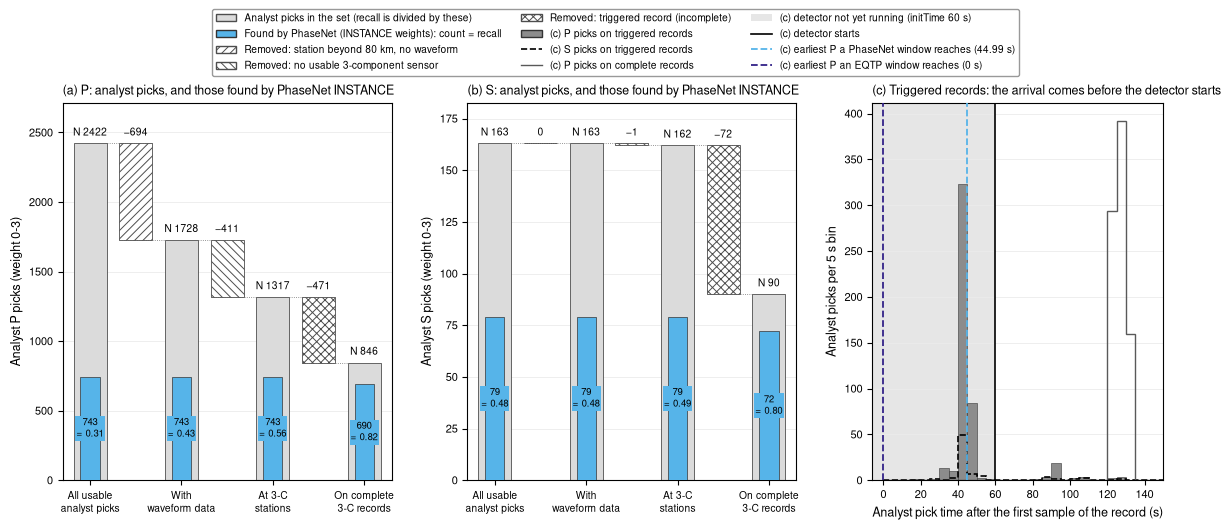

In [6]:
# Figure 1: analyst picks by what the station offers; recall over the four sets of picks
RADIUS_IN = REF[REF.has_data].dist_km.max()
RADIUS_OUT = REF[~REF.has_data].dist_km.min()
NT = REF.groupby(["phase", "tier"]).size()
chk("playback radius: every analyst pick with data within it, every pick without data beyond it", [RADIUS_IN <= PLAYBACK_KM, RADIUS_OUT > PLAYBACK_KM], [1, 1], 0)
STEPS = [("all", "All usable\nanalyst picks", None), ("no_data", "", "no_data"),
         ("with_data", "With\nwaveform data", None), ("no_3c_sensor", "", "no_3c_sensor"),
         ("3c", "At 3-C\nstations", None), ("3c_incomplete", "", "3c_incomplete"),
         ("3c_complete", "On complete\n3-C records", None)]
HATCH = {"no_data": "////", "no_3c_sensor": "\\\\\\\\", "3c_incomplete": "xxxx"}
fig = plt.figure(figsize=(14.2, 4.9))
gs = fig.add_gridspec(1, 3, width_ratios=[1.3, 1.3, 1.15], wspace=0.24)
axs = [fig.add_subplot(gs[0, i]) for i in range(3)]
FIG1 = {}
for k, ph in enumerate(PH):
    ax = axs[k]
    n = {t: int(NT.get((ph, t), 0)) for t in TIERS}
    level = {"all": sum(n.values())}
    level["with_data"] = level["all"] - n["no_data"]
    level["3c"] = level["with_data"] - n["no_3c_sensor"]
    level["3c_complete"] = level["3c"] - n["3c_incomplete"]
    assert level["3c_complete"] == n["3c_complete"]
    ymax = level["all"]
    prev = None
    for i, (key, lab, drop) in enumerate(STEPS):
        if drop is None:
            N = level[key]
            found = int(ALL.loc[(BEST_MODEL, ph), f"n_matched_{key}"])
            assert int(ALL.loc[(BEST_MODEL, ph), f"n_ref_{key}"]) == N
            ax.bar(i, N, width=0.72, color="0.86", edgecolor="0.3", lw=0.6, zorder=2)
            ax.bar(i, found, width=0.42, color=COL[BEST_MODEL], edgecolor="0.2", lw=0.5, zorder=3)
            ax.text(i, N + 0.015 * ymax, f"N {N}", ha="center", va="bottom", fontsize=7.4, zorder=5)
            ax.text(i, found / 2.0, f"{found}\n= {found / N:.2f}", ha="center", va="center", fontsize=6.8, zorder=5,
                    color=h.text_color_on(COL[BEST_MODEL]),
                    bbox=dict(boxstyle="square,pad=0.12", fc=COL[BEST_MODEL], ec="none") if found / ymax > 0.06 else None)
            FIG1[(ph, key)] = (found, N)
            if prev is not None:
                ax.plot([i - 1.36, i - 0.36], [N, N], color="0.45", lw=0.6, ls=":", zorder=1)
            prev = N
        else:
            ax.bar(i, n[drop], bottom=prev - n[drop], width=0.72, color="white", edgecolor="0.3", hatch=HATCH[drop], lw=0.6, zorder=2)
            ax.plot([i - 0.64, i + 0.36], [prev, prev], color="0.45", lw=0.6, ls=":", zorder=1)
            ax.text(i, prev + 0.015 * ymax, f"−{n[drop]}" if n[drop] else "0", ha="center", va="bottom", fontsize=7.4, zorder=5)
    full = [i for i, s_ in enumerate(STEPS) if s_[2] is None]
    ax.set_xticks(full)
    ax.set_xticklabels([STEPS[i][1] for i in full], fontsize=7.4)
    ax.set_xlim(-0.6, len(STEPS) - 0.4)
    ax.set_ylim(0, ymax * 1.12)
    ax.grid(axis="y", color="0.92", lw=0.6, zorder=0)
    ax.set_ylabel(f"Analyst {ph} picks (weight 0-3)")
    ax.set_title(f"{ph}: analyst picks, and those found by {SHORT[BEST_MODEL]}", loc="left")
# (c) triggered records: when did the analyst pick come after the first sample?
ax = axs[2]
inc = REF[REF.tier == "3c_incomplete"].copy()
inc["after_start"] = inc.t_rel_origin_s - inc.record_start_rel_origin_s
com = REF[(REF.tier == "3c_complete") & (REF.phase == "P")].copy()
com["after_start"] = com.t_rel_origin_s - com.record_start_rel_origin_s
edges = np.arange(0.0, TRIG_XMAX_S + TRIG_BIN_S, TRIG_BIN_S)
ax.axvspan(-10, INIT_TIME_S, color="0.9", lw=0, zorder=0)
ax.hist(inc[inc.phase == "P"].after_start.clip(upper=TRIG_XMAX_S - 1e-6), bins=edges, color="0.55", edgecolor="0.2", lw=0.4, zorder=2)
ax.hist(inc[inc.phase == "S"].after_start.clip(upper=TRIG_XMAX_S - 1e-6), bins=edges, histtype="step", color="k", lw=1.2, ls="--", zorder=3)
ax.hist(com.after_start.clip(upper=TRIG_XMAX_S - 1e-6), bins=edges, histtype="step", color="0.35", lw=1.0, zorder=3)
ax.axvline(INIT_TIME_S, color="k", lw=1.2, zorder=4)
REACH = {v: INIT_TIME_S + PWIN[v][0] for v in MODELS}
reach_pn = sorted({round(REACH[v], 2) for v in MODELS if not v.startswith("eqtp")})
for x_ in reach_pn:
    ax.axvline(x_, color=COL["phasenet_instance"], lw=1.3, ls="--", zorder=4)
ax.axvline(REACH["eqtp_ncedc"], color=COL["eqtp_ncedc"], lw=1.3, ls="--", zorder=4)
ax.set_xlim(-6, TRIG_XMAX_S)
ax.set_xlabel("Analyst pick time after the first sample of the record (s)")
ax.set_ylabel(f"Analyst picks per {TRIG_BIN_S:g} s bin")
ax.set_title("Triggered records: the arrival comes before the detector starts", loc="left")
ax.grid(axis="y", color="0.92", lw=0.6, zorder=0)
for k_, a in enumerate(axs):
    h.panel_letter(a, "abc"[k_])
h.boxed(axs)
hs = [Patch(facecolor="0.86", edgecolor="0.3"), Patch(facecolor=COL[BEST_MODEL], edgecolor="0.2")] + \
     [Patch(facecolor="white", edgecolor="0.3", hatch=HATCH[t]) for t in ("no_data", "no_3c_sensor", "3c_incomplete")] + \
     [Patch(facecolor="0.55", edgecolor="0.2"), Line2D([], [], color="k", lw=1.2, ls="--"), Line2D([], [], color="0.35", lw=1.0),
      Patch(facecolor="0.9", edgecolor="none"), Line2D([], [], color="k", lw=1.2),
      Line2D([], [], color=COL["phasenet_instance"], lw=1.3, ls="--"), Line2D([], [], color=COL["eqtp_ncedc"], lw=1.3, ls="--")]
ls = ["Analyst picks in the set (recall is divided by these)", f"Found by {LABEL[BEST_MODEL]}: count = recall",
      f"Removed: station beyond {PLAYBACK_KM:g} km, no waveform", "Removed: no usable 3-component sensor",
      "Removed: triggered record (incomplete)", "(c) P picks on triggered records", "(c) S picks on triggered records",
      "(c) P picks on complete records", f"(c) detector not yet running (initTime {INIT_TIME_S:g} s)", "(c) detector starts",
      f"(c) earliest P a PhaseNet window reaches ({reach_pn[0]:g} s)",
      f"(c) earliest P an EQTP window reaches ({REACH['eqtp_ncedc']:g} s)"]
h.legend_above(fig, axs, hs, ls, ncol=3, fontsize=7.3)
FIGS["1"] = h.save_fig(fig, FIG_DIR, "07_1_reachable_analyst_picks")
plt.show()

In [7]:
# Figure 1: what it says (numbers from the files)
n3 = REF[REF.tier == "no_3c_sensor"]
nostat = STB[STB.bound == "0"]
n_vert = int(nostat.not_bound_reason.str.contains(r"only component\(s\) Z").sum())
p_inc = inc[inc.phase == "P"]
early = int((p_inc.after_start < INIT_TIME_S).sum())
trig_rec = COV[(COV.role == "main") & (COV.complete == 0)]
rt = BYTIER[(BYTIER.value == "3c_incomplete") & (BYTIER.phase == "P") & BYTIER.variant.isin(MODELS)].set_index("variant").recall_3c
lines = [
    f"- **{int(NT.loc[('P', 'no_data')])} P picks** are at stations {RADIUS_OUT:.0f}-{REF[~REF.has_data].dist_km.max():.0f} km away; "
    f"the playback files hold every sensor within {PLAYBACK_KM:g} km (the farthest analyst pick with data is at {RADIUS_IN:.1f} km), "
    "so these have no waveform by design.",
    f"- **{len(n3)} picks ({(n3.phase == 'P').sum()} P, {(n3.phase == 'S').sum()} S) are at stations with data but no usable "
    f"3-component sensor**: {int((n3.ch_type == 'EH').sum())} on vertical-only EH channels, "
    f"{int(n3.ch_type.isin(['DP', 'CN']).sum())} on the two-component borehole {', '.join(sorted(n3[n3.ch_type.isin(['DP', 'CN'])].nsta.unique()))}, "
    f"{int((n3.ch_type == 'EL').sum())} on a horizontal-only EL sensor. {len(nostat)} stations were not bound, {n_vert} of them "
    "because they deliver only a vertical channel.",
    f"- **{len(p_inc)} P and {int((inc.phase == 'S').sum())} S picks are on triggered records.** These "
    f"records ({len(trig_rec)} of {int((COV.role == 'main').sum())} station-event records of the main set) start a median "
    f"{-trig_rec.start_rel_origin_s.median():.0f} s before the origin. {early} of the {len(p_inc)} P picks come less than "
    f"initTime = {INIT_TIME_S:g} s after the first sample (panel c), so the detector was not yet running. Recall on these records "
    f"is {rt.drop('eqtp_ncedc').min():.2f}-{rt.drop('eqtp_ncedc').max():.2f} for the PhaseNet models and {rt['eqtp_ncedc']:.2f} for EQTP, "
    f"whose {PWIN['eqtp_ncedc'][1] - PWIN['eqtp_ncedc'][0]:g}-s window reaches {-PWIN['eqtp_ncedc'][0]:g} s back from a later trigger.",
    f"- **So the same found picks give very different recalls.** {SHORT[BEST_MODEL]} found {FIG1[('P', 'all')][0]} analyst P picks: "
    + ", ".join(f"{FIG1[('P', k)][0]}/{FIG1[('P', k)][1]} = {FIG1[('P', k)][0] / FIG1[('P', k)][1]:.2f}" for k in ("all", "with_data", "3c", "3c_complete"))
    + " over the four sets. The number found hardly changes; the set it is divided by shrinks. "
    f"For S: " + ", ".join(f"{FIG1[('S', k)][0]}/{FIG1[('S', k)][1]} = {FIG1[('S', k)][0] / FIG1[('S', k)][1]:.2f}" for k in ("all", "with_data", "3c", "3c_complete")) + ".",
    "- **Recall over all picks measures this data set and this test; recall on complete records measures the picker.** "
    "The first is limited by the station types and by the triggered recorders, which a real-time system would not stream anyway.",
]
display(Markdown("\n".join(lines)))

- **694 P picks** are at stations 82-405 km away; the playback files hold every sensor within 80 km (the farthest analyst pick with data is at 78.9 km), so these have no waveform by design.
- **412 picks (411 P, 1 S) are at stations with data but no usable 3-component sensor**: 398 on vertical-only EH channels, 13 on the two-component borehole BK.RB2B, 1 on a horizontal-only EL sensor. 36 stations were not bound, 35 of them because they deliver only a vertical channel.
- **471 P and 72 S picks are on triggered records.** These records (1502 of 3291 station-event records of the main set) start a median 36 s before the origin. 435 of the 471 P picks come less than initTime = 60 s after the first sample (panel c), so the detector was not yet running. Recall on these records is 0.08-0.11 for the PhaseNet models and 0.19 for EQTP, whose 120-s window reaches 60 s back from a later trigger.
- **So the same found picks give very different recalls.** PhaseNet INSTANCE found 743 analyst P picks: 743/2422 = 0.31, 743/1728 = 0.43, 743/1317 = 0.56, 690/846 = 0.82 over the four sets. The number found hardly changes; the set it is divided by shrinks. For S: 79/163 = 0.48, 79/163 = 0.48, 79/162 = 0.49, 72/90 = 0.80.
- **Recall over all picks measures this data set and this test; recall on complete records measures the picker.** The first is limited by the station types and by the triggered recorders, which a real-time system would not stream anyway.

## 3. Figure 2: recall and precision per model

**What is shown.** (a) and (b): recall of each model for P and for S, over the four sets of analyst picks of
Figure 1; N under each group is the number of analyst picks in that set. (c): precision for P and S, the share of the
DL picks inside the event windows that match an analyst pick (bars, a lower bound), and with a black line the
precision counting plausible arrivals (an upper bound). The numbers on the precision bars are matched / all DL picks
in the windows.

**How to read it.** Compare models within one group of bars. For S, the analysts picked so few arrivals that the
precision against them says almost nothing about the picker: most DL S picks simply have no analyst S to be compared
with. Step 12 chose its best model by a rule fixed before any result was seen: the highest F1 of P and S pooled (recall
over 3-C stations, precision as in panel c) among the four models of the main set.

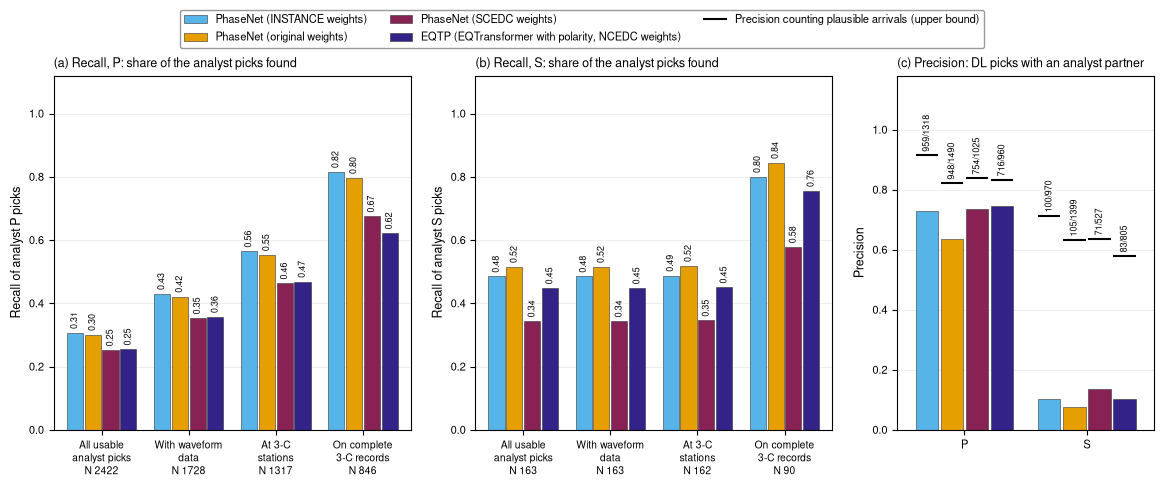

n_ref_all  recall_all  recall_with_data  recall_3c  n_ref_3c_complete  recall_3c_complete  n_dl_in_window  precision  precision_counting_plausible     f1
variant           phase                                                                                                                                                           
phasenet_instance P           2422       0.307             0.430      0.564                846               0.816            1318      0.728                         0.914  0.636
                  S            163       0.485             0.485      0.488                 90               0.800             970      0.103                         0.712  0.170
                  P+S         2585       0.318             0.435      0.556                936               0.814            2288      0.463                         0.829  0.505
phasenet_original P           2422       0.301             0.421      0.553                846               0.797            1490      0.636                         0.822  0.592
                  S            163       0.515             0.515      0.518                 90               0.844            1399      0.075                         0.632  0.131
                  P+S         2585       0.314             0.429      0.549                936               0.801            2889      0.364                         0.730  0.438
phasenet_scedc    P           2422       0.252             0.353      0.463                846               0.675            1025      0.736                         0.838  0.568
                  S            163       0.344             0.344      0.346                 90               0.578             527      0.135                         0.636  0.194
                  P+S         2585       0.258             0.352      0.450                936               0.666            1552      0.532                         0.769  0.488
eqtp_ncedc        P           2422       0.255             0.357      0.468                846               0.622             960      0.746                         0.832  0.576
                  S            163       0.448             0.448      0.451                 90               0.756             805      0.103                         0.579  0.168
                  P+S         2585       0.267             0.365      0.466                936               0.635            1765      0.453                         0.717  0.460

In [8]:
# Figure 2: recall over the four sets of analyst picks, and precision
DEN = [("all", "All usable\nanalyst picks"), ("with_data", "With waveform\ndata"), ("3c", "At 3-C\nstations"),
       ("3c_complete", "On complete\n3-C records")]
nm = len(MODELS)
w = 0.82 / nm
fig = plt.figure(figsize=(14.2, 4.6))
gs = fig.add_gridspec(1, 3, width_ratios=[1.25, 1.25, 0.9], wspace=0.2)
axs = [fig.add_subplot(gs[0, i]) for i in range(3)]
for k, ph in enumerate(PH):
    ax = axs[k]
    for j, v in enumerate(MODELS):
        for i, (key, lab) in enumerate(DEN):
            r = ALL.loc[(v, ph)]
            x = i + (j - (nm - 1) / 2.0) * w
            ax.bar(x, r[f"recall_{key}"], width=w * 0.9, color=COL[v], edgecolor="0.2", lw=0.4, zorder=2)
            ax.text(x, r[f"recall_{key}"] + 0.012, f"{r[f'recall_{key}']:.2f}", rotation=90, ha="center", va="bottom", fontsize=6.4, zorder=4)
    ax.set_xticks(range(len(DEN)))
    ax.set_xticklabels([f"{lab}\nN {int(ALL.loc[(MODELS[0], ph), f'n_ref_{key}'])}" for key, lab in DEN], fontsize=7.4)
    ax.set_xlim(-0.55, len(DEN) - 0.45)
    ax.set_ylim(0, 1.12)
    ax.set_yticks(np.arange(0, 1.01, 0.2))
    ax.grid(axis="y", color="0.92", lw=0.6, zorder=0)
    ax.set_ylabel(f"Recall of analyst {ph} picks")
    ax.set_title(f"Recall, {ph}: share of the analyst picks found", loc="left")
ax = axs[2]
for j, v in enumerate(MODELS):
    for i, ph in enumerate(PH):
        r = ALL.loc[(v, ph)]
        x = i + (j - (nm - 1) / 2.0) * w
        ax.bar(x, r.precision, width=w * 0.9, color=COL[v], edgecolor="0.2", lw=0.4, zorder=2)
        ax.plot([x - 0.45 * w, x + 0.45 * w], [r.precision_counting_plausible] * 2, color="k", lw=1.5, zorder=3, solid_capstyle="butt")
        ax.text(x, max(r.precision, r.precision_counting_plausible) + 0.012, f"{int(r.n_dl_matched_any_event)}/{int(r.n_dl_in_window)}",
                rotation=90, ha="center", va="bottom", fontsize=6.4, zorder=4)
ax.set_xticks(range(len(PH)))
ax.set_xticklabels(["P", "S"])
ax.set_xlim(-0.55, len(PH) - 0.45)
ax.set_ylim(0, 1.18)
ax.set_yticks(np.arange(0, 1.01, 0.2))
ax.grid(axis="y", color="0.92", lw=0.6, zorder=0)
ax.set_ylabel("Precision")
ax.set_title("Precision: DL picks with an analyst partner", loc="left")
for k_, a in enumerate(axs):
    h.panel_letter(a, "abc"[k_])
h.boxed(axs)
hs = [Patch(facecolor=COL[v], edgecolor="0.2", lw=0.4) for v in MODELS] + [Line2D([], [], color="k", lw=1.5)]
ls = [LABEL[v] for v in MODELS] + ["Precision counting plausible arrivals (upper bound)"]
h.legend_above(fig, axs, hs, ls, ncol=3)
FIGS["2"] = h.save_fig(fig, FIG_DIR, "07_2_recall_precision")
plt.show()
cols = ["n_ref_all", "recall_all", "recall_with_data", "recall_3c", "n_ref_3c_complete", "recall_3c_complete", "n_dl_in_window",
        "precision", "precision_counting_plausible", "f1"]
display(ALL.loc[[(v, p) for v in MODELS for p in PH + ["P+S"]], cols].round(3))

In [9]:
# Figure 2: what it says (numbers from the files)
RCOMP = "recall_3c_complete"
pP = ALL.xs("P", level="phase").loc[MODELS]
pS = ALL.xs("S", level="phase").loc[MODELS]
pooled = ALL.xs("P+S", level="phase").loc[MODELS]
rk = pd.DataFrame(BEST["ranking"]).set_index("variant")
lines = [
    "- **On complete 3-C records** P recall is " + ", ".join(f"{SHORT[v]} {pP.loc[v, RCOMP]:.2f}" for v in MODELS)
    + "; S recall " + ", ".join(f"{SHORT[v]} {pS.loc[v, RCOMP]:.2f}" for v in MODELS)
    + f" (over only {int(pS.n_ref_3c_complete.iloc[0])} analyst S picks).",
    f"- **P precision** (lower bound) is {pP.precision.min():.2f}-{pP.precision.max():.2f}; counting plausible arrivals it rises to "
    f"{pP.precision_counting_plausible.min():.2f}-{pP.precision_counting_plausible.max():.2f}. "
    f"{SHORT[pP.n_dl_in_window.idxmax()]} makes the most P picks inside the windows ({int(pP.n_dl_in_window.max())}) and has the lowest P "
    f"precision ({pP.loc[pP.n_dl_in_window.idxmax(), 'precision']:.2f}).",
    f"- **S precision against the analysts is {pS.precision.min():.2f}-{pS.precision.max():.2f}** only because the analysts picked S at "
    f"{int(pS.n_ref_all.iloc[0])} station-events against {int(pP.n_ref_all.iloc[0])} for P; counting plausible arrivals it is "
    f"{pS.precision_counting_plausible.min():.2f}-{pS.precision_counting_plausible.max():.2f}.",
    f"- **Best model by the fixed rule: {BEST_MODEL}**, pooled F1 {rk.loc[BEST_MODEL, 'f1']:.3f}; then "
    + ", ".join(f"{v} {rk.loc[v, 'f1']:.3f}" for v in rk.index[1:]) + ". For P alone the order is "
    + ", ".join(f"{v} {pP.loc[v, 'f1']:.3f}" for v in pP.f1.sort_values(ascending=False).index) + ".",
]
display(Markdown("\n".join(lines)))

- **On complete 3-C records** P recall is PhaseNet INSTANCE 0.82, PhaseNet original 0.80, PhaseNet SCEDC 0.67, EQTP NCEDC 0.62; S recall PhaseNet INSTANCE 0.80, PhaseNet original 0.84, PhaseNet SCEDC 0.58, EQTP NCEDC 0.76 (over only 90 analyst S picks).
- **P precision** (lower bound) is 0.64-0.75; counting plausible arrivals it rises to 0.82-0.91. PhaseNet original makes the most P picks inside the windows (1490) and has the lowest P precision (0.64).
- **S precision against the analysts is 0.08-0.13** only because the analysts picked S at 163 station-events against 2422 for P; counting plausible arrivals it is 0.58-0.71.
- **Best model by the fixed rule: phasenet_instance**, pooled F1 0.505; then phasenet_scedc 0.488, eqtp_ncedc 0.460, phasenet_original 0.438. For P alone the order is phasenet_instance 0.635, phasenet_original 0.592, eqtp_ncedc 0.576, phasenet_scedc 0.568.

## 4. Figure 3: how far are the DL pick times from the analyst pick times?

**What is shown.** Top row: for every matched P pair, dt = DL pick time − analyst pick time, one panel per model,
in bins of one sample (0.01 s) from −0.3 to +0.3 s (pairs beyond are counted in the panel).
The filled histogram holds all matched P pairs; the black step line holds only the pairs whose analyst pick has
weight code 0 (the onsets the analyst was most sure about). The gray vertical line is the median dt of all pairs.
Bottom row: P recall over the analyst picks at 3-C stations, the median |dt| and the p95 |dt|, by the analyst's
weight code (0 = most sure, 3 = least sure); N is the number of analyst P picks of that weight code at 3-C stations.

**How to read it.** A model that picks consistently earlier or later than the analysts shows a shifted histogram; a
constant shift of a few hundredths of a second cancels in double-difference relocation if all events are picked by
the same model. The width at weight code 0 is the best measure of the model's own timing; for weight codes 2 and 3
the width mostly reflects the analysts' uncertainty.

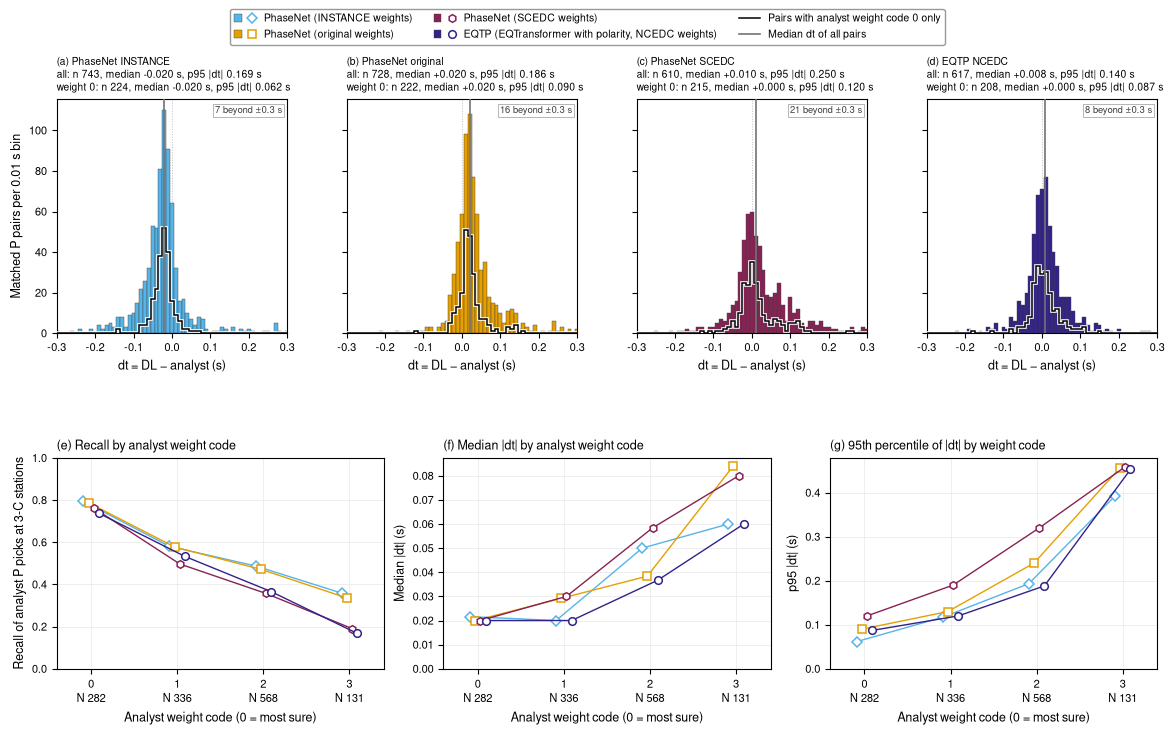

In [10]:
# Figure 3: dt = DL - analyst of the matched P pairs, all and weight-0 only; and by weight code
import matplotlib.patheffects as pe_
from matplotlib.legend_handler import HandlerTuple
MP = RVD[RVD.matched & (RVD.phase == "P") & RVD.variant.isin(MODELS)]
edges = np.arange(-DT_XLIM_S - DT_BIN_S / 2.0, DT_XLIM_S + DT_BIN_S, DT_BIN_S)
fig = plt.figure(figsize=(14.2, 7.4))
gs = fig.add_gridspec(2, 12, height_ratios=[1.0, 0.9], hspace=0.56, wspace=1.6)
top = [fig.add_subplot(gs[0, 3 * j:3 * j + 3]) for j in range(nm)]
for a in top[1:]:
    a.sharey(top[0])
bot = [fig.add_subplot(gs[1, 4 * j:4 * j + 4]) for j in range(3)]
DTS = {}
for j, v in enumerate(MODELS):
    ax = top[j]
    d = MP[MP.variant == v]
    a_all, a_w0 = d.dt_s.to_numpy(), d[d.weight_code == 0].dt_s.to_numpy()
    s_all, s_w0 = C12.dtstats(a_all), C12.dtstats(a_w0)
    DTS[v] = dict(all=s_all, w0=s_w0, beyond=int((np.abs(a_all) > DT_XLIM_S).sum()))
    ax.hist(a_all[np.abs(a_all) <= DT_XLIM_S], bins=edges, color=COL[v], edgecolor="0.25", lw=0.3, zorder=2)
    _, _, stp = ax.hist(a_w0[np.abs(a_w0) <= DT_XLIM_S], bins=edges, histtype="step", color="k", lw=1.1, zorder=3)
    for p_ in stp:
        p_.set_path_effects([pe_.withStroke(linewidth=2.6, foreground="white")])
    ax.axvline(0.0, color="0.75", lw=0.7, ls=":", zorder=1)
    ax.axvline(s_all["median_dt_s"], color="0.45", lw=1.2, zorder=4)
    ax.set_xlim(-DT_XLIM_S, DT_XLIM_S)
    ax.set_title(f"{SHORT[v]}\nall: n {s_all['n_dt']}, median {s_all['median_dt_s']:+.3f} s, p95 |dt| {s_all['p95_abs_dt_s']:.3f} s\n"
                 f"weight 0: n {s_w0['n_dt']}, median {s_w0['median_dt_s']:+.3f} s, p95 |dt| {s_w0['p95_abs_dt_s']:.3f} s",
                 loc="left", fontsize=7.4)
    if DTS[v]["beyond"]:
        ax.text(0.98, 0.97, f"{DTS[v]['beyond']} beyond ±{DT_XLIM_S:g} s", transform=ax.transAxes, ha="right", va="top",
                fontsize=6.8, color="0.25", zorder=6, bbox=dict(boxstyle="square,pad=0.2", fc="white", ec="0.6", lw=0.5))
    ax.set_xlabel("dt = DL − analyst (s)")
    if j == 0:
        ax.set_ylabel(f"Matched P pairs per {DT_BIN_S:g} s bin")
    else:
        ax.tick_params(labelleft=False)
WC = [0, 1, 2, 3]
bw = BYW[(BYW.phase == "P") & BYW.variant.isin(MODELS)].copy()
bw["wc"] = bw["value"].astype(int)
for k, (col_, ylab, ttl) in enumerate((("recall_3c", "Recall of analyst P picks at 3-C stations", "Recall by analyst weight code"),
                                       ("median_abs_dt_s", "Median |dt| (s)", "Median |dt| by analyst weight code"),
                                       ("p95_abs_dt_s", "p95 |dt| (s)", "95th percentile of |dt| by weight code"))):
    ax = bot[k]
    for j, v in enumerate(MODELS):
        q = bw[bw.variant == v].set_index("wc").loc[WC]
        ax.plot(np.array(WC) + (j - 1.5) * 0.06, q[col_], color=COL[v], marker=MARK[v], mfc="white", mec=COL[v], mew=1.1, ms=5.5,
                lw=1.0, zorder=3)
    n_ = bw[bw.variant == MODELS[0]].set_index("wc").loc[WC].n_ref_3c
    ax.set_xticks(WC)
    ax.set_xticklabels([f"{c}\nN {int(n)}" for c, n in zip(WC, n_)])
    ax.set_xlim(-0.4, 3.4)
    ax.set_xlabel("Analyst weight code (0 = most sure)")
    ax.set_ylabel(ylab)
    ax.set_title(ttl, loc="left")
    ax.grid(color="0.92", lw=0.6, zorder=0)
    if col_ == "recall_3c":
        ax.set_ylim(0, 1.0)
    else:
        ax.set_ylim(0, None)
for k_, a in enumerate(top + bot):
    h.panel_letter(a, "abcdefg"[k_])
h.boxed(top + bot)
hs = [(Patch(facecolor=COL[v], edgecolor="0.25", lw=0.3), Line2D([], [], ls="none", marker=MARK[v], color=COL[v], mec=COL[v], mfc="white", mew=1.1, ms=5.5))
      for v in MODELS] + [Line2D([], [], color="k", lw=1.1), Line2D([], [], color="0.45", lw=1.2)]
ls = [LABEL[v] for v in MODELS] + ["Pairs with analyst weight code 0 only", "Median dt of all pairs"]
h.legend_above_kw(fig, top, hs, ls, ncol=3, fontsize=7.6, handler_map={tuple: HandlerTuple(ndivide=None, pad=0.6)})
FIGS["3"] = h.save_fig(fig, FIG_DIR, "07_3_pick_time_differences")
plt.show()
for v in MODELS:
    assert abs(DTS[v]["all"]["median_abs_dt_s"] - ALL.loc[(v, "P"), "median_abs_dt_s"]) < 2e-4

In [11]:
# Figure 3: what it says
D3 = pd.DataFrame({v: {"median dt (s)": DTS[v]["all"]["median_dt_s"], "mean dt (s)": DTS[v]["all"]["mean_dt_s"],
                       "median |dt| (s)": DTS[v]["all"]["median_abs_dt_s"], "p95 |dt| (s)": DTS[v]["all"]["p95_abs_dt_s"],
                       "weight 0: n": DTS[v]["w0"]["n_dt"], "weight 0: median |dt| (s)": DTS[v]["w0"]["median_abs_dt_s"],
                       "weight 0: p95 |dt| (s)": DTS[v]["w0"]["p95_abs_dt_s"]} for v in MODELS}).T
display(D3.round(3))
bwi = bw.set_index(["variant", "wc"])
lines = [
    f"- **The typical difference is two to three samples:** median |dt| {D3['median |dt| (s)'].min():.3f}-{D3['median |dt| (s)'].max():.3f} s "
    f"for all matched P pairs, {D3['weight 0: median |dt| (s)'].min():.3f}-{D3['weight 0: median |dt| (s)'].max():.3f} s at weight code 0.",
    f"- **Where the analyst was sure, agreement is tight:** p95 |dt| {D3['weight 0: p95 |dt| (s)'].min():.3f}-{D3['weight 0: p95 |dt| (s)'].max():.3f} s "
    f"at weight code 0, against {D3['p95 |dt| (s)'].min():.3f}-{D3['p95 |dt| (s)'].max():.3f} s over all pairs.",
    "- **Each model has its own offset** (mean dt): " + ", ".join(f"{SHORT[v]} {1000 * D3.loc[v, 'mean dt (s)']:+.0f} ms" for v in MODELS)
    + ". A constant offset cancels in double differences, but mixing models between events would not.",
    "- **The less sure the analyst, the fewer matches and the larger the differences:** P recall at 3-C stations falls from "
    + ", ".join(f"{bwi.loc[(v, 0), 'recall_3c']:.2f}" for v in MODELS) + " (weight 0) to "
    + ", ".join(f"{bwi.loc[(v, 3), 'recall_3c']:.2f}" for v in MODELS) + f" (weight 3), in the order {', '.join(SHORT[v] for v in MODELS)}.",
]
display(Markdown("\n".join(lines)))

,median dt (s),mean dt (s),median |dt| (s),p95 |dt| (s),weight 0: n,weight 0: median |dt| (s),weight 0: p95 |dt| (s)
phasenet_instance,-0.020,-0.020,0.030,0.169,224.0,0.022,0.062
phasenet_original,0.020,0.042,0.028,0.186,222.0,0.020,0.090
phasenet_scedc,0.010,0.034,0.032,0.250,215.0,0.020,0.120
eqtp_ncedc,0.008,0.014,0.022,0.140,208.0,0.020,0.087


- **The typical difference is two to three samples:** median |dt| 0.022-0.032 s for all matched P pairs, 0.020-0.022 s at weight code 0.
- **Where the analyst was sure, agreement is tight:** p95 |dt| 0.062-0.120 s at weight code 0, against 0.140-0.250 s over all pairs.
- **Each model has its own offset** (mean dt): PhaseNet INSTANCE -20 ms, PhaseNet original +42 ms, PhaseNet SCEDC +34 ms, EQTP NCEDC +14 ms. A constant offset cancels in double differences, but mixing models between events would not.
- **The less sure the analyst, the fewer matches and the larger the differences:** P recall at 3-C stations falls from 0.79, 0.79, 0.76, 0.74 (weight 0) to 0.36, 0.34, 0.19, 0.17 (weight 3), in the order PhaseNet INSTANCE, PhaseNet original, PhaseNet SCEDC, EQTP NCEDC.

## 5. Figure 4: the swarm costs picks when two events come seconds apart

**Why.** In a swarm, two events often lie a few seconds apart. The plugin runs one P window per detector trigger and
keeps only the most confident P peak in it. A window that covers both onsets keeps the larger one, and the detector's
dead time then usually stops the second onset from starting its own picker. The smaller event of a close pair loses its
P picks, even though both onsets are clear.

**What is shown.** (a) P recall on complete 3-C records for each event that has another NCSS catalog event in its
playback file, one column per event, sorted by the time to that nearest other event (the tick label gives the event,
its magnitude, the neighbour's magnitude and time relative to the origin, and N, the number of analyst P picks on
complete records). The last column holds the events with no other catalog event within 120 s: small markers per
event, and a short thick bar for all of them pooled. The shaded columns have a neighbour within 15 s.
(b) the same pooled by step 12's four neighbour classes. (c) one station of the foreshock 72540760, which came
seconds before the mainshock 72540765: the three components band-passed 2-20 Hz
(causal, 4-corner Butterworth, the band of step 12's SNR measurement), aligned on the station's analyst
P pick of the foreshock and each scaled to its own maximum in the view. Blue lines are the analyst picks of both
events (P solid, S dashed). Above the traces, one row per model with the picks of the foreshock run: a filled marker is
a P pick, an open marker with "S" an S pick, and the text says which analyst pick it matched. The thin line in each row
is the P window that covered the foreshock P (from the run's debug log; the short vertical tick is its trigger).

**How the station was chosen (a rule, not by eye).** Among the stations with a complete 3-C record of the foreshock
and an analyst P pick of both events, where phasenet_instance missed the foreshock P with the reason "window picked
another time", the one with the highest signal-to-noise ratio at the foreshock P.

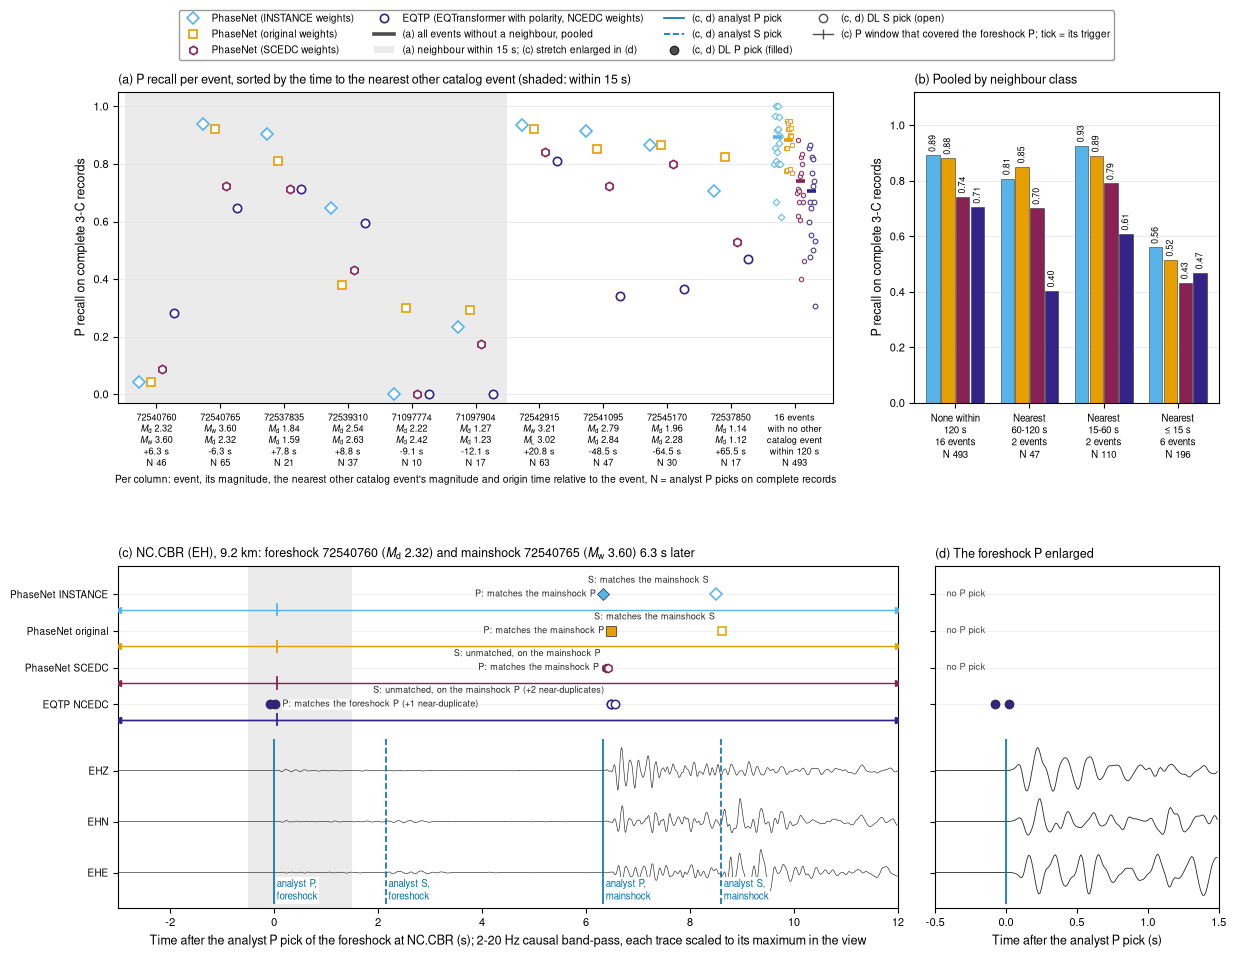

station rule, candidates (highest SNR first):


,nsta,channel,main_sensor,dist_km,snr_db_bound_sensor,weight_code,best_value_in_covering_windows
2492,NC.CBR,EHZ,EH,9.208,56.441,0,0.96
2493,NC.CRH,EHZ,HN,7.752,40.234,1,0.93
2503,BK.SM2B,CN1,CN,13.942,39.610,0,0.96
2517,NC.CNI,EHZ,EH,20.559,38.680,0,0.93
2500,NC.CCH1,EP1,EP,13.031,36.743,0,0.97
2514,BK.BDM,HHZ,HH,19.788,35.324,0,0.92


,variant,kind,start_s,end_s,trigger_s,kept_value,matched,what
0,phasenet_instance,DL P pick,6.33,NaN,NaN,0.962,True,P: matches the mainshock P
1,phasenet_instance,DL S pick,8.50,NaN,NaN,0.819,True,S: matches the mainshock S
2,phasenet_original,DL P pick,6.49,NaN,NaN,0.927,True,P: matches the mainshock P
3,phasenet_original,DL S pick,8.62,NaN,NaN,0.847,True,S: matches the mainshock S
4,phasenet_scedc,DL P pick,6.39,NaN,NaN,0.569,True,P: matches the mainshock P
5,phasenet_scedc,DL S pick,6.42,NaN,NaN,0.485,False,"S: unmatched, on the mainshock P"
6,eqtp_ncedc,DL P pick,-0.08,NaN,NaN,0.602,False,"P: unmatched, on the foreshock P"
7,eqtp_ncedc,DL P pick,0.02,NaN,NaN,0.896,True,P: matches the foreshock P
8,eqtp_ncedc,DL S pick,6.49,NaN,NaN,0.847,False,"S: unmatched, on the mainshock P"
9,eqtp_ncedc,DL S pick,6.49,NaN,NaN,0.797,False,"S: unmatched, on the mainshock P"


In [12]:
# Figure 4: P recall per event against the nearest other catalog event; the neighbour classes; one foreshock station
pe = BYEV[(BYEV.phase == "P") & BYEV.variant.isin(MODELS)].copy()
pe["dtn"] = pe.event_id.map(NBR.nearest_dt_s)
nb_ev = NBR[NBR.nearest_dt_s.notna()].copy()
nb_ev["absdt"] = nb_ev.nearest_dt_s.abs()
nb_ev = nb_ev.sort_values(["absdt", "mag"])
none_ev = list(NBR.index[NBR.nearest_dt_s.isna()])
COLS4 = list(nb_ev.index) + ["none"]
ncomp = pe[pe.variant == MODELS[0]].set_index("event_id").n_ref_3c_complete


def ev_tick(e):
    r = NBR.loc[e]
    nbm = h.mag_label(r.nearest_mag, MAGT.get(r.nearest_other_event, "?"))
    return f"{e}\n{MLAB[e]}\n{nbm}\n{r.nearest_dt_s:+.1f} s\nN {int(ncomp[e])}"


fig = plt.figure(figsize=(14.2, 10.6))
outer = fig.add_gridspec(2, 1, height_ratios=[1.0, 1.1], hspace=0.5)
g_top = outer[0].subgridspec(1, 2, width_ratios=[2.35, 1.0], wspace=0.16)
g_bot = outer[1].subgridspec(1, 2, width_ratios=[2.75, 1.0], wspace=0.07)
axA, axB = fig.add_subplot(g_top[0]), fig.add_subplot(g_top[1])
axC, axD = fig.add_subplot(g_bot[0]), fig.add_subplot(g_bot[1])
offs = np.linspace(-0.27, 0.27, nm)
for i, e in enumerate(COLS4[:-1]):
    if abs(NBR.loc[e, "nearest_dt_s"]) <= NEAR_S:
        axA.axvspan(i - 0.5, i + 0.5, color="0.92", lw=0, zorder=0)
for j, v in enumerate(MODELS):
    q = pe[pe.variant == v].set_index("event_id")
    xs_ = np.arange(len(COLS4) - 1) + offs[j]
    axA.plot(xs_, q.loc[COLS4[:-1], RCOMP], ls="none", marker=MARK[v], color=COL[v], mec=COL[v], mfc="white", ms=6, mew=1.2, zorder=3)
    jit = np.linspace(-0.05, 0.05, len(none_ev))
    axA.plot(len(COLS4) - 1 + offs[j] + jit, q.loc[none_ev, RCOMP], ls="none", marker=MARK[v], color=COL[v], mec=COL[v], mfc="white",
             ms=3.4, mew=0.8, zorder=3, alpha=0.9)
    pooled_none = BYNB[(BYNB.variant == v) & (BYNB.phase == "P") & (BYNB.value == "none within 120 s")].iloc[0]
    axA.plot([len(COLS4) - 1 + offs[j] - 0.07, len(COLS4) - 1 + offs[j] + 0.07], [pooled_none[RCOMP]] * 2, color=COL[v], lw=2.6,
             solid_capstyle="butt", zorder=4)
n_none = int(BYNB[(BYNB.variant == MODELS[0]) & (BYNB.phase == "P") & (BYNB.value == "none within 120 s")].n_ref_3c_complete.iloc[0])
axA.set_xticks(range(len(COLS4)))
axA.set_xticklabels([ev_tick(e) for e in COLS4[:-1]] + [f"{len(none_ev)} events\nwith no other\ncatalog event\nwithin 120 s\nN {n_none}"], fontsize=6.6)
axA.set_xlabel("Per column: event, its magnitude, the nearest other catalog event's magnitude and origin time relative to the event, "
               "N = analyst P picks on complete records", fontsize=7.4)
axA.set_xlim(-0.6, len(COLS4) - 0.4)
axA.set_ylim(-0.03, 1.05)
axA.set_ylabel("P recall on complete 3-C records")
axA.set_title(f"P recall per event, sorted by the time to the nearest other catalog event (shaded: within {NEAR_S:g} s)", loc="left")
axA.grid(axis="y", color="0.9", lw=0.6, zorder=0)
CL = ["none within 120 s", "nearest 60-120 s", "nearest 15-60 s", "nearest <= 15 s"]
CLT = {"none within 120 s": "None within\n120 s", "nearest 60-120 s": "Nearest\n60-120 s", "nearest 15-60 s": "Nearest\n15-60 s",
       "nearest <= 15 s": "Nearest\n≤ 15 s"}
w4 = 0.8 / nm
for j, v in enumerate(MODELS):
    q = BYNB[(BYNB.variant == v) & (BYNB.phase == "P")].set_index("value").loc[CL]
    for i, c in enumerate(CL):
        x = i + (j - (nm - 1) / 2.0) * w4
        axB.bar(x, q.loc[c, RCOMP], width=w4 * 0.9, color=COL[v], edgecolor="0.2", lw=0.4, zorder=2)
        axB.text(x, q.loc[c, RCOMP] + 0.012, f"{q.loc[c, RCOMP]:.2f}", rotation=90, ha="center", va="bottom", fontsize=6.3, zorder=4)
nq = BYNB[(BYNB.variant == MODELS[0]) & (BYNB.phase == "P")].set_index("value").loc[CL]
nev_cls = NBR.neighbour_class.value_counts()
axB.set_xticks(range(len(CL)))
axB.set_xticklabels([f"{CLT[c]}\n{int(nev_cls.get(c, 0))} events\nN {int(nq.loc[c, 'n_ref_3c_complete'])}" for c in CL], fontsize=7)
axB.set_xlim(-0.55, len(CL) - 0.45)
axB.set_ylim(0, 1.12)
axB.set_ylabel("P recall on complete 3-C records")
axB.set_title("Pooled by neighbour class", loc="left")
axB.grid(axis="y", color="0.9", lw=0.6, zorder=0)

# (c) the station of the foreshock, chosen by the rule above
mm = MISS[(MISS.event_id == SWARM_EVENT) & (MISS.variant == SWARM_STATION_MODEL) & (MISS.phase == "P") & (MISS.tier == "3c_complete")
          & (MISS.why_missed == "window_picked_other_time")]
both = set(REF[(REF.event_id == SWARM_NEIGHBOUR) & (REF.phase == "P")].nsta)
cand = mm[mm.nsta.isin(both)].sort_values("snr_db_bound_sensor", ascending=False)
SW_STA = cand.nsta.iloc[0]
INV = read_inventory(STATIONXML)
WAVE = {}


def event_stream(e):
    if e not in WAVE:
        WAVE[e] = read(f"{PLAYBACK_DIR}/{e}.mseed")
    return WAVE[e]


SORTED = {}
WF_LOG = []


def bound_traces(e, nsta, role="main"):
    # the bound sensor's three channels (vertical, first and second horizontal as scautopick assigns them), from the
    # playback file; checked sample by sample against the sorted file scautopick read; sign set so that the
    # channel's positive direction is ground up (vertical) or along its azimuth (horizontals)
    c = COV[(COV.event_id == e) & (COV.nsta == nsta) & (COV.role == role)].iloc[0]
    net, sta = nsta.split(".")
    out = {}
    if e not in SORTED:
        SORTED[e] = read(f"{SORTED_DIR}/{e}_sorted.mseed")
    for role_, ch in (("Z", c.z), ("H1", c.h1), ("H2", c.h2)):
        st = event_stream(e).select(network=net, station=sta, location=c.location, channel=ch).copy()
        n_pieces = len(st)
        st.merge(method=1, fill_value=0)
        tr = st[0]
        ref = SORTED[e].select(network=net, station=sta, location=c.location, channel=ch).copy()
        ref.merge(method=1, fill_value=0)
        k = min(tr.stats.npts, ref[0].stats.npts)
        same_start = abs(tr.stats.starttime - ref[0].stats.starttime) < 0.5 / tr.stats.sampling_rate
        dev = float(np.abs(tr.data[:k].astype(float) - ref[0].data[:k].astype(float)).max()) if same_start else np.inf
        seed = tr.id
        t_mid = tr.stats.starttime + 0.5 * (tr.stats.endtime - tr.stats.starttime)
        sens = INV.get_response(seed, t_mid).instrument_sensitivity.value
        dip = INV.get_orientation(seed, t_mid)["dip"]
        sign = np.sign(sens) * (-1.0 if (role_ == "Z" and dip > 0) else 1.0)
        b = BCH[(BCH.nsta == nsta) & (BCH.role == role) & (BCH.channel == ch)].iloc[0]
        tr.data = tr.data.astype(float) * sign
        out[role_] = tr
        WF_LOG.append(dict(event_id=e, nsta=nsta, channel=seed, role=role_, pieces=n_pieces, playback_vs_sorted_max_diff_counts=dev,
                           sensitivity=sens, dip=dip, sign_applied=sign, bound_channels_gain=b.gain, bound_channels_dip=b.dip))
    return out, c


def filt(tr):
    return h.bandpass(obspy.Stream([tr]), BAND_HZ[0], BAND_HZ[1], FILTER_CORNERS, TAPER_FRACTION, FILTER_ZEROPHASE)[0]


trs, cov_sw = bound_traces(SWARM_EVENT, SW_STA)
FILT4 = {r_: filt(trs[r_]) for r_ in ("Z", "H1", "H2")}
apk = REF[(REF.nsta == SW_STA) & REF.event_id.isin([SWARM_EVENT, SWARM_NEIGHBOUR])].set_index(["event_id", "phase"]).ts
tP0 = apk[(SWARM_EVENT, "P")]
EVN = {SWARM_EVENT: "foreshock", SWARM_NEIGHBOUR: "mainshock"}
ROW4 = {v: 3.3 + 0.72 * (nm - 1 - j) for j, v in enumerate(MODELS)}
SW_ROWS = []


def describe(r):
    # what a DL pick of the foreshock run is: the analyst pick it matched, or the analyst pick it lies on
    me = r.matched_event_id if isinstance(r.matched_event_id, str) else ""
    if r.matched:
        return f"{r.phase}: matches the {EVN.get(me, me)} {r.phase}"
    near = [(e, ph) for (e, ph), t_ in apk.items() if abs(r.ts - t_) <= DEFS["p_tol_s"]]
    if near:
        return f"{r.phase}: unmatched, on the {EVN[near[0][0]]} {near[0][1]}"
    return f"{r.phase}: unmatched, no analyst pick nearby"


def swarm_panel(ax, view, annotate):
    v0_, v1_ = view
    for k, role_ in enumerate(("Z", "H1", "H2")):
        tr = FILT4[role_]
        t, y = h.norm_window(tr.times("timestamp") - tP0, tr.data, v0_, v1_)
        ax.plot(t, 2 - k + 0.45 * y, color="0.15", lw=0.45 if annotate else 0.6, zorder=2)
    for (e, ph), t_ in apk.items():
        x = t_ - tP0
        if v0_ <= x <= v1_:
            ax.vlines(x, -0.62, 2.62, color=ANALYST, lw=1.2, ls="-" if ph == "P" else "--", zorder=4)
            if annotate:
                ax.text(x + 0.05, -0.6, f"analyst {ph},\n{EVN[e]}", color=ANALYST, fontsize=7, ha="left", va="bottom", zorder=6,
                        bbox=dict(boxstyle="square,pad=0.1", fc="white", ec="none"))
    for v in MODELS:
        yr = ROW4[v]
        ax.axhline(yr, color="0.93", lw=0.6, zorder=0)
        q = DLP[(DLP.variant == v) & (DLP.event_id == SWARM_EVENT) & (DLP.nsta == SW_STA)]
        q = q[(q.ts - tP0 >= v0_) & (q.ts - tP0 <= v1_)]
        for ph in PH:
            qp = q[q.phase == ph].reset_index(drop=True)
            for r in qp.itertuples():
                x = r.ts - tP0
                if ph == "P":
                    ax.plot([x], [yr], ls="none", marker=MARK[v], color=COL[v], mec="0.15", mew=0.5, ms=6.5, zorder=5)
                else:
                    ax.plot([x], [yr], ls="none", marker=MARK[v], color=COL[v], mec=COL[v], mfc="white", mew=1.1, ms=6, zorder=5)
            if len(qp) == 0:
                continue
            for cl in h.clusters(qp.ts.to_numpy(), 0.3):
                g = qp.loc[cl]
                rep = g[g.matched].iloc[0] if g.matched.any() else g.sort_values("confidence").iloc[-1]
                x = rep.ts - tP0
                if annotate:
                    txt = describe(rep) + (f" (+{len(g) - 1} near-duplicate{'s' if len(g) > 2 else ''})" if len(g) > 1 else "")
                    left = x > (v0_ + v1_) / 2.0
                    ax.text(x - 0.14 if left else x + 0.14, yr + (0.0 if ph == "P" else 0.27), txt, fontsize=6.5, ha="right" if left else "left",
                            va="center", zorder=4.5, color="0.15",
                            bbox=dict(boxstyle="square,pad=0.06", fc="white", ec="none"))
                    for r in g.itertuples():
                        SW_ROWS.append(dict(variant=v, kind=f"DL {r.phase} pick", start_s=r.ts - tP0, end_s=np.nan, trigger_s=np.nan,
                                            kept_value=r.confidence, matched=bool(r.matched), what=describe(r)))
                elif ph == "S":
                    ax.text(x, yr + 0.2, "S", fontsize=6.8, ha="center", va="bottom", zorder=6)
        if not annotate and q[q.phase == "P"].empty:
            ax.text(v0_ + 0.04 * (v1_ - v0_), yr, "no P pick", fontsize=6.8, color="0.3", ha="left", va="center", zorder=6)
    ax.set_xlim(v0_, v1_)


v0, v1 = SWARM_VIEW_S
swarm_panel(axC, SWARM_VIEW_S, True)
swarm_panel(axD, SWARM_ZOOM_S, False)
axC.axvspan(*SWARM_ZOOM_S, color="0.92", lw=0, zorder=0)
for v in MODELS:
    yr = ROW4[v]
    nt, npk, nsp, att, trg = C12.parse_log(f"{PICK_DIR}/{v}/{SWARM_EVENT}/scautopick.log")
    a = att[(att.nsta == SW_STA) & (att.method == "DL3C")].copy()
    a["ref_ts"] = h.ts_utc(a.ref.astype(str))
    a["w0"] = a.ref_ts + a.offset_s
    a["w1"] = a.w0 + a.window_s
    cov_ = a[(a.w0 <= tP0) & (a.w1 >= tP0)]
    for r in cov_.itertuples():
        x0, x1 = max(r.w0 - tP0, v0), min(r.w1 - tP0, v1)
        axC.plot([x0, x1], [yr - 0.3, yr - 0.3], color=COL[v], lw=1.0, zorder=3)
        for xe, clipped, mk in ((x0, r.w0 - tP0 < v0, "<"), (x1, r.w1 - tP0 > v1, ">")):
            axC.plot([xe], [yr - 0.3], marker=mk if clipped else "|", color=COL[v], ms=5 if clipped else 7, zorder=3)
        axC.plot([r.ref_ts - tP0] * 2, [yr - 0.41, yr - 0.19], color=COL[v], lw=1.3, zorder=3)
        SW_ROWS.append(dict(variant=v, kind="P window covering the foreshock P", start_s=r.w0 - tP0, end_s=r.w1 - tP0,
                            trigger_s=r.ref_ts - tP0, kept_value=r.confidence, matched=np.nan, what=""))
axC.set_ylim(-0.7, max(ROW4.values()) + 0.55)
axD.sharey(axC)
axD.tick_params(labelleft=False)
axD.set_xlabel("Time after the analyst P pick (s)")
axD.set_xticks([-0.5, 0.0, 0.5, 1.0, 1.5])
axD.set_title("(d) The foreshock P enlarged", loc="left")
axC.set_yticks([2, 1, 0] + [ROW4[v] for v in MODELS])
axC.set_yticklabels([cov_sw.z, cov_sw.h1, cov_sw.h2] + [SHORT[v] for v in MODELS], fontsize=7.2)
axC.set_xlabel(f"Time after the analyst P pick of the foreshock at {SW_STA} (s); {BAND_HZ[0]:g}-{BAND_HZ[1]:g} Hz causal band-pass, "
               "each trace scaled to its maximum in the view")
sw_dist = REF[(REF.nsta == SW_STA) & (REF.event_id == SWARM_EVENT)].dist_km.iloc[0]
axC.set_title(f"{SW_STA} ({cov_sw.sensor}), {sw_dist:.1f} km: foreshock {SWARM_EVENT} ({MLAB[SWARM_EVENT]}) and mainshock "
              f"{SWARM_NEIGHBOUR} ({MLAB[SWARM_NEIGHBOUR]}) {EV.loc[SWARM_NEIGHBOUR, 'origin_ts'] - EV.loc[SWARM_EVENT, 'origin_ts']:.1f} s later",
              loc="left")
for k_, a in enumerate((axA, axB, axC)):
    h.panel_letter(a, "abc"[k_])
h.boxed([axA, axB, axC, axD])
hs = [Line2D([], [], ls="none", marker=MARK[v], color=COL[v], mec=COL[v], mfc="white", ms=6, mew=1.2) for v in MODELS] + \
     [Line2D([], [], color="0.3", lw=2.6), Patch(facecolor="0.92", edgecolor="none"),
      Line2D([], [], color=ANALYST, lw=1.2), Line2D([], [], color=ANALYST, lw=1.2, ls="--"),
      Line2D([], [], ls="none", marker="o", color="0.3", mec="0.15", ms=6), Line2D([], [], ls="none", marker="o", color="0.3", mfc="white", ms=6),
      Line2D([], [], color="0.3", lw=1.0, marker="|", ms=7)]
ls = [LABEL[v] for v in MODELS] + ["(a) all events without a neighbour, pooled", f"(a) neighbour within {NEAR_S:g} s; (c) stretch enlarged in (d)",
                                   "(c, d) analyst P pick", "(c, d) analyst S pick", "(c, d) DL P pick (filled)", "(c, d) DL S pick (open)",
                                   "(c) P window that covered the foreshock P; tick = its trigger"]
h.legend_above(fig, [axA, axB], hs, ls, ncol=4, fontsize=7.3)
FIGS["4"] = h.save_fig(fig, FIG_DIR, "07_4_swarm_overlap")
plt.show()
print("station rule, candidates (highest SNR first):")
display(cand[["nsta", "channel", "main_sensor", "dist_km", "snr_db_bound_sensor", "weight_code", "best_value_in_covering_windows"]].head(6))
SWT = pd.DataFrame(SW_ROWS)
display(SWT.round(3))

In [13]:
# Figure 4: what it says
qn = BYNB[(BYNB.phase == "P") & BYNB.variant.isin(MODELS)].set_index(["variant", "value"])[RCOMP]
fs = pe[pe.event_id == SWARM_EVENT].set_index("variant")[RCOMP]
ms_ = pe[pe.event_id == SWARM_NEIGHBOUR].set_index("variant")[RCOMP]
MISS["neighbour_class"] = MISS.event_id.map(NBR.neighbour_class)
wpo = MISS[(MISS.tier == "3c_complete") & (MISS.phase == "P") & (MISS.why_missed == "window_picked_other_time") & MISS.variant.isin(MODELS)]
wpo_n = wpo.groupby("variant").size()
wpo_near = wpo[wpo.neighbour_class == "nearest <= 15 s"].groupby("variant").size()
pw = SWT[(SWT.kind.str.startswith("P window")) & (SWT.variant == SWARM_STATION_MODEL)]
kept = SWT[(SWT.variant == SWARM_STATION_MODEL) & (SWT.kind == "DL P pick")].copy()
kept["matched"] = kept.matched.astype(bool)
eq_s_on_p = DLP[(DLP.variant == "eqtp_ncedc") & (DLP.event_id == SWARM_EVENT) & (DLP.nsta == SW_STA) & (DLP.phase == "S")
                & ((DLP.ts - apk[(SWARM_NEIGHBOUR, "P")]).abs() <= DEFS["p_tol_s"])]
pn = [v for v in MODELS if not v.startswith("eqtp")]
lines = [
    f"- **Events with another catalog event within {NEAR_S:g} s lose P picks:** P recall on complete records "
    f"{min(qn.loc[(v, 'nearest <= 15 s')] for v in MODELS):.2f}-{max(qn.loc[(v, 'nearest <= 15 s')] for v in MODELS):.2f}, against "
    f"{min(qn.loc[(v, 'none within 120 s')] for v in MODELS):.2f}-{max(qn.loc[(v, 'none within 120 s')] for v in MODELS):.2f} for events with no "
    "other event within 120 s.",
    f"- **The foreshock {SWARM_EVENT} ({MLAB[SWARM_EVENT]})** gets P recall {min(fs[v] for v in pn):.2f}-{max(fs[v] for v in pn):.2f} from the "
    f"PhaseNet models and {fs['eqtp_ncedc']:.2f} from EQTP; the mainshock {SWARM_NEIGHBOUR} ({MLAB[SWARM_NEIGHBOUR]}) in the same seconds gets "
    f"{min(ms_[v] for v in MODELS):.2f}-{max(ms_[v] for v in MODELS):.2f}.",
    f"- **At {SW_STA} (panel c)** the {SHORT[SWARM_STATION_MODEL]} P window that covered the foreshock P ran from {pw.start_s.iloc[0]:+.1f} to "
    f"{pw.end_s.iloc[0]:+.1f} s; it kept one P peak, at {kept[kept.matched].start_s.iloc[0]:+.2f} s (value {kept[kept.matched].kept_value.iloc[0]:.2f}): the "
    f"{kept[kept.matched].what.iloc[0].split('matches the ')[1]}. The foreshock onset (signal-to-noise ratio "
    f"{cand.snr_db_bound_sensor.iloc[0]:.0f} dB on the bound sensor, panel d) got no P pick from the PhaseNet models.",
    f"- EQTP did pick the foreshock P here, but {len(eq_s_on_p)} of its S picks lie on the mainshock P (within {DEFS['p_tol_s']:g} s of the "
    "analyst P): its S picker took the next strong onset as the foreshock's S.",
    "- **Across all events, 'window picked another time' is mostly this effect:** of these misses on complete records, "
    + ", ".join(f"{SHORT[v]} {int(wpo_near.get(v, 0))} of {int(wpo_n.get(v, 0))}" for v in MODELS)
    + f" are in the {int(nev_cls.get('nearest <= 15 s', 0))} events with a neighbour within {NEAR_S:g} s.",
    f"- **The longer EQTP window reaches further:** with a {PWIN['eqtp_ncedc'][1] - PWIN['eqtp_ncedc'][0]:g}-s window and a "
    f"{DEAD['eqtp_ncedc']:g}-s dead time it also loses events whose neighbour is 15-120 s away (P recall "
    f"{qn.loc[('eqtp_ncedc', 'nearest 15-60 s')]:.2f} and {qn.loc[('eqtp_ncedc', 'nearest 60-120 s')]:.2f}, against "
    f"{min(qn.loc[(v, c)] for v in pn for c in CL[1:3]):.2f}-{max(qn.loc[(v, c)] for v in pn for c in CL[1:3]):.2f} for the PhaseNet models).",
]
display(Markdown("\n".join(lines)))

- **Events with another catalog event within 15 s lose P picks:** P recall on complete records 0.43-0.56, against 0.71-0.89 for events with no other event within 120 s.
- **The foreshock 72540760 ($\mathit{M}_{\mathrm{d}}$ 2.32)** gets P recall 0.04-0.09 from the PhaseNet models and 0.28 from EQTP; the mainshock 72540765 ($\mathit{M}_{\mathrm{w}}$ 3.60) in the same seconds gets 0.65-0.94.
- **At NC.CBR (panel c)** the PhaseNet INSTANCE P window that covered the foreshock P ran from -14.9 to +15.1 s; it kept one P peak, at +6.33 s (value 0.96): the mainshock P. The foreshock onset (signal-to-noise ratio 56 dB on the bound sensor, panel d) got no P pick from the PhaseNet models.
- EQTP did pick the foreshock P here, but 3 of its S picks lie on the mainshock P (within 0.5 s of the analyst P): its S picker took the next strong onset as the foreshock's S.
- **Across all events, 'window picked another time' is mostly this effect:** of these misses on complete records, PhaseNet INSTANCE 65 of 79, PhaseNet original 82 of 107, PhaseNet SCEDC 64 of 91, EQTP NCEDC 69 of 119 are in the 6 events with a neighbour within 15 s.
- **The longer EQTP window reaches further:** with a 120-s window and a 60-s dead time it also loses events whose neighbour is 15-120 s away (P recall 0.61 and 0.40, against 0.70-0.93 for the PhaseNet models).

## 6. Figure 5: what the picks look like on the waveforms of the mainshock

**What is shown.** The mainshock 72540765 at five stations, chosen by rules (not by eye) among the stations with
a usable analyst P pick: the nearest station whose bound sensor is a 3-component short-period velocity sensor (EH), the
nearest and the farthest broadband velocity sensor (HH), the nearest accelerometer (HN) with a complete record, and the
nearest accelerometer with a triggered record. The rules are the parameter `WF_RULES`. One row per station:

- left: the vertical component, aligned on the station's own analyst P pick (-1 to +2 s);
- right: the two horizontal components, aligned on the station's own analyst S pick. The analysts picked S at only a
  few stations of this event; where there is none, the horizontals are aligned on the predicted S time (NCSS
  velocity model, from step 12) and the title says so.

Every trace is band-passed 2-20 Hz with a causal (one-pass, 4-corner
Butterworth) filter, which can only delay an onset slightly and never shows energy before it, and is scaled to its own
largest value in its panel. The sign is set from `stations.xml` so that positive is ground up on the vertical.
Analyst picks are blue vertical lines (P solid, S dashed, predicted S dotted; the other phase is drawn too when it falls
inside a panel). Above the traces, one row per model: a filled marker is that model's pick of the panel's phase, an
open marker with a letter just below the row is its pick of the other phase inside the panel, and "no pick" means the
model made no pick of that phase at that station inside the event window. A pick that exists but lies outside the
panel is written out with its time. Every plotted trace is checked sample by sample against the sorted miniSEED file
that scautopick read.

,nsta,sensor,tier,rule,dist_km
0,NC.CBR,EH,3c_complete,nearest EH (3c_complete),9.1810
1,BK.BDM,HH,3c_complete,nearest HH (3c_complete),19.9542
2,BK.CVS,HH,3c_complete,farthest HH (3c_complete),75.2297
3,NC.CRH,HN,3c_complete,nearest HN (3c_complete),7.8677
4,NC.C029,HN,3c_incomplete,nearest HN (3c_incomplete),0.7603


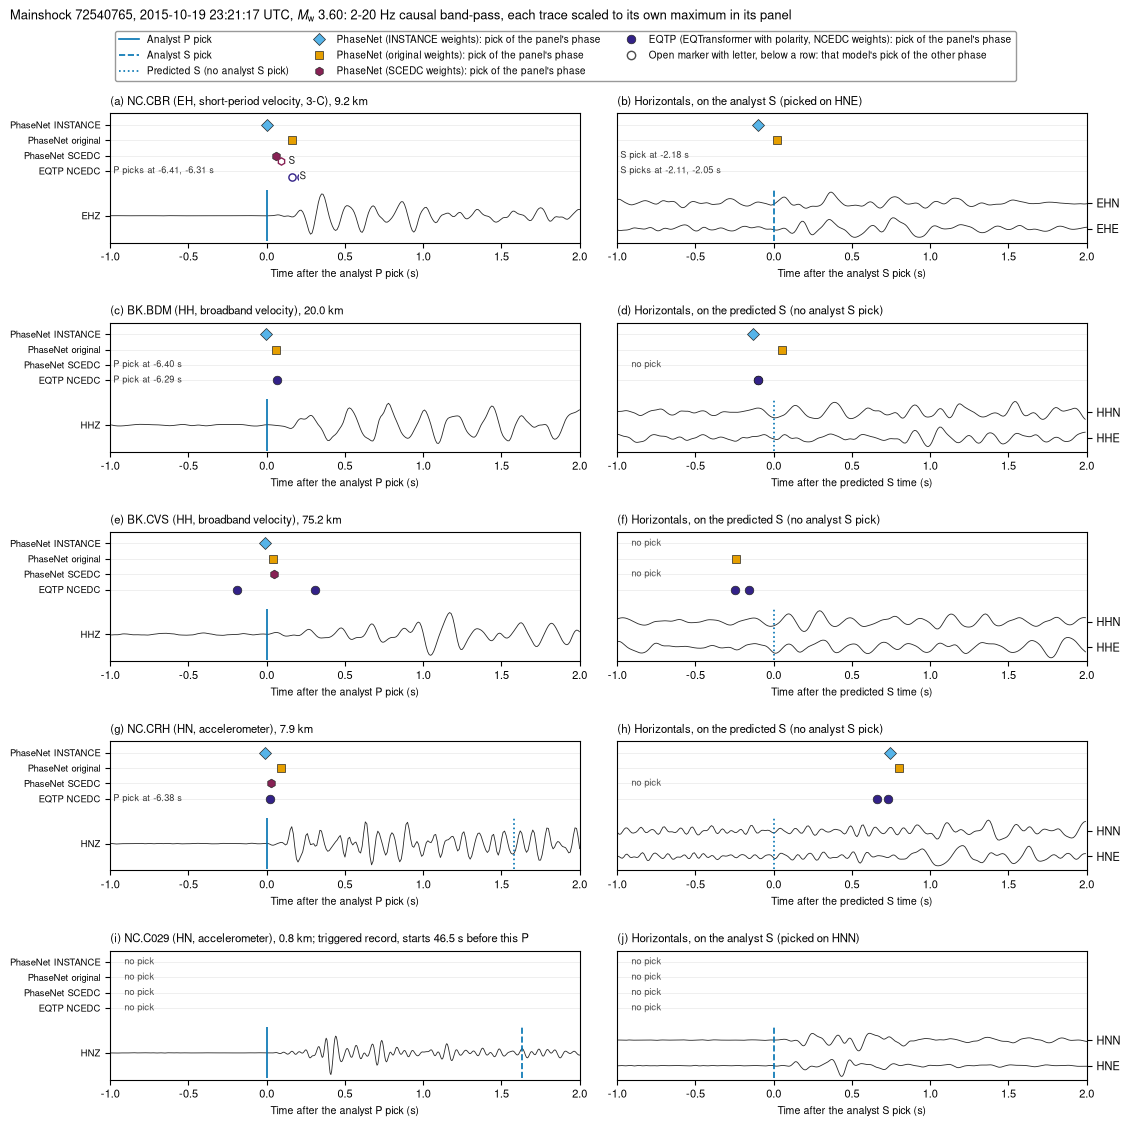

In [14]:
# Figure 5: choose the stations (rules), then draw
WFQ = REF[(REF.event_id == WF_EVENT) & (REF.phase == "P") & ~REF.ref_outlier]
sel_ = []
for sensor, tier, which in WF_RULES:
    q = WFQ[(WFQ.main_sensor == sensor) & (WFQ.tier == tier) & ~WFQ.nsta.isin([r["nsta"] for r in sel_])].sort_values("dist_km")
    if q.empty:
        print(f"no station for the rule {which} {sensor} on a {tier} record")
        continue
    r = q.iloc[0] if which == "nearest" else q.iloc[-1]
    sel_.append(dict(nsta=r.nsta, sensor=sensor, tier=tier, rule=f"{which} {sensor} ({tier})", dist_km=r.dist_km))
WF_SEL = pd.DataFrame(sel_)
display(WF_SEL)
SENSOR_TXT = {"HH": "broadband velocity", "EH": "short-period velocity, 3-C", "HN": "accelerometer", "EP": "borehole geophone",
              "CN": "borehole accelerometer", "DP": "borehole geophone"}
ROW5 = {v: 1.75 + 0.6 * (nm - 1 - j) for j, v in enumerate(MODELS)}
Y5_TOP = max(ROW5.values()) + 0.45
WF_STATUS = []


def draw_rows5(ax, e, nsta, t_ref, phase):
    x0, x1 = WF_SPAN_S
    q = DLP[(DLP.event_id == e) & (DLP.nsta == nsta) & DLP.in_window & DLP.variant.isin(MODELS)]
    for v in MODELS:
        y = ROW5[v]
        ax.axhline(y, color="0.93", lw=0.6, zorder=0)
        mine = q[(q.variant == v) & (q.phase == phase)]
        oth = q[(q.variant == v) & (q.phase != phase)]
        if mine.empty:
            ax.text(x0 + 0.03 * (x1 - x0), y, "no pick", ha="left", va="center", fontsize=6.8, color="0.3", zorder=4)
            status = "no pick"
        else:
            status, outside = [], []
            for r in mine.sort_values("ts").itertuples():
                x = r.ts - t_ref
                if x0 <= x <= x1:
                    ax.plot([x], [y], ls="none", marker=MARK[v], color=COL[v], mec="0.15", mew=0.5, ms=6.2, zorder=5)
                else:
                    outside.append(x)
                status.append(f"{x:+.3f}" + ("" if r.matched else " (unmatched)"))
            if outside:
                right = all(x > x1 for x in outside)
                ax.text(x1 - 0.02 if right else x0 + 0.02, y, f"{phase} pick{'s' if len(outside) > 1 else ''} at "
                        + ", ".join(f"{x:+.2f}" for x in outside) + " s", ha="right" if right else "left", va="center", fontsize=6.5,
                        color="0.2", zorder=4)
            status = ", ".join(status)
        last = -np.inf
        for r in oth.sort_values("ts").itertuples():
            x = r.ts - t_ref
            if x0 <= x <= x1:
                ax.plot([x], [y - 0.22], ls="none", marker=MARK[v], color=COL[v], mec=COL[v], mfc="white", mew=1.0, ms=5.2, zorder=5)
                if x - last > 0.15:
                    ax.text(x + 0.05, y - 0.22, r.phase, fontsize=7, color="0.1", ha="left", va="center", zorder=6,
                            bbox=dict(boxstyle="square,pad=0.08", fc="white", ec="none"))
                last = x
        WF_STATUS.append(dict(nsta=nsta, variant=v, phase=phase, dl_minus_reference_s=status))


ev5 = EV.loc[WF_EVENT]
nrow = len(WF_SEL)
fig = plt.figure(figsize=(12.6, 2.45 * nrow + 0.3))
gs = fig.add_gridspec(nrow, 2, wspace=0.08, hspace=0.62)
axes5 = []
for i, s in enumerate(WF_SEL.itertuples()):
    trs, c = bound_traces(WF_EVENT, s.nsta)
    p_row = REF[(REF.event_id == WF_EVENT) & (REF.nsta == s.nsta) & (REF.phase == "P")].iloc[0]
    s_row = REF[(REF.event_id == WF_EVENT) & (REF.nsta == s.nsta) & (REF.phase == "S")]
    tP = p_row.ts
    if len(s_row):
        tS, s_kind, s_ch = s_row.ts.iloc[0], "analyst", s_row.channel.iloc[0]
    else:
        tS, s_kind, s_ch = h.ts_utc([p_row.pred_S])[0], "predicted", ""
    a1, a2 = fig.add_subplot(gs[i, 0]), fig.add_subplot(gs[i, 1])
    tr = filt(trs["Z"])
    t, y = h.norm_window(tr.times("timestamp") - tP, tr.data, *WF_SPAN_S)
    a1.plot(t, 0.85 * y, color="0.15", lw=0.6, zorder=2)
    for k, role_ in enumerate(("H1", "H2")):
        tr = filt(trs[role_])
        t, y = h.norm_window(tr.times("timestamp") - tS, tr.data, *WF_SPAN_S)
        a2.plot(t, 0.5 - k + 0.42 * y, color="0.15", lw=0.6, zorder=2)
    s_ls = "--" if s_kind == "analyst" else ":"
    for ax, t_ref, ph in ((a1, tP, "P"), (a2, tS, "S")):
        ax.vlines(0.0, -1.0, 1.0, color=ANALYST, lw=1.2, ls="-" if ph == "P" else s_ls, zorder=3)
        xo = (tS if ph == "P" else tP) - t_ref
        if WF_SPAN_S[0] <= xo <= WF_SPAN_S[1]:
            ax.vlines(xo, -1.0, 1.0, color=ANALYST, lw=1.2, ls=s_ls if ph == "P" else "-", zorder=3)
        draw_rows5(ax, WF_EVENT, s.nsta, t_ref, ph)
        ax.set_xlim(*WF_SPAN_S)
        ax.set_ylim(-1.05, Y5_TOP)
    a1.set_yticks([0.0] + [ROW5[v] for v in MODELS])
    a1.set_yticklabels([c.z] + [SHORT[v] for v in MODELS], fontsize=6.8)
    a2.set_yticks([0.5, -0.5])
    a2.set_yticklabels([c.h1, c.h2])
    a2.yaxis.tick_right()
    rec = ""
    if s.tier == "3c_incomplete":
        rec = f"; triggered record, starts {p_row.t_rel_origin_s - p_row.record_start_rel_origin_s:.1f} s before this P"
    a1.set_title(f"{s.nsta} ({c.sensor}, {SENSOR_TXT.get(c.sensor, c.sensor)}), {s.dist_km:.1f} km{rec}", loc="left", fontsize=8.2)
    a2.set_title(f"Horizontals, on the {s_kind} S" + (f" (picked on {s_ch})" if s_ch else " (no analyst S pick)"), loc="left", fontsize=8.2)
    a1.set_xlabel("Time after the analyst P pick (s)", fontsize=7.6)
    a2.set_xlabel("Time after the analyst S pick (s)" if s_kind == "analyst" else "Time after the predicted S time (s)", fontsize=7.6)
    axes5 += [a1, a2]
for k_, a in enumerate(axes5):
    h.panel_letter(a, chr(ord("a") + k_))
h.boxed(axes5)
hs = [Line2D([], [], color=ANALYST, lw=1.2), Line2D([], [], color=ANALYST, lw=1.2, ls="--"), Line2D([], [], color=ANALYST, lw=1.2, ls=":")]
ls = ["Analyst P pick", "Analyst S pick", "Predicted S (no analyst S pick)"]
hs += [Line2D([], [], ls="none", marker=MARK[v], color=COL[v], mec="0.15", mew=0.5, ms=6.2) for v in MODELS]
ls += [f"{LABEL[v]}: pick of the panel's phase" for v in MODELS]
hs += [Line2D([], [], ls="none", marker="o", color="0.3", mfc="white", ms=6)]
ls += ["Open marker with letter, below a row: that model's pick of the other phase"]
leg = h.legend_above(fig, axes5, hs, ls, ncol=3, fontsize=7.2)
h.text_above(fig, [leg] + axes5, f"Mainshock {WF_EVENT}, {pd.Timestamp(ev5.origin_time_utc).strftime('%Y-%m-%d %H:%M:%S')} UTC, "
             f"{MLAB[WF_EVENT]}: {BAND_HZ[0]:g}-{BAND_HZ[1]:g} Hz causal band-pass, each trace scaled to its own maximum in its panel",
             fontsize=9.3)
FIGS["5"] = h.save_fig(fig, FIG_DIR, f"07_5_waveforms_mainshock_{WF_EVENT}")
plt.show()

In [15]:
# Figure 5: the picks shown, as a table (time after the analyst or predicted pick in s; 'no pick' = none in the event window)
WFS = pd.DataFrame(WF_STATUS)
T5 = WFS.pivot_table(index=["nsta", "phase"], columns="variant", values="dl_minus_reference_s", aggfunc="first")[MODELS]
T5.columns = [SHORT[v] for v in MODELS]
display(T5)
WFL = pd.DataFrame(WF_LOG)
display(WFL.drop_duplicates(["event_id", "channel"]).round(3))
for r in WFL.drop_duplicates(["event_id", "channel"]).itertuples():
    chk(f"waveform {r.event_id} {r.channel}: playback file = sorted file scautopick read (max difference, counts)", r.playback_vs_sorted_max_diff_counts, 0, 0)
    chk(f"waveform {r.event_id} {r.channel}: stations.xml sensitivity sign and dip = bound_channels.csv", [np.sign(r.sensitivity), r.dip],
        [np.sign(r.bound_channels_gain), r.bound_channels_dip], 0)
trig5 = WF_SEL[WF_SEL.tier == "3c_incomplete"].nsta.tolist()
why5 = MISS[(MISS.event_id == WF_EVENT) & MISS.nsta.isin(WF_SEL.nsta) & MISS.variant.isin(MODELS)]
n_cells = int(T5.size)
n_pick = int((T5 != "no pick").sum().sum())
mt = DLP[(DLP.event_id == WF_EVENT) & DLP.nsta.isin(WF_SEL.nsta) & DLP.variant.isin(MODELS) & DLP.matched & (DLP.matched_event_id == WF_EVENT)]
lines = [
    f"- {n_pick} of the {n_cells} station-phase-model combinations have a DL pick in the event window; the matched ones lie within "
    f"{mt.ref_dt_s.abs().max():.2f} s of the analyst picks (median |dt| {mt.ref_dt_s.abs().median():.3f} s).",
]
for st_ in trig5:
    wy = why5[why5.nsta == st_].groupby(["phase", "why_missed"]).variant.apply(lambda x: ", ".join(SHORT[v] for v in x))
    lines.append(f"- **{st_} (triggered record):** " + "; ".join(f"{p} missed by {vv} ({w_.replace('_', ' ')})" for (p, w_), vv in wy.items())
                 + f". The record starts too late for the detector, which waits initTime = {INIT_TIME_S:g} s (Figure 1c).")
nos = WF_SEL[~WF_SEL.nsta.isin(REF[(REF.event_id == WF_EVENT) & (REF.phase == "S")].nsta)].nsta.tolist()
sp5 = DLP[(DLP.event_id == WF_EVENT) & DLP.nsta.isin(nos) & DLP.variant.isin(MODELS) & DLP.in_window & (DLP.phase == "S")]
lines.append(f"- At the stations without an analyst S pick ({', '.join(nos)}) the four models made {len(sp5)} S picks in the event window, "
             "classed by step 12 as " + ", ".join(f"{n} '{c.replace('_', ' ')}'" for c, n in sp5['class'].value_counts().items())
             + ". With no analyst S to compare with, every one of them lowers the precision (the lower bound); the 'plausible' ones count as "
             "correct only in the precision counting plausible arrivals.")
fpk = DLP[(DLP.event_id == WF_EVENT) & DLP.nsta.isin(WF_SEL.nsta) & DLP.variant.isin(MODELS) & DLP.in_window & (DLP.phase == "P")
          & (DLP.matched_event_id == SWARM_EVENT)]
fpk = fpk.assign(after_p=[t_ - REF[(REF.event_id == WF_EVENT) & (REF.nsta == n_) & (REF.phase == "P")].ts.iloc[0] for t_, n_ in zip(fpk.ts, fpk.nsta)])
if len(fpk):
    lines.append(f"- The P picks written out at {fpk.after_p.min():+.1f} to {fpk.after_p.max():+.1f} s in the left column are picks of the foreshock {SWARM_EVENT} "
                 f"inside the mainshock's event window ({len(fpk)} at these stations: " + ", ".join(f"{SHORT[v]} {n}" for v, n in fpk.variant.value_counts().items())
                 + "); where a model has only that pick, the mainshock P itself was missed at that station.")
display(Markdown("\n".join(lines)))

PhaseNet INSTANCE   PhaseNet original      PhaseNet SCEDC                              EQTP NCEDC
nsta    phase                                                                                                    
BK.BDM  P                  -0.002              +0.058              -6.402                          -6.292, +0.068
        S      -0.130 (unmatched)  +0.050 (unmatched)             no pick  -0.100 (unmatched), -0.100 (unmatched)
BK.CVS  P                  -0.012              +0.038              +0.048              -0.192, +0.308 (unmatched)
        S                 no pick  -0.238 (unmatched)             no pick  -0.248 (unmatched), -0.158 (unmatched)
NC.C029 P                 no pick             no pick             no pick                                 no pick
        S                 no pick             no pick             no pick                                 no pick
NC.CBR  P                  +0.000              +0.160              +0.060              -6.410 (unmatched), -6.310
        S                  -0.100              +0.020  -2.180 (unmatched)  -2.110 (unmatched), -2.050 (unmatched)
NC.CRH  P                  -0.010              +0.090              +0.030                          -6.380, +0.020
        S      +0.742 (unmatched)  +0.802 (unmatched)             no pick  +0.662 (unmatched), +0.732 (unmatched)

,event_id,nsta,channel,role,pieces,playback_vs_sorted_max_diff_counts,sensitivity,dip,sign_applied,bound_channels_gain,bound_channels_dip
0,72540760,NC.CBR,NC.CBR..EHZ,Z,1,0.0,6.291450e+07,-90.0,1.0,6.291450e+07,-90.0
1,72540760,NC.CBR,NC.CBR..EHN,H1,1,0.0,6.291450e+07,0.0,1.0,6.291450e+07,0.0
2,72540760,NC.CBR,NC.CBR..EHE,H2,1,0.0,6.291450e+07,0.0,1.0,6.291450e+07,0.0
3,72540765,NC.CBR,NC.CBR..EHZ,Z,1,0.0,6.291450e+07,-90.0,1.0,6.291450e+07,-90.0
4,72540765,NC.CBR,NC.CBR..EHN,H1,1,0.0,6.291450e+07,0.0,1.0,6.291450e+07,0.0
5,72540765,NC.CBR,NC.CBR..EHE,H2,1,0.0,6.291450e+07,0.0,1.0,6.291450e+07,0.0
6,72540765,BK.BDM,BK.BDM.00.HHZ,Z,1,0.0,2.516580e+09,-90.0,1.0,2.516580e+09,-90.0
7,72540765,BK.BDM,BK.BDM.00.HHN,H1,1,0.0,2.516580e+09,0.0,1.0,2.516580e+09,0.0
8,72540765,BK.BDM,BK.BDM.00.HHE,H2,1,0.0,2.516580e+09,0.0,1.0,2.516580e+09,0.0
9,72540765,BK.CVS,BK.CVS.00.HHZ,Z,1,0.0,2.553530e+09,-90.0,1.0,2.553530e+09,-90.0


- 28 of the 40 station-phase-model combinations have a DL pick in the event window; the matched ones lie within 0.19 s of the analyst picks (median |dt| 0.043 s).
- **NC.C029 (triggered record):** P missed by EQTP NCEDC, PhaseNet original, PhaseNet SCEDC, PhaseNet INSTANCE (record starts too late); S missed by EQTP NCEDC, PhaseNet original, PhaseNet SCEDC, PhaseNet INSTANCE (no P pick so no S picker). The record starts too late for the detector, which waits initTime = 60 s (Figure 1c).
- At the stations without an analyst S pick (BK.BDM, BK.CVS, NC.CRH) the four models made 11 S picks in the event window, classed by step 12 as 8 'plausible no analyst pick', 3 'near duplicate'. With no analyst S to compare with, every one of them lowers the precision (the lower bound); the 'plausible' ones count as correct only in the precision counting plausible arrivals.
- The P picks written out at -6.4 to -6.3 s in the left column are picks of the foreshock 72540760 inside the mainshock's event window (4 at these stations: EQTP NCEDC 3, PhaseNet SCEDC 1); where a model has only that pick, the mainshock P itself was missed at that station.

## 7. Figure 6: accelerometer against velocity sensor at the same sites

**What is shown.** At the stations that have both a velocity sensor (bound in the main set) and a continuously
recording accelerometer (bound in the accelerometer set), the same models were run once on each sensor. (a) P and
(b) S recall over the analyst picks at these stations (all with data; the records of both sensors are complete):
the filled marker is the velocity sensor, the open marker the accelerometer, with the counts found / analyst picks.
(c) P recall of the best model per station, again velocity sensor (filled) against accelerometer (open); the label
gives the two sensors and N, the number of analyst P picks at the station.

**How to read it.** A short vertical line means the accelerometer does nearly as well as the velocity sensor. Most
strong-motion stations of this data set are triggered recorders (Figure 1); this figure separates the sensor from the
recording mode.

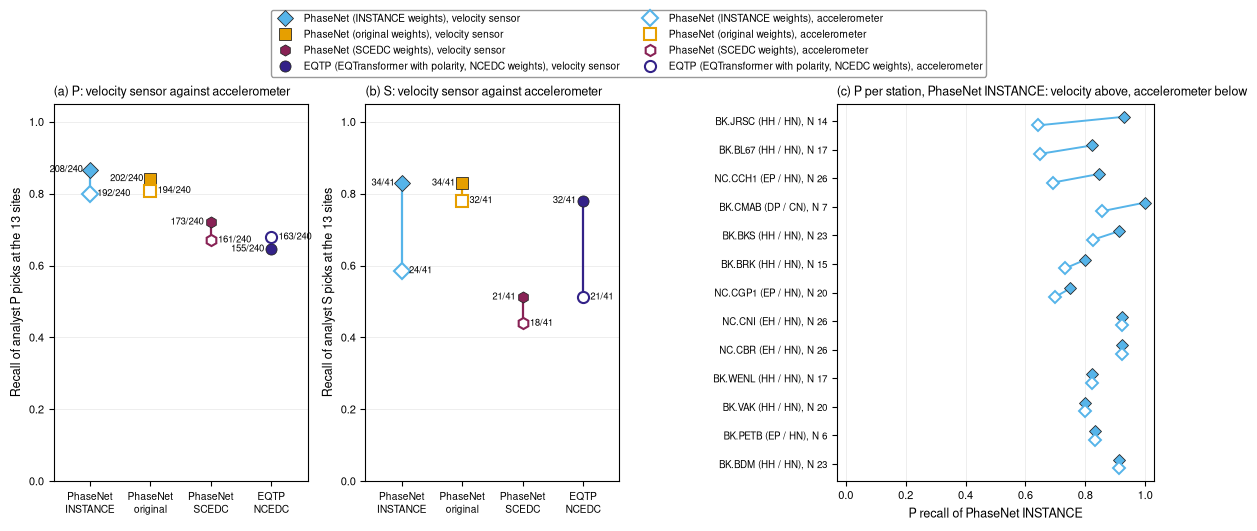

,model,binding_set,phase,n_ref_all,n_matched_all,recall_all,precision,median_abs_dt_s,p95_abs_dt_s,mean_dt_s
0,eqtp_ncedc,main (velocity sensor),P,240,155,0.646,0.803,0.020,0.113,0.019
1,eqtp_ncedc,main (velocity sensor),S,41,32,0.780,0.184,0.030,0.162,-0.019
2,eqtp_ncedc,hn (accelerometer),P,240,163,0.679,0.848,0.022,0.110,0.004
3,eqtp_ncedc,hn (accelerometer),S,41,21,0.512,0.135,0.050,0.180,0.014
4,phasenet_original,main (velocity sensor),P,240,202,0.842,0.829,0.020,0.138,0.032
5,phasenet_original,main (velocity sensor),S,41,34,0.829,0.154,0.035,0.170,0.050
6,phasenet_original,hn (accelerometer),P,240,194,0.808,0.831,0.020,0.168,0.029
7,phasenet_original,hn (accelerometer),S,41,32,0.780,0.142,0.030,0.154,0.028
8,phasenet_scedc,main (velocity sensor),P,240,173,0.721,0.894,0.020,0.118,0.008
9,phasenet_scedc,main (velocity sensor),S,41,21,0.512,0.198,0.040,0.110,0.015


In [16]:
# Figure 6: velocity sensor against accelerometer at the 13 co-located sites
fig = plt.figure(figsize=(14.2, 4.9))
gs = fig.add_gridspec(1, 4, width_ratios=[1.0, 1.0, 0.4, 1.25], wspace=0.25)
axs = [fig.add_subplot(gs[0, i]) for i in (0, 1, 3)]
AV = AVV.set_index(["variant", "phase"])
for k, ph in enumerate(PH):
    ax = axs[k]
    for j, m in enumerate(MODELS):
        rv_, ra_ = AV.loc[(m, ph)], AV.loc[(m + HN_SUFFIX, ph)]
        ax.plot([j, j], [rv_.recall_all, ra_.recall_all], color=COL[m], lw=1.6, zorder=2)
        ax.plot([j], [rv_.recall_all], ls="none", marker=MARK[m], color=COL[m], mec="0.15", mew=0.6, ms=8, zorder=3)
        ax.plot([j], [ra_.recall_all], ls="none", marker=MARK[m], color=COL[m], mec=COL[m], mfc="white", mew=1.5, ms=8, zorder=3)
        ax.text(j - 0.12, rv_.recall_all, f"{int(rv_.n_matched_all)}/{int(rv_.n_ref_all)}", ha="right", va="center", fontsize=6.8)
        ax.text(j + 0.12, ra_.recall_all, f"{int(ra_.n_matched_all)}/{int(ra_.n_ref_all)}", ha="left", va="center", fontsize=6.8)
    ax.set_xticks(range(nm))
    ax.set_xticklabels([SHORT[m].replace(" ", "\n", 1) for m in MODELS], fontsize=7.4)
    ax.set_xlim(-0.6, nm - 0.4)
    ax.set_ylim(0, 1.05)
    ax.grid(axis="y", color="0.92", lw=0.6, zorder=0)
    ax.set_ylabel(f"Recall of analyst {ph} picks at the {N13} sites")
    ax.set_title(f"{ph}: velocity sensor against accelerometer", loc="left")
ax = axs[2]
st13 = STB[STB.hn_sensor != ""].set_index("nsta")
rows = []
for s in st13.index:
    q = RVD[(RVD.phase == "P") & (RVD.nsta == s) & RVD.has_data]
    qv, qa = q[q.variant == BEST_MODEL], q[q.variant == BEST_MODEL + HN_SUFFIX]
    rows.append(dict(nsta=s, main=st13.loc[s, "main_sensor"], hn=st13.loc[s, "hn_sensor"], n=len(qv), rv=qv.matched.mean() if len(qv) else np.nan,
                     ra=qa.matched.mean() if len(qa) else np.nan, kv=int(qv.matched.sum()), ka=int(qa.matched.sum())))
ST6 = pd.DataFrame(rows)
ST6["diff"] = ST6.rv - ST6.ra
ST6 = ST6.sort_values(["diff", "nsta"]).reset_index(drop=True)
for i, r in ST6.iterrows():
    ax.plot([r.rv, r.ra], [i + 0.15, i - 0.15], color=COL[BEST_MODEL], lw=1.4, zorder=2)
    ax.plot([r.rv], [i + 0.15], ls="none", marker=MARK[BEST_MODEL], color=COL[BEST_MODEL], mec="0.15", mew=0.6, ms=6.5, zorder=3)
    ax.plot([r.ra], [i - 0.15], ls="none", marker=MARK[BEST_MODEL], color=COL[BEST_MODEL], mec=COL[BEST_MODEL], mfc="white", mew=1.4, ms=6.5, zorder=3)
ax.set_yticks(range(len(ST6)))
ax.set_yticklabels([f"{r.nsta} ({r.main} / {r.hn}), N {r.n}" for r in ST6.itertuples()], fontsize=7)
ax.set_xlim(-0.03, 1.03)
ax.set_ylim(-0.6, len(ST6) - 0.4)
ax.grid(axis="x", color="0.92", lw=0.6, zorder=0)
ax.set_xlabel(f"P recall of {SHORT[BEST_MODEL]}")
ax.set_title(f"P per station, {SHORT[BEST_MODEL]}: velocity above, accelerometer below", loc="left")
for k_, a in enumerate(axs):
    h.panel_letter(a, "abc"[k_])
h.boxed(axs)
hs = [Line2D([], [], ls="none", marker=MARK[m], color=COL[m], mec="0.15", mew=0.6, ms=8) for m in MODELS] + \
     [Line2D([], [], ls="none", marker=MARK[m], color=COL[m], mec=COL[m], mfc="white", mew=1.5, ms=8) for m in MODELS]
ls = [f"{LABEL[m]}, velocity sensor" for m in MODELS] + [f"{LABEL[m]}, accelerometer" for m in MODELS]
h.legend_above(fig, axs, hs, ls, ncol=2, fontsize=7.4)
FIGS["6"] = h.save_fig(fig, FIG_DIR, "07_6_accelerometer_vs_velocity")
plt.show()
display(AVV[["model", "binding_set", "phase", "n_ref_all", "n_matched_all", "recall_all", "precision", "median_abs_dt_s", "p95_abs_dt_s",
             "mean_dt_s"]].round(3))

In [17]:
# Figure 6: what it says
dP = {m: AV.loc[(m, "P"), "recall_all"] - AV.loc[(m + HN_SUFFIX, "P"), "recall_all"] for m in MODELS}
dS = {m: AV.loc[(m, "S"), "recall_all"] - AV.loc[(m + HN_SUFFIX, "S"), "recall_all"] for m in MODELS}
fph = OUTW[(OUTW.phase == "P") & OUTW.variant.str.endswith(HN_SUFFIX)].set_index("variant").false_per_station_hour_searchable
nS13 = int(AV.loc[(MODELS[0], "S"), "n_ref_all"])
lines = [
    "- **For P the accelerometer costs little:** recall drops by " + ", ".join(f"{SHORT[m]} {100 * dP[m]:+.0f}" for m in MODELS)
    + " percentage points (velocity minus accelerometer; a negative value means the accelerometer did better). P precision with the "
    f"accelerometer is {AV.xs('P', level='phase').loc[[m + HN_SUFFIX for m in MODELS], 'precision'].min():.2f}-"
    f"{AV.xs('P', level='phase').loc[[m + HN_SUFFIX for m in MODELS], 'precision'].max():.2f} against "
    f"{AV.xs('P', level='phase').loc[MODELS, 'precision'].min():.2f}-{AV.xs('P', level='phase').loc[MODELS, 'precision'].max():.2f} with the velocity sensor.",
    "- **For S the loss is larger and differs between models:** " + ", ".join(f"{SHORT[m]} {100 * dS[m]:+.0f}" for m in MODELS)
    + f" percentage points, over only {nS13} analyst S picks.",
    f"- Per station (panel c), {int((ST6['diff'] > 0).sum())} of {len(ST6)} stations lose P picks on the accelerometer, "
    f"{int((ST6['diff'] == 0).sum())} keep the same recall and {int((ST6['diff'] < 0).sum())} gain.",
    f"- False P picks per station-hour of pre-event noise on these accelerometers: {fph.min():.2f}-{fph.max():.2f} (the four models).",
    "- **So a continuously recording accelerometer is a usable fallback for P picks where no velocity sensor exists.** The low recall on "
    "most strong-motion stations in this test comes from triggered recording (Figure 1), not from the sensor.",
]
display(Markdown("\n".join(lines)))

- **For P the accelerometer costs little:** recall drops by PhaseNet INSTANCE +7, PhaseNet original +3, PhaseNet SCEDC +5, EQTP NCEDC -3 percentage points (velocity minus accelerometer; a negative value means the accelerometer did better). P precision with the accelerometer is 0.83-0.91 against 0.80-0.89 with the velocity sensor.
- **For S the loss is larger and differs between models:** PhaseNet INSTANCE +24, PhaseNet original +5, PhaseNet SCEDC +7, EQTP NCEDC +27 percentage points, over only 41 analyst S picks.
- Per station (panel c), 7 of 13 stations lose P picks on the accelerometer, 6 keep the same recall and 0 gain.
- False P picks per station-hour of pre-event noise on these accelerometers: 0.21-1.92 (the four models).
- **So a continuously recording accelerometer is a usable fallback for P picks where no velocity sensor exists.** The low recall on most strong-motion stations in this test comes from triggered recording (Figure 1), not from the sensor.

## 8. Figure 7: first-motion polarity of `eqtp_ncedc` against the analysts

**What is compared.** `eqtp_ncedc` is the only model with polarity outputs: for each P pick it gives the probability
that the first motion is up and that it is down. The plugin sets the pick's polarity when the larger of the two reaches
`polarityMinConfidence`, and refers it to ground motion: it swaps up and down when the vertical channel's inventory
dip is +90 (sensor pointing down) or its gain is negative. The pairs used are the matched P picks whose analyst pick
carries a first motion (U or D).

- *Coverage*: the share of these pairs for which the plugin gave a polarity at the threshold.
- *Agreement*: of the pairs with a DL polarity, the share where it equals the analyst's first motion.

The picks themselves do not depend on `polarityMinConfidence`, so a higher threshold simply keeps the pairs whose
polarity confidence reaches it. That allows a sweep from 0.5 to 0.95 in steps of
0.01 from the one run; the plugin default (0.5) and the stricter value 0.7 are
marked. Agreement is drawn only where at least 10 pairs of a group have a DL polarity.

**What is shown.** (a) coverage and (b) agreement against the threshold, split by the analyst's onset quality: weight
code 0 and 1 are impulsive onsets, weight code 2 are the emergent ones (here every emergent onset has weight code 2).
(c) coverage and (d) agreement split by the bound vertical channel: normally oriented, or "inverted" (negative gain or
dip +90, the BK boreholes). In (d) the dotted line is the agreement with the plugin's swap undone, i.e. the polarity of
the raw counts. The gray dashed line at 0.5 is the agreement expected by chance. Numbers at the markers are the values
at the two marked thresholds.

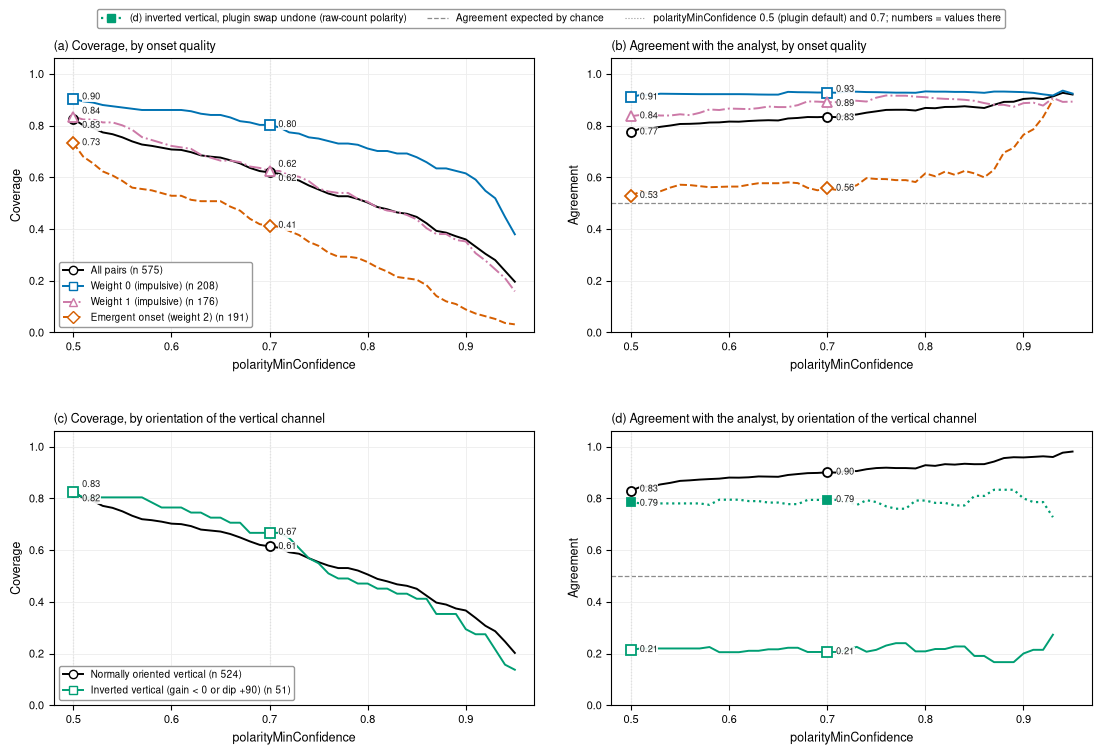

n  n_with_polarity  coverage  n_agree  agreement  agreement_swap_undone
group                                   threshold                                                                           
All pairs                               0.5        575              475     0.826      368      0.775                  0.825
                                        0.7        575              356     0.619      297      0.834                  0.890
Weight 0 (impulsive)                    0.5        208              188     0.904      171      0.910                  0.941
                                        0.7        208              167     0.803      155      0.928                  0.952
Weight 1 (impulsive)                    0.5        176              147     0.835      123      0.837                  0.884
                                        0.7        176              110     0.625       98      0.891                  0.936
Emergent onset (weight 2)               0.5        191              140     0.733       74      0.529                  0.607
                                        0.7        191               79     0.414       44      0.557                  0.696
Normally oriented vertical              0.5        524              433     0.826      359      0.829                  0.829
                                        0.7        524              322     0.615      290      0.901                  0.901
Inverted vertical (gain < 0 or dip +90) 0.5         51               42     0.824        9      0.214                  0.786
                                        0.7         51               34     0.667        7      0.206                  0.794

In [18]:
# Figure 7: eqtp_ncedc polarity against the analyst first motions, threshold sweep
PQ = POL[POL.variant == POLARITY_MODEL]
THR = np.round(np.arange(POL_SWEEP[0], POL_SWEEP[1] + POL_SWEEP[2] / 2.0, POL_SWEEP[2]), 4)
ONSET_G = [("All pairs", lambda q: q, "k", "-", "o"), ("Weight 0 (impulsive)", lambda q: q[q.weight_code == 0], "#0072B2", "-", "s"),
           ("Weight 1 (impulsive)", lambda q: q[q.weight_code == 1], "#CC79A7", "-.", "^"),
           ("Emergent onset (weight 2)", lambda q: q[q.onset == "E"], "#D55E00", "--", "D")]
CHAN_G = [("Normally oriented vertical", lambda q: q[q.dl_channel_sense == "Direct"], "k", "-", "o"),
          ("Inverted vertical (gain < 0 or dip +90)", lambda q: q[q.dl_channel_sense == "Inverted"], "#009E73", "-", "s")]
fig, axs = plt.subplots(2, 2, figsize=(13.4, 8.4), gridspec_kw=dict(hspace=0.36, wspace=0.16))
POLTAB = []
LBL = {}


def sweep(ax, groups, key, swap=False):
    hs, ls = [], []
    for name, f_, c, lst, mk in groups:
        q = f_(PQ)
        vals = [h.coverage_agreement(q, t) for t in THR]
        for kk, lst_, fill_ in ((key, lst, "white"),) + ((("agreement_swap_undone", ":", c),) if swap else ()):
            yy = np.array([d[kk] for d in vals], float)
            if kk != "coverage":
                yy[np.array([d["n_with_polarity"] for d in vals]) < POL_MIN_N] = np.nan
            ax.plot(THR, yy, color=c, ls=lst_, lw=1.4 if lst_ != ":" else 1.6, zorder=3)
            for t in POL_THRESHOLDS:
                d = h.coverage_agreement(q, t)
                ax.plot([t], [d[kk]], marker=mk, color=c, mec=c, mfc=fill_, ms=6.5 if fill_ == "white" else 5.5, mew=1.3, zorder=4)
                LBL.setdefault((id(ax), t), (ax, []))[1].append(d[kk])
                if kk == key:
                    POLTAB.append(dict(group=name, threshold=t, **d))
        hs.append(Line2D([], [], color=c, ls=lst, lw=1.4, marker=mk, mfc="white", mec=c, ms=6))
        ls.append(f"{name} (n {len(q)})")
    return hs, ls


hA, lA = sweep(axs[0, 0], ONSET_G, "coverage")
sweep(axs[0, 1], ONSET_G, "agreement")
hC, lC = sweep(axs[1, 0], CHAN_G, "coverage")
sweep(axs[1, 1], CHAN_G[:1], "agreement")
sweep(axs[1, 1], CHAN_G[1:], "agreement", swap=True)
for (_, t), (ax, vals) in LBL.items():
    pos = h.spread_labels(np.array(vals, float), 0.055)
    for v_, p_ in zip(vals, pos):
        ax.text(t + 0.009, p_, f"{v_:.2f}", fontsize=6.6, color="0.1", ha="left", va="center", zorder=5,
                bbox=dict(boxstyle="square,pad=0.05", fc="white", ec="none", alpha=0.9))
for ax, ttl, yl in ((axs[0, 0], "Coverage, by onset quality", "Coverage"), (axs[0, 1], "Agreement with the analyst, by onset quality", "Agreement"),
                    (axs[1, 0], "Coverage, by orientation of the vertical channel", "Coverage"),
                    (axs[1, 1], "Agreement with the analyst, by orientation of the vertical channel", "Agreement")):
    for t in POL_THRESHOLDS:
        ax.axvline(t, color="0.6", lw=0.8, ls=":", zorder=1)
    if yl == "Agreement":
        ax.axhline(0.5, color="0.55", lw=0.9, ls="--", zorder=1)
    ax.set_xlim(POL_SWEEP[0] - 0.02, POL_SWEEP[1] + 0.02)
    ax.set_ylim(0, 1.06)
    ax.set_xlabel("polarityMinConfidence")
    ax.set_ylabel(yl)
    ax.set_title(ttl, loc="left")
    ax.grid(color="0.93", lw=0.6, zorder=0)
for k_, a in enumerate(axs.ravel()):
    h.panel_letter(a, "abcd"[k_])
h.boxed(axs)
h.legend_box(axs[0, 0], hA, lA, loc="lower left", fontsize=7.2)
h.legend_box(axs[1, 0], hC, lC, loc="lower left", fontsize=7.2)
hs = [Line2D([], [], color=CHAN_G[1][2], ls=":", lw=1.6, marker=CHAN_G[1][4], mfc=CHAN_G[1][2], mec=CHAN_G[1][2], ms=5.5),
      Line2D([], [], color="0.55", lw=0.9, ls="--"), Line2D([], [], color="0.6", lw=0.8, ls=":")]
ls = ["(d) inverted vertical, plugin swap undone (raw-count polarity)", "Agreement expected by chance",
      f"polarityMinConfidence {POL_THRESHOLDS[0]:g} (plugin default) and {POL_THRESHOLDS[1]:g}; numbers = values there"]
h.legend_above(fig, axs, hs, ls, ncol=3, fontsize=7.4)
FIGS["7"] = h.save_fig(fig, FIG_DIR, "07_7_eqtp_polarity")
plt.show()
PT = pd.DataFrame(POLTAB).drop_duplicates(["group", "threshold"]).set_index(["group", "threshold"])
display(PT.round(3))

In [19]:
# Figure 7: what it says
pj5, pj7 = PJ[POLARITY_MODEL][f"thr_{POL_THRESHOLDS[0]}"], PJ[POLARITY_MODEL][f"thr_{POL_THRESHOLDS[1]}"]
hn5, hn7 = PJ[POLARITY_MODEL + HN_SUFFIX][f"thr_{POL_THRESHOLDS[0]}"]["all"], PJ[POLARITY_MODEL + HN_SUFFIX][f"thr_{POL_THRESHOLDS[1]}"]["all"]
opp = PJ[POLARITY_MODEL]["stations_ge3_disagree_ge80pct"]
t0, t1 = POL_THRESHOLDS
inv_st = PQ[PQ.dl_channel_sense == "Inverted"].groupby("nsta").size()
lines = [
    f"- **Pairs:** {PJ[POLARITY_MODEL]['analyst_fm_total']} analyst first motions in all, {PJ[POLARITY_MODEL]['analyst_fm_at_3c']} at 3-C stations, "
    f"{PJ[POLARITY_MODEL]['analyst_fm_matched']} on P picks that {POLARITY_MODEL} matched.",
    f"- **Coverage** is {pj5['all']['coverage']:.2f} at {t0:g} and {pj7['all']['coverage']:.2f} at {t1:g}; **agreement** "
    f"{pj5['all']['agreement']:.2f} and {pj7['all']['agreement']:.2f}. On normally oriented channels agreement is "
    f"{pj5['direct_sense']['agreement']:.2f} and {pj7['direct_sense']['agreement']:.2f}.",
    f"- **Onset quality decides it:** weight-0 onsets agree {pj5['weight_0']['agreement']:.2f} / {pj7['weight_0']['agreement']:.2f} "
    f"(coverage {pj5['weight_0']['coverage']:.2f} / {pj7['weight_0']['coverage']:.2f}); emergent onsets {pj5['onset_E']['agreement']:.2f} / "
    f"{pj7['onset_E']['agreement']:.2f}, close to chance (coverage {pj5['onset_E']['coverage']:.2f} / {pj7['onset_E']['coverage']:.2f}). "
    f"Values at {t0:g} / {t1:g}.",
    f"- **Inverted channels** ({pj5['inverted_sense']['n_matched_with_analyst_fm']} pairs at "
    + ", ".join(f"{s} {n}" for s, n in inv_st.items()) + f") agree only {pj5['inverted_sense']['agreement']:.2f} / "
    f"{pj7['inverted_sense']['agreement']:.2f}; with the swap undone they agree {pj5['inverted_sense']['agreement_raw_counts']:.2f} / "
    f"{pj7['inverted_sense']['agreement_raw_counts']:.2f}. The analysts' first motions on these channels follow the raw counts.",
    f"- **Independent check without any DL model** (`12_polarity_reference_check.py`): analyst first motions on inverted channels agree with "
    f"those of similar rays on normal channels in {PREFJ['inverted_frac_same']:.2f} of {PREFJ['inverted_tests']} tests, against "
    f"{PREFJ['control_frac_same']:.2f} of {PREFJ['control_tests']} for normal channels (rule: {PREFJ['rule']}). So the plugin's swap is right "
    "and these archive first motions are not.",
    "- Stations with at least 3 comparisons that always disagree: " + ", ".join(f"{d['nsta']} ({d['n']} of {d['n']}, {d['sense'].lower()})" for d in opp) + ".",
    f"- **Accelerometer set** ({hn5['n_matched_with_analyst_fm']} pairs, nearly all normally oriented): coverage {hn5['coverage']:.2f} / "
    f"{hn7['coverage']:.2f}, agreement {hn5['agreement']:.2f} / {hn7['agreement']:.2f}.",
    f"- **For focal mechanisms, {t1:g} is the better threshold:** it gives up {1 - pj7['all']['coverage'] / pj5['all']['coverage']:.0%} of the "
    f"polarities for higher agreement on normal channels.",
]
display(Markdown("\n".join(lines)))

- **Pairs:** 1951 analyst first motions in all, 1120 at 3-C stations, 575 on P picks that eqtp_ncedc matched.
- **Coverage** is 0.83 at 0.5 and 0.62 at 0.7; **agreement** 0.77 and 0.83. On normally oriented channels agreement is 0.83 and 0.90.
- **Onset quality decides it:** weight-0 onsets agree 0.91 / 0.93 (coverage 0.90 / 0.80); emergent onsets 0.53 / 0.56, close to chance (coverage 0.73 / 0.41). Values at 0.5 / 0.7.
- **Inverted channels** (51 pairs at BK.MHDL 9, BK.OXMT 9, BK.PETB 2, BK.SBRN 8, BK.SM2B 20, BK.VALB 3) agree only 0.21 / 0.21; with the swap undone they agree 0.79 / 0.79. The analysts' first motions on these channels follow the raw counts.
- **Independent check without any DL model** (`12_polarity_reference_check.py`): analyst first motions on inverted channels agree with those of similar rays on normal channels in 0.32 of 148 tests, against 0.70 of 809 for normal channels (rule: neighbours: same event, direct channel, |daz| <= 10.0, |dtakeoff| <= 10.0, >= 2, majority >= 70 %). So the plugin's swap is right and these archive first motions are not.
- Stations with at least 3 comparisons that always disagree: BK.MHDL (8 of 8, inverted), BK.SBRN (6 of 6, inverted), NP.1804 (3 of 3, direct).
- **Accelerometer set** (156 pairs, nearly all normally oriented): coverage 0.84 / 0.72, agreement 0.94 / 0.95.
- **For focal mechanisms, 0.7 is the better threshold:** it gives up 25% of the polarities for higher agreement on normal channels.

## 9. Figure 8: plugin against SeisBench with the same EQTP weights, and the cost

**Why.** `eqtp_ncedc` was trained on NCEDC data, yet in the plugin it finds fewer P picks than the PhaseNet models.
Step 12 ran SeisBench's continuous picking (`EQTP.from_pretrained('ncedc')`, one CPU thread) on a few test events with the same
raw streams and thresholds, and confirmed that the ONNX file and the SeisBench model give the same outputs on the same
input. The difference between the two is therefore the plugin's trigger-and-window design, not the network.

**What is shown.** (a) recall over the analyst picks of these events: P on complete 3-C records, P on triggered
records, and S over all 3-C stations, for the plugin's EQTP, SeisBench's continuous EQTP and, for comparison, the
plugin's phasenet_instance on the same events. Labels are found / analyst picks. (b) where the plugin and SeisBench
both picked the same arrival: plugin time minus SeisBench time, P filled and S as a step line, bins of
0.01 s from −0.3 to +0.3 s. (c) cost: CPU seconds per station-hour of data for
each model in the plugin (whole scautopick process, one thread, all test events) and for SeisBench's continuous EQTP (its
test events, one thread; it includes Python I/O). The label gives the CPU time per model window. Log scale.

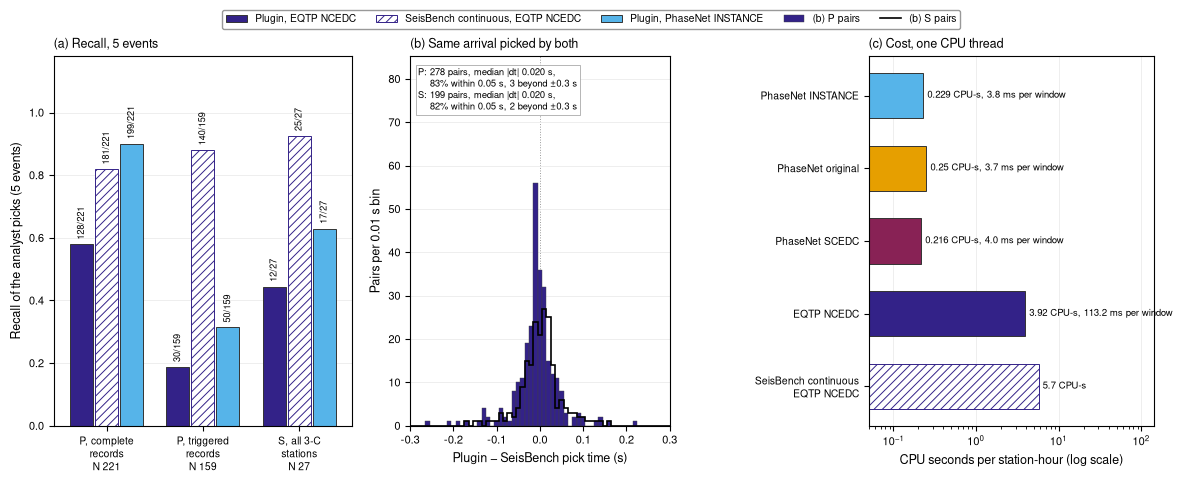

,group,phase,n,plugin,seisbench,ref_model,ref_model_k
0,"P, complete\nrecords",P,221,0.579,0.819,0.900,199
1,"P, triggered\nrecords",P,159,0.189,0.881,0.314,50
2,"S, all 3-C\nstations",S,27,0.444,0.926,0.630,17


,station_hours,cpu_s_total,cpu_s_per_station_hour,triggers,p_windows,s_windows,cpu_ms_per_window,max_rss_mb,startup_probe_cpu_s
variant,,,,,,,,,
phasenet_instance,177.089,40.61,0.229,5114,4033,6036,3.775,304.449,0.10
phasenet_original,177.089,44.25,0.250,5114,4033,7313,3.694,308.223,0.09
phasenet_scedc,177.089,38.31,0.216,5114,4033,4958,3.972,259.965,0.10
eqtp_ncedc,177.089,694.25,3.920,5114,2259,3852,113.181,364.457,0.10
phasenet_instance_hn,22.533,11.25,0.499,692,542,1162,5.382,80.477,0.08
phasenet_original_hn,22.533,11.82,0.525,692,542,1343,5.029,80.746,0.09
phasenet_scedc_hn,22.533,10.66,0.473,692,542,962,5.705,78.758,0.08
eqtp_ncedc_hn,22.533,156.34,6.938,692,377,956,115.724,168.281,0.08


In [20]:
# Figure 8: plugin against SeisBench (its test events) and CPU cost
VR = SBS["vs_reference"]
rv5 = RVD[(RVD.variant == SB_REFERENCE_MODEL) & RVD.event_id.isin(SB_EVENTS) & RVD.is_3c]
G8 = [("P, complete\nrecords", "P", "3c_complete"), ("P, triggered\nrecords", "P", "3c_incomplete"), ("S, all 3-C\nstations", "S", None)]
VALS = []
for lab, ph, tier in G8:
    n_ = VR[ph][f"n_{tier}"] if tier else VR[ph]["plugin"]["n_ref_3c"]
    pl = VR[ph][f"recall_{tier}"]["plugin"] if tier else VR[ph]["plugin"]["recall_3c"]
    sb = VR[ph][f"recall_{tier}"]["seisbench"] if tier else VR[ph]["seisbench"]["recall_3c"]
    q = rv5[(rv5.phase == ph) & ((rv5.tier == tier) if tier else True)]
    assert len(q) == n_, (lab, len(q), n_)
    VALS.append(dict(group=lab, phase=ph, n=n_, plugin=pl, seisbench=sb, ref_model=q.matched.mean(), ref_model_k=int(q.matched.sum())))
V8 = pd.DataFrame(VALS)
fig = plt.figure(figsize=(14.2, 4.8))
gs = fig.add_gridspec(1, 4, width_ratios=[1.15, 1.0, 0.32, 1.1], wspace=0.25)
axs = [fig.add_subplot(gs[0, i]) for i in (0, 1, 3)]
ax = axs[0]
w8 = 0.26
BARS = [("plugin", f"Plugin, {SHORT[SB_MODEL]}", dict(color=COL[SB_MODEL], edgecolor="0.2")),
        ("seisbench", f"SeisBench continuous, {SHORT[SB_MODEL]}", dict(color="white", edgecolor=COL[SB_MODEL], hatch="////")),
        ("ref_model", f"Plugin, {SHORT[SB_REFERENCE_MODEL]}", dict(color=COL[SB_REFERENCE_MODEL], edgecolor="0.2"))]
for i, r in V8.iterrows():
    for j, (key, lab, sty) in enumerate(BARS):
        x = i + (j - 1) * w8
        ax.bar(x, r[key], width=w8 * 0.92, lw=0.7, zorder=2, **sty)
        ax.text(x, r[key] + 0.015, f"{int(round(r[key] * r.n))}/{int(r.n)}", rotation=90, ha="center", va="bottom", fontsize=6.6, zorder=4)
ax.set_xticks(range(len(V8)))
ax.set_xticklabels([f"{g}\nN {int(n)}" for g, n in zip(V8.group, V8.n)], fontsize=7.4)
ax.set_xlim(-0.55, len(V8) - 0.45)
ax.set_ylim(0, 1.18)
ax.set_yticks(np.arange(0, 1.01, 0.2))
ax.set_ylabel(f"Recall of the analyst picks ({len(SB_EVENTS)} events)")
ax.set_title(f"Recall, {len(SB_EVENTS)} events", loc="left")
ax.grid(axis="y", color="0.92", lw=0.6, zorder=0)
ax = axs[1]
edges8 = np.arange(-SB_HIST_LIM_S - SB_HIST_BIN_S / 2.0, SB_HIST_LIM_S + SB_HIST_BIN_S, SB_HIST_BIN_S)
SB8 = {}
for ph, sty in (("P", dict(color=COL[SB_MODEL], edgecolor="0.25", lw=0.3)), ("S", dict(histtype="step", color="k", lw=1.2))):
    d = SBP[SBP.phase == ph].dt_plugin_minus_seisbench_s.to_numpy()
    SB8[ph] = dict(CSB.dstats(d), beyond=int((np.abs(d) > SB_HIST_LIM_S).sum()))
    ax.hist(d[np.abs(d) <= SB_HIST_LIM_S], bins=edges8, zorder=2 if ph == "P" else 3, **sty)
ax.axvline(0, color="0.6", lw=0.7, ls=":", zorder=1)
ax.set_ylim(0, ax.get_ylim()[1] * 1.45)
ax.set_xlim(-SB_HIST_LIM_S, SB_HIST_LIM_S)
ax.set_xlabel("Plugin − SeisBench pick time (s)")
ax.set_ylabel(f"Pairs per {SB_HIST_BIN_S:g} s bin")
ax.set_title("Same arrival picked by both", loc="left")
ax.text(0.03, 0.97, "\n".join(f"{ph}: {SB8[ph]['n_pairs']} pairs, median |dt| {SB8[ph]['median_abs_dt_s']:.3f} s,\n"
                              f"    {SB8[ph]['frac_within_0p05_s']:.0%} within 0.05 s, {SB8[ph]['beyond']} beyond ±{SB_HIST_LIM_S:g} s" for ph in PH),
        transform=ax.transAxes, ha="left", va="top", fontsize=6.8, bbox=dict(boxstyle="square,pad=0.25", fc="white", ec="0.6", lw=0.5), zorder=6)
ax.grid(axis="y", color="0.92", lw=0.6, zorder=0)
ax = axs[2]
C8 = [(SHORT[m], COST.loc[m, "cpu_s_per_station_hour"], COST.loc[m, "cpu_ms_per_window"], dict(color=COL[m], edgecolor="0.2")) for m in MODELS]
sb_cpu = SBRUN["cpu_classify_s"] / SBRUN["station_hours_Z"]
C8.append((f"SeisBench continuous\n{SHORT[SB_MODEL]}", sb_cpu, np.nan, dict(color="white", edgecolor=COL[SB_MODEL], hatch="////")))
yy = np.arange(len(C8))[::-1]
for y_, (lab, val, ms_w, sty) in zip(yy, C8):
    ax.barh(y_, val, height=0.62, lw=0.7, zorder=2, **sty)
    ax.text(val * 1.12, y_, f"{val:.3g} CPU-s" + (f", {ms_w:.1f} ms per window" if np.isfinite(ms_w) else ""), va="center", fontsize=6.9)
ax.set_xscale("log")
ax.set_xlim(0.05, max(v[1] for v in C8) * 25)
ax.set_yticks(yy)
ax.set_yticklabels([c[0] for c in C8], fontsize=7.4)
ax.set_xlabel("CPU seconds per station-hour (log scale)")
ax.set_title("Cost, one CPU thread", loc="left")
ax.grid(axis="x", color="0.92", lw=0.6, zorder=0)
for k_, a in enumerate(axs):
    h.panel_letter(a, "abc"[k_])
h.boxed(axs)
hs = [Patch(lw=0.7, facecolor=sty["color"], edgecolor=sty["edgecolor"], hatch=sty.get("hatch")) for _, _, sty in BARS] + \
     [Patch(facecolor=COL[SB_MODEL], edgecolor="0.25", lw=0.3), Line2D([], [], color="k", lw=1.2)]
ls = [lab for _, lab, _ in BARS] + ["(b) P pairs", "(b) S pairs"]
h.legend_above(fig, axs, hs, ls, ncol=5, fontsize=7.4)
FIGS["8"] = h.save_fig(fig, FIG_DIR, "07_8_plugin_vs_seisbench_and_cost")
plt.show()
display(V8.round(3))
display(COST.loc[VARIANTS, ["station_hours", "cpu_s_total", "cpu_s_per_station_hour", "triggers", "p_windows", "s_windows", "cpu_ms_per_window",
                            "max_rss_mb", "startup_probe_cpu_s"]].round(3))

In [21]:
# Figure 8: what it says
fo = SBS["found_by_only_one"]["P"]
reasons = pd.Series(fo["only_seisbench_by_tier_and_plugin_reason"])
pv = SBS["plugin_vs_seisbench"]["P"]
pn = [m for m in MODELS if not m.startswith("eqtp")]
ratio = {m: COST.loc["eqtp_ncedc", "cpu_s_per_station_hour"] / COST.loc[m, "cpu_s_per_station_hour"] for m in pn}
nm_ = NORMJ["missed"]
lines = [
    f"- **Same weights, same outputs:** on identical input the ONNX file and SeisBench's model differ by at most "
    f"{max(WCHK['same_input'].values()):.1e} (`weights_check.json`).",
    f"- **The plugin's input normalization is not the cause:** re-running the model on exactly the {nm_['n']} plugin windows of the P picks it "
    f"missed for low confidence, {nm_['reach_min_conf_plugin_norm']} reach minConfidence with the plugin's normalization and "
    f"{nm_['reach_min_conf_seisbench_norm']} with SeisBench's (median P value at the pick {nm_['median_P_plugin_norm']:.3f} / "
    f"{nm_['median_P_seisbench_norm']:.3f}); of the {NORMJ['matched']['n']} matched picks, SeisBench's normalization would lose "
    f"{NORMJ['matched']['reach_min_conf_plugin_norm'] - NORMJ['matched']['reach_min_conf_seisbench_norm']}.",
    f"- **SeisBench's continuous picking finds about twice as many analyst P picks** on these {len(SB_EVENTS)} events: "
    f"{VR['P']['seisbench']['n_matched_3c']}/{VR['P']['seisbench']['n_ref_3c']} = {VR['P']['seisbench']['recall_3c']:.2f} at 3-C stations, against "
    f"{VR['P']['plugin']['n_matched_3c']}/{VR['P']['plugin']['n_ref_3c']} = {VR['P']['plugin']['recall_3c']:.2f} for the plugin. "
    f"Of the {fo['only_seisbench']} picks only SeisBench found, the plugin lost "
    f"{int(reasons[[k for k in reasons.index if 'record_starts_too_late' in k]].sum())} because the record starts too late (triggered records), "
    f"{int(reasons[[k for k in reasons.index if 'window_picked_other_time' in k]].sum())} because its window picked another time, and only "
    f"{int(reasons[[k for k in reasons.index if 'below_minConfidence' in k]].sum())} because the model value stayed below minConfidence.",
    f"- **Where both pick, the times agree:** P median |dt| {pv['median_abs_dt_s']:.3f} s, {pv['frac_within_0p05_s']:.0%} within 0.05 s, mean "
    f"{pv['mean_dt_s']:+.3f} s; the polarity of {pv['polarity_both_set']} pairs with a polarity from both agrees in {pv['polarity_agree']:.0%}.",
    f"- **On complete records even SeisBench's EQTP ({V8.loc[0, 'seisbench']:.2f}) stays below the plugin's {SHORT[SB_REFERENCE_MODEL]} "
    f"({V8.loc[0, 'ref_model']:.2f})**; counting the triggered records too, SeisBench's continuous EQTP ({VR['P']['seisbench']['recall_3c']:.2f}) beats "
    f"it ({rv5[rv5.phase == 'P'].matched.mean():.2f}): continuous picking of the triggered strong-motion records is worth that much.",
    f"- **Cost:** the PhaseNet models need {COST.loc[pn, 'cpu_s_per_station_hour'].min():.2f}-{COST.loc[pn, 'cpu_s_per_station_hour'].max():.2f} "
    f"CPU-s per station-hour ({COST.loc[pn, 'cpu_ms_per_window'].min():.1f}-{COST.loc[pn, 'cpu_ms_per_window'].max():.1f} ms per window), "
    f"{SHORT['eqtp_ncedc']} {COST.loc['eqtp_ncedc', 'cpu_s_per_station_hour']:.2f} ({COST.loc['eqtp_ncedc', 'cpu_ms_per_window']:.0f} ms per window), "
    f"{min(ratio.values()):.1f}-{max(ratio.values()):.1f} times as much. SeisBench's continuous EQTP needed {sb_cpu:.2f} CPU-s per station-hour, "
    f"{sb_cpu / COST.loc['eqtp_ncedc', 'cpu_s_per_station_hour']:.1f} times the plugin's EQTP. Even EQTP is cheap: one CPU core handles about "
    f"{3600 / COST.loc['eqtp_ncedc', 'cpu_s_per_station_hour']:.0f} stations in real time at this trigger rate "
    f"({COST.loc['eqtp_ncedc', 'triggers_per_station_hour']:.0f} triggers per station-hour).",
]
display(Markdown("\n".join(lines)))

- **Same weights, same outputs:** on identical input the ONNX file and SeisBench's model differ by at most 2.0e-05 (`weights_check.json`).
- **The plugin's input normalization is not the cause:** re-running the model on exactly the 154 plugin windows of the P picks it missed for low confidence, 2 reach minConfidence with the plugin's normalization and 13 with SeisBench's (median P value at the pick 0.015 / 0.014); of the 617 matched picks, SeisBench's normalization would lose 10.
- **SeisBench's continuous picking finds about twice as many analyst P picks** on these 5 events: 321/380 = 0.84 at 3-C stations, against 158/380 = 0.42 for the plugin. Of the 168 picks only SeisBench found, the plugin lost 100 because the record starts too late (triggered records), 50 because its window picked another time, and only 4 because the model value stayed below minConfidence.
- **Where both pick, the times agree:** P median |dt| 0.020 s, 83% within 0.05 s, mean -0.008 s; the polarity of 166 pairs with a polarity from both agrees in 93%.
- **On complete records even SeisBench's EQTP (0.82) stays below the plugin's PhaseNet INSTANCE (0.90)**; counting the triggered records too, SeisBench's continuous EQTP (0.84) beats it (0.66): continuous picking of the triggered strong-motion records is worth that much.
- **Cost:** the PhaseNet models need 0.22-0.25 CPU-s per station-hour (3.7-4.0 ms per window), EQTP NCEDC 3.92 (113 ms per window), 15.7-18.1 times as much. SeisBench's continuous EQTP needed 5.70 CPU-s per station-hour, 1.5 times the plugin's EQTP. Even EQTP is cheap: one CPU core handles about 918 stations in real time at this trigger rate (29 triggers per station-hour).

## 10. Comprehensive summary

First the headline numbers per model (computed from the files above), then the take-home messages, the caveats, the
consistency of the files with each other and with note 12, and how to reproduce this notebook. Every number in this
section is formatted from variables computed above; none is typed in.

In [22]:
# 10. headline numbers per model
fP = OUTW[OUTW.phase == "P"].set_index("variant").false_per_station_hour_searchable
mb = MISS[(MISS.tier == "3c_complete") & (MISS.phase == "P") & (MISS.why_missed == "model_below_minConfidence")].groupby("variant").size()
rows = []
for v in MODELS:
    P_, S_ = ALL.loc[(v, "P")], ALL.loc[(v, "S")]
    rows.append({"Model": SHORT[v],
                 "P recall, all analyst picks": P_.recall_all, "P recall, with data": P_.recall_with_data, "P recall, 3-C stations": P_.recall_3c,
                 "P recall, complete records": P_.recall_3c_complete, "S recall, complete records": S_.recall_3c_complete,
                 "P precision (lower bound)": P_.precision, "P precision counting plausible": P_.precision_counting_plausible,
                 "Pooled P+S F1 (ranking rule)": ALL.loc[(v, "P+S"), "f1"],
                 "P median |dt| (s)": P_.median_abs_dt_s, "P mean dt (s)": P_.mean_dt_s, "P p95 |dt|, weight 0 (s)": DTS[v]["w0"]["p95_abs_dt_s"],
                 "P recall, neighbour within 15 s": qn.loc[(v, "nearest <= 15 s")], "P recall, no neighbour within 120 s": qn.loc[(v, "none within 120 s")],
                 f"P recall at the {N13} sites, velocity sensor": AV.loc[(v, "P"), "recall_all"],
                 f"P recall at the {N13} sites, accelerometer": AV.loc[(v + HN_SUFFIX, "P"), "recall_all"],
                 "P misses below minConfidence, complete records": int(mb.get(v, 0)),
                 "False P picks per station-hour": fP[v], "CPU-s per station-hour": COST.loc[v, "cpu_s_per_station_hour"]})
HEAD = pd.DataFrame(rows).set_index("Model")
display(HEAD.T.round(3))
pjA = PJ[POLARITY_MODEL]
K = [("Picker runs", f"{len(VARIANTS)} variants x {len(EV)} events + {LOGSTAT['n_probe_runs']} start-up probes = {LOGSTAT['n_logs']} logs; "
      f"{LOGSTAT['n_error']} [error] lines, {LOGSTAT['n_warning']} [warning] lines", "Section 1.1"),
     ("Analyst picks (weight 0-3)", f"{(REF.phase == 'P').sum()} P, {(REF.phase == 'S').sum()} S; on complete 3-C records "
      f"{int(NT.loc[('P', '3c_complete')])} P, {int(NT.loc[('S', '3c_complete')])} S", "Figure 1"),
     ("Best model (fixed rule)", f"{BEST_MODEL}: pooled F1 {rk.loc[BEST_MODEL, 'f1']:.3f}; P recall complete records "
      f"{ALL.loc[(BEST_MODEL, 'P'), 'recall_3c_complete']:.2f}, all picks {ALL.loc[(BEST_MODEL, 'P'), 'recall_all']:.2f}", "Figures 1, 2"),
     ("P timing", f"median |dt| {D3['median |dt| (s)'].min():.3f}-{D3['median |dt| (s)'].max():.3f} s; weight-0 p95 "
      f"{D3['weight 0: p95 |dt| (s)'].min():.3f}-{D3['weight 0: p95 |dt| (s)'].max():.3f} s", "Figure 3"),
     ("Swarm overlap", f"P recall complete records, neighbour within {NEAR_S:g} s: {min(qn.loc[(v, 'nearest <= 15 s')] for v in MODELS):.2f}-"
      f"{max(qn.loc[(v, 'nearest <= 15 s')] for v in MODELS):.2f}; none within 120 s: {min(qn.loc[(v, 'none within 120 s')] for v in MODELS):.2f}-"
      f"{max(qn.loc[(v, 'none within 120 s')] for v in MODELS):.2f}", "Figure 4"),
     (f"Accelerometer vs velocity ({N13} sites)", f"P recall difference {min(dP.values()) * 100:+.0f} to {max(dP.values()) * 100:+.0f} points; "
      f"S {min(dS.values()) * 100:+.0f} to {max(dS.values()) * 100:+.0f} points", "Figure 6"),
     ("EQTP polarity", f"coverage {pjA[f'thr_{POL_THRESHOLDS[0]}']['all']['coverage']:.2f} / {pjA[f'thr_{POL_THRESHOLDS[1]}']['all']['coverage']:.2f}; "
      f"agreement on normal channels {pjA[f'thr_{POL_THRESHOLDS[0]}']['direct_sense']['agreement']:.2f} / "
      f"{pjA[f'thr_{POL_THRESHOLDS[1]}']['direct_sense']['agreement']:.2f} (at {POL_THRESHOLDS[0]:g} / {POL_THRESHOLDS[1]:g})", "Figure 7"),
     (f"Plugin vs SeisBench EQTP ({len(SB_EVENTS)} events)", f"P recall at 3-C stations {VR['P']['plugin']['recall_3c']:.2f} vs {VR['P']['seisbench']['recall_3c']:.2f}; "
      f"same-arrival median |dt| {pv['median_abs_dt_s']:.3f} s", "Figure 8"),
     ("Cost", f"PhaseNet {COST.loc[pn, 'cpu_s_per_station_hour'].min():.2f}-{COST.loc[pn, 'cpu_s_per_station_hour'].max():.2f}, EQTP "
      f"{COST.loc['eqtp_ncedc', 'cpu_s_per_station_hour']:.2f}, SeisBench EQTP {sb_cpu:.2f} CPU-s per station-hour", "Figure 8")]
KEY = pd.DataFrame(K, columns=["Quantity", "Value", "Where"])
with pd.option_context("display.max_colwidth", 200):
    display(KEY.set_index("Quantity"))

Model,PhaseNet INSTANCE,PhaseNet original,PhaseNet SCEDC,EQTP NCEDC
"P recall, all analyst picks",0.307,0.301,0.252,0.255
"P recall, with data",0.430,0.421,0.353,0.357
"P recall, 3-C stations",0.564,0.553,0.463,0.468
"P recall, complete records",0.816,0.797,0.675,0.622
"S recall, complete records",0.800,0.844,0.578,0.756
P precision (lower bound),0.728,0.636,0.736,0.746
P precision counting plausible,0.914,0.822,0.838,0.832
Pooled P+S F1 (ranking rule),0.505,0.438,0.488,0.460
P median |dt| (s),0.030,0.028,0.032,0.022
P mean dt (s),-0.020,0.042,0.034,0.014


,Value,Where
Quantity,,
Picker runs,"8 variants x 26 events + 8 start-up probes = 216 logs; 0 [error] lines, 75 [warning] lines",Section 1.1
Analyst picks (weight 0-3),"2422 P, 163 S; on complete 3-C records 846 P, 90 S",Figure 1
Best model (fixed rule),"phasenet_instance: pooled F1 0.505; P recall complete records 0.82, all picks 0.31","Figures 1, 2"
P timing,median |dt| 0.022-0.032 s; weight-0 p95 0.062-0.120 s,Figure 3
Swarm overlap,"P recall complete records, neighbour within 15 s: 0.43-0.56; none within 120 s: 0.71-0.89",Figure 4
Accelerometer vs velocity (13 sites),P recall difference -3 to +7 points; S +5 to +27 points,Figure 6
EQTP polarity,coverage 0.83 / 0.62; agreement on normal channels 0.83 / 0.90 (at 0.5 / 0.7),Figure 7
Plugin vs SeisBench EQTP (5 events),P recall at 3-C stations 0.42 vs 0.84; same-arrival median |dt| 0.020 s,Figure 8
Cost,"PhaseNet 0.22-0.25, EQTP 3.92, SeisBench EQTP 5.70 CPU-s per station-hour",Figure 8


In [23]:
# 10. take-home messages, written from the computed numbers
bP = pP.loc[BEST_MODEL]
mb_eq = MISS[(MISS.variant == "eqtp_ncedc") & (MISS.tier == "3c_complete") & (MISS.phase == "P") & (MISS.why_missed == "model_below_minConfidence")]
mb_sc = MISS[(MISS.variant == "phasenet_scedc") & (MISS.tier == "3c_complete") & (MISS.phase == "P") & (MISS.why_missed == "model_below_minConfidence")]
lines = [
    f"- **Does it work on Northern California data? Yes, where it can see the data.** On complete 3-component records the best model, "
    f"{SHORT[BEST_MODEL]}, finds {bP.recall_3c_complete:.0%} of the analyst P picks and {pS.loc[BEST_MODEL, RCOMP]:.0%} of the (few) S picks, with a "
    f"typical P time difference of {bP.median_abs_dt_s:.3f} s and, for the onsets the analysts were surest about, 95% within "
    f"{DTS[BEST_MODEL]['w0']['p95_abs_dt_s']:.3f} s (Figures 2, 3). All {LOGSTAT['n_logs']} runs finished without an error line.",
    f"- **Which model:** {SHORT[BEST_MODEL]} by step 12's fixed rule (pooled F1 {rk.loc[BEST_MODEL, 'f1']:.3f}). {SHORT['phasenet_original']} finds "
    f"almost as many picks ({pP.loc['phasenet_original', RCOMP]:.2f}) but makes {fP['phasenet_original'] / fP[BEST_MODEL]:.1f} times as many false P picks "
    f"({fP['phasenet_original']:.1f} against {fP[BEST_MODEL]:.1f} per station-hour). {SHORT['eqtp_ncedc']}, although trained on NCEDC data, finds only "
    f"{pP.loc['eqtp_ncedc', RCOMP]:.2f} and costs {ratio[BEST_MODEL]:.0f} times as much CPU; it is worth running only for its polarities.",
    f"- **What limits recall (1): stations a 3-component model cannot use.** {n_vert} vertical-only stations hold "
    f"{int((n3.ch_type == 'EH').sum())} analyst P picks; using them needs a 1-component model (the plugin supports DL1C) or a classic picker.",
    f"- **(2): triggered records against initTime.** {early} of {len(p_inc)} analyst P picks on triggered strong-motion records come less than "
    f"{INIT_TIME_S:g} s after the first sample, before scautopick's detector starts (Figure 1c). In real time these recorders are not streamed at all; "
    "where an accelerometer records continuously it is nearly as good as a velocity sensor for P (Figure 6).",
    f"- **(3): one P per window in a swarm.** When a larger event follows within seconds, the plugin's window keeps its P and the dead time blocks "
    f"the smaller one: P recall {min(qn.loc[(v, 'nearest <= 15 s')] for v in MODELS):.2f}-{max(qn.loc[(v, 'nearest <= 15 s')] for v in MODELS):.2f} "
    f"for events with a neighbour within {NEAR_S:g} s (Figure 4). The 120-s EQTP window suffers most.",
    f"- **(4): minConfidence.** {SHORT['phasenet_scedc']} lost {len(mb_sc)} P picks on complete records below minConfidence "
    f"({P_MINCONF['phasenet_scedc']:g}), with best values spread up to the threshold, so a lower threshold would recover many; "
    f"{SHORT['eqtp_ncedc']} lost {len(mb_eq)}, {int((mb_eq.best_value_in_covering_windows <= 0.1).sum())} of them with a best value of at most 0.1: "
    "there the model simply does not see the onset, and no threshold helps (Figure 8 text).",
    "- **What to change in a real deployment:** bind one 3-component velocity sensor per station and use continuous accelerometers as a fallback; "
    f"give vertical-only stations a 1-component picker; for swarms, test shorter dead times or several P windows per trigger (not tested here); if "
    f"focal mechanisms are wanted, run EQTP for its polarities at polarityMinConfidence {POL_THRESHOLDS[1]:g} and trust the plugin's gain and dip "
    "handling over archive first motions on inverted boreholes (Figure 7).",
]
display(Markdown("**Take-home messages**\n\n" + "\n".join(lines)))
cav = [
    f"- **The analyst picks are the reference, and they are incomplete.** Precision is a lower bound; counting DL picks near the predicted "
    f"arrival as correct raises P precision to {pP.precision_counting_plausible.min():.2f}-{pP.precision_counting_plausible.max():.2f}. The predicted "
    f"arrivals come from a 1-D model ({SUMJ['pred_check']['P']['frac_within_pred_tol']:.0%} of the analyst P picks lie within "
    f"{DEFS['pred_tol_s']:g} s of them), so the 'plausible' classes are approximate.",
    f"- **Few S picks:** the analysts picked S at {int(pS.n_ref_all.iloc[0])} station-events, {int(pS.n_ref_3c_complete.iloc[0])} of them on "
    "complete records. S recall rests on these, and S precision against the analysts means almost nothing.",
    f"- **Small numbers:** {len(EV)} events; {int(nev_cls.get('nearest <= 15 s', 0))} events with a neighbour within {NEAR_S:g} s; "
    f"{len(ST6)} stations in the accelerometer comparison; {len(SB_EVENTS)} events in the SeisBench check; the waveform examples are "
    f"{len(WF_SEL) + 1} stations chosen by rules.",
    "- **Archive first motions on inverted channels follow the raw counts** (Figure 7), so the polarity agreement on those channels measures "
    "the archive convention, not the model.",
    f"- **Only the models and the binding set were varied;** the detector, minConfidence (P {P_MINCONF[BEST_MODEL]:g}, S {S_MINCONF[BEST_MODEL]:g}), "
    f"dead times and initTime ({INIT_TIME_S:g} s) stay at the README and plugin values. A lower initTime was not tried.",
    "- **CPU times** come from six scautopick runs at a time on a shared machine (CPU time per process is unaffected); SeisBench's CPU time "
    "includes Python reading and data handling.",
]
display(Markdown("**Caveats**\n\n" + "\n".join(cav)))

**Take-home messages**

- **Does it work on Northern California data? Yes, where it can see the data.** On complete 3-component records the best model, PhaseNet INSTANCE, finds 82% of the analyst P picks and 80% of the (few) S picks, with a typical P time difference of 0.030 s and, for the onsets the analysts were surest about, 95% within 0.062 s (Figures 2, 3). All 216 runs finished without an error line.
- **Which model:** PhaseNet INSTANCE by step 12's fixed rule (pooled F1 0.505). PhaseNet original finds almost as many picks (0.80) but makes 3.6 times as many false P picks (3.9 against 1.1 per station-hour). EQTP NCEDC, although trained on NCEDC data, finds only 0.62 and costs 17 times as much CPU; it is worth running only for its polarities.
- **What limits recall (1): stations a 3-component model cannot use.** 35 vertical-only stations hold 398 analyst P picks; using them needs a 1-component model (the plugin supports DL1C) or a classic picker.
- **(2): triggered records against initTime.** 435 of 471 analyst P picks on triggered strong-motion records come less than 60 s after the first sample, before scautopick's detector starts (Figure 1c). In real time these recorders are not streamed at all; where an accelerometer records continuously it is nearly as good as a velocity sensor for P (Figure 6).
- **(3): one P per window in a swarm.** When a larger event follows within seconds, the plugin's window keeps its P and the dead time blocks the smaller one: P recall 0.43-0.56 for events with a neighbour within 15 s (Figure 4). The 120-s EQTP window suffers most.
- **(4): minConfidence.** PhaseNet SCEDC lost 136 P picks on complete records below minConfidence (0.4), with best values spread up to the threshold, so a lower threshold would recover many; EQTP NCEDC lost 144, 92 of them with a best value of at most 0.1: there the model simply does not see the onset, and no threshold helps (Figure 8 text).
- **What to change in a real deployment:** bind one 3-component velocity sensor per station and use continuous accelerometers as a fallback; give vertical-only stations a 1-component picker; for swarms, test shorter dead times or several P windows per trigger (not tested here); if focal mechanisms are wanted, run EQTP for its polarities at polarityMinConfidence 0.7 and trust the plugin's gain and dip handling over archive first motions on inverted boreholes (Figure 7).

**Caveats**

- **The analyst picks are the reference, and they are incomplete.** Precision is a lower bound; counting DL picks near the predicted arrival as correct raises P precision to 0.82-0.91. The predicted arrivals come from a 1-D model (97% of the analyst P picks lie within 1 s of them), so the 'plausible' classes are approximate.
- **Few S picks:** the analysts picked S at 163 station-events, 90 of them on complete records. S recall rests on these, and S precision against the analysts means almost nothing.
- **Small numbers:** 26 events; 6 events with a neighbour within 15 s; 13 stations in the accelerometer comparison; 5 events in the SeisBench check; the waveform examples are 6 stations chosen by rules.
- **Archive first motions on inverted channels follow the raw counts** (Figure 7), so the polarity agreement on those channels measures the archive convention, not the model.
- **Only the models and the binding set were varied;** the detector, minConfidence (P 0.4, S 0.3), dead times and initTime (60 s) stay at the README and plugin values. A lower initTime was not tried.
- **CPU times** come from six scautopick runs at a time on a shared machine (CPU time per process is unaffected); SeisBench's CPU time includes Python reading and data handling.

In [24]:
# 10. consistency: the checks of section 1.2 (plus the waveform checks), and the numbers quoted in note 12 against the files
CHKT = pd.DataFrame(CHK)
FAILED = CHKT[~CHKT.OK]
print(f"file consistency checks: {int(CHKT.OK.sum())} of {len(CHKT)} passed" + ("" if FAILED.empty else f"; FAILED: {list(FAILED.Check)}"))
bs = BYSENS[(BYSENS.phase == "P")].set_index(["variant", "value"])
sb5 = rv5[rv5.phase == "P"]
sb5o = RVD[(RVD.variant == "phasenet_original") & RVD.event_id.isin(SB_EVENTS) & (RVD.tier == "3c_complete") & (RVD.phase == "P")]
nc17 = STB[(STB.network == "NC") & (STB.main_sensor == "HN") & STB.sensors_in_data.str.contains(r"EH:Z(?:;|$)")]
r17 = REF[REF.nsta.isin(nc17.nsta)]
hnp = REF[REF.ch_type == "HN"]
mainrec = COV[COV.role == "main"]
mb_eq_nb = mb_eq.event_id.map(NBR.neighbour_class)
pb = BYEV[(BYEV.phase == "P") & BYEV.variant.isin(MODELS)].set_index(["event_id", "variant"])[RCOMP]
late = MISS[(MISS.tier == "3c_incomplete") & (MISS.phase == "P") & (MISS.why_missed == "record_starts_too_late")].groupby("variant").size()
tierP = BYTIER[(BYTIER.phase == "P") & (BYTIER.value == "3c_incomplete")].set_index("variant")
NOTE_CHECKS = [
    ("runs", "picking runs: logs, events, variants, start-up runs", r"\*\*Everything ran\.\*\* (\d+) picking runs \((\d+) events × (\d+) variants, plus (\d+) start-up runs\)",
     [LOGSTAT["n_logs"], len(EV), len(VARIANTS), LOGSTAT["n_probe_runs"]]),
    ("dup", "'Duplicate pick' warning lines", r"The only warnings were (\d+) \"Duplicate pick", [LOGSTAT["n_warning"]]),
    ("usable", "usable analyst picks (all, P, S)", r"Of the (\d+) usable analyst\s+picks \((\d+) P, (\d+) S\)", [len(REF), (REF.phase == "P").sum(), (REF.phase == "S").sum()]),
    ("nodata", "P picks without waveform; playback radius (km, download_waveforms.py)", r"(\d+) P picks are at stations beyond (\d+) km",
     [NT.loc[("P", "no_data")], PLAYBACK_KM]),
    ("nbtable", "section 4 table, events and P picks on complete records per neighbour class (none, 60-120 s, 15-60 s, <= 15 s)",
     r"\| none within 120 s \| (\d+) \| (\d+) \|.*?\| 60–120 s \| (\d+) \| (\d+) \|.*?\| 15–60 s \| (\d+) \| (\d+) \|.*?\| ≤ 15 s \| (\d+) \| (\d+) \|",
     [x for c in CL for x in (nev_cls.get(c, 0), BYNB[(BYNB.variant == MODELS[0]) & (BYNB.phase == "P") & (BYNB.value == c)].n_ref_3c_complete.iloc[0])]),
    ("no3c", "picks at stations without a usable 3-C sensor (all, P, S)", r"\*\*(\d+) picks \((\d+) P, (\d+) S\) are at stations with data but no sensor",
     [len(n3), (n3.phase == "P").sum(), (n3.phase == "S").sum()]),
    ("trig", "picks on triggered records (all, P, S)", r"(\d+) picks \((\d+) P, (\d+) S\) are on \*\*triggered strong-motion records\*\*",
     [len(inc), (inc.phase == "P").sum(), (inc.phase == "S").sum()]),
    ("trigstart", "triggered records start on average ... s before the origin", r"start on average (\d+) s before the origin", [-trig_rec.start_rel_origin_s.mean()]),
    ("complete", "picks on complete 3-C records (all, P, S)", r"(\d+) picks \((\d+) P, (\d+) S\) are on complete 3-component records",
     [int(NT.loc[("P", "3c_complete")] + NT.loc[("S", "3c_complete")]), NT.loc[("P", "3c_complete")], NT.loc[("S", "3c_complete")]]),
    ("records", "main-set records: all, complete, triggered, NC HN, NP HN, NC EH, median start (s before origin)",
     r"Of the (\d+) station-event records of the main set, (\d+) are complete\. The other (\d+) are triggered\s+records: NC HN (\d+), NP HN (\d+), NC EH (\d+)\. They start a median (\d+) s before the origin",
     [len(mainrec), (mainrec.complete == 1).sum(), len(trig_rec), ((trig_rec.network == "NC") & (trig_rec.sensor == "HN")).sum(),
      ((trig_rec.network == "NP") & (trig_rec.sensor == "HN")).sum(), ((trig_rec.network == "NC") & (trig_rec.sensor == "EH")).sum(),
      -trig_rec.start_rel_origin_s.median()]),
    ("bound", "stations bound, by sensor HN, HH, EH, EP, CN, DP", r"\*\*Main set\*\* .*?: (\d+)\s+stations bound\. By sensor: HN (\d+), HH (\d+), EH (\d+), EP (\d+), CN (\d+), DP (\d+)",
     [int((STB.bound == "1").sum())] + [int(((STB.bound == "1") & (STB.main_sensor == s)).sum()) for s in ("HN", "HH", "EH", "EP", "CN", "DP")]),
    ("vert35", "vertical-only EH stations not bound", r"Not bound: (\d+) vertical-only EH stations", [n_vert]),
    ("nc17", "NC stations with a vertical EH plus an HN; their P picks on EH / all; S picks on HN / all",
     r"\*\*(\d+) NC stations have a vertical EH plus a triggered HN\.\*\* There the analysts picked P on the EH channel \((\d+)\s+of (\d+) P picks\) and S on the HN \((\d+) of (\d+)\)",
     [len(nc17), ((r17.phase == "P") & (r17.ch_type == "EH")).sum(), (r17.phase == "P").sum(), ((r17.phase == "S") & (r17.ch_type == "HN")).sum(), (r17.phase == "S").sum()]),
    ("hnpicks", "HN analyst picks: P, S, P on triggered records, P", r"\*\*The HN analyst picks \((\d+) P, (\d+) S\) are almost all triggered records:\*\* (\d+) of the (\d+) P picks",
     [(hnp.phase == "P").sum(), (hnp.phase == "S").sum(), ((hnp.phase == "P") & (hnp.tier == "3c_incomplete")).sum(), (hnp.phase == "P").sum()]),
    ("bestP", f"{BEST_MODEL} P recall: all, with data, 3-C, complete",
     r"\(`phasenet_instance`\):\*\* (0\.\d+) of all analyst P picks, (0\.\d+) of those with data, (0\.\d+) at\s+3-component stations, \*\*(0\.\d+) at complete records",
     [ALL.loc[("phasenet_instance", "P"), f"recall_{k}"] for k in ("all", "with_data", "3c", "3c_complete")]),
    ("others", "P recall complete: original, SCEDC, EQTP", r"`phasenet_original` is nearly the same \((0\.\d+)\),\s+`phasenet_scedc` (0\.\d+), \*\*`eqtp_ncedc` only (0\.\d+)\*\*",
     [pP.loc[m, RCOMP] for m in ("phasenet_original", "phasenet_scedc", "eqtp_ncedc")]),
    ("Scomp", "S recall complete (four models)", r"S recall at complete records is (0\.\d+), (0\.\d+), (0\.\d+) and (0\.\d+)", [pS.loc[m, RCOMP] for m in MODELS]),
    ("f1", "pooled F1: instance, SCEDC, EQTP, original", r"`phasenet_instance` (0\.\d+), then `phasenet_scedc` (0\.\d+), `eqtp_ncedc` (0\.\d+), `phasenet_original` (0\.\d+)",
     [rk.loc[m, "f1"] for m in ("phasenet_instance", "phasenet_scedc", "eqtp_ncedc", "phasenet_original")]),
    ("meddt", "P median |dt| range (s)", r"median \|dt\| (0\.\d+)–(0\.\d+) s for P", [D3["median |dt| (s)"].min(), D3["median |dt| (s)"].max()]),
    ("w0p95", "weight-0 P p95 |dt| range (s)", r"weight-0 picks the 95th percentile of \|dt\| is (0\.\d+)–(0\.\d+) s",
     [D3["weight 0: p95 |dt| (s)"].min(), D3["weight 0: p95 |dt| (s)"].max()]),
    ("offsets", "P offset (ms): instance early, original late", r"`phasenet_instance` picks P (\d+) ms early, `phasenet_original` (\d+) ms late",
     [-1000 * D3.loc["phasenet_instance", "mean dt (s)"], 1000 * D3.loc["phasenet_original", "mean dt (s)"]]),
    ("swarm", "P recall complete: neighbour within 15 s (min, max), none within 120 s (min, max)",
     r"drops to (0\.\d+)–(0\.\d+), against (0\.\d+)–(0\.\d+) for events with no other event within 120 s",
     [min(qn.loc[(v, "nearest <= 15 s")] for v in MODELS), max(qn.loc[(v, "nearest <= 15 s")] for v in MODELS),
      min(qn.loc[(v, "none within 120 s")] for v in MODELS), max(qn.loc[(v, "none within 120 s")] for v in MODELS)]),
    ("foreshock", "foreshock P recall: PhaseNet min, max; EQTP", r"P recall (0\.\d+)–(0\.\d+) \(PhaseNet\) and (0\.\d+) \(eqtp\)",
     [min(fs[v] for v in pn), max(fs[v] for v in pn), fs["eqtp_ncedc"]]),
    ("ev71097904", "71097904: time after its neighbour (s); P recall min, max", r"71097904 \(M 1\.27\), (\d+\.\d) s after an M 1\.23 event: (0\.\d+)–(0\.\d+)",
     [abs(NBR.loc["71097904", "nearest_dt_s"]), min(pb.loc[("71097904", v)] for v in MODELS), max(pb.loc[("71097904", v)] for v in MODELS)]),
    ("ev72541095", "72541095 and 72545170: EQTP, PhaseNet min, max",
     r"72541095 \((0\.\d+) against (0\.\d+)–(0\.\d+) for the PhaseNet models\) and 72545170 \((0\.\d+) against (0\.\d+)–(0\.\d+)\)",
     [x for e in ("72541095", "72545170") for x in (pb.loc[(e, "eqtp_ncedc")], min(pb.loc[(e, v)] for v in pn), max(pb.loc[(e, v)] for v in pn))]),
    ("eq01", "EQTP P misses below minConfidence (complete records); of them with best value <= 0.1",
     r"For \*\*eqtp_ncedc \((\d+)\) the value was ≤ 0\.1 in (\d+) cases\*\*", [len(mb_eq), (mb_eq.best_value_in_covering_windows <= 0.1).sum()]),
    ("eqnonb", "of those: in events with no neighbour; all; median SNR (dB) there", r"(\d+) of its\s+(\d+) are in events with no neighbour, and the median SNR at those onsets is (\d+) dB",
     [(mb_eq_nb == "none within 120 s").sum(), len(mb_eq), mb_eq[mb_eq_nb == "none within 120 s"].snr_db_bound_sensor.median()]),
    ("wpo", "'window picked another time' in events with a neighbour within 15 s: PhaseNet min, max; EQTP",
     r"Of these misses, (\d+)–(\d+) \(PhaseNet\) and (\d+)\s+\(eqtp\) are in the 6 events",
     [min(wpo_near.get(v, 0) for v in pn), max(wpo_near.get(v, 0) for v in pn), wpo_near.get("eqtp_ncedc", 0)]),
    ("late", "'record starts too late' (PhaseNet), triggered P picks, EQTP", r"\*\*(\d+) of these (\d+) P picks are lost as \"record starts too late\"\*\* \((\d+) for eqtp_ncedc\)",
     [late["phasenet_instance"], len(p_inc), late["eqtp_ncedc"]]),
    ("eq19", "EQTP P recall on triggered records (%)", r"`eqtp_ncedc` still picks (\d+) % of these P onsets", [100 * tierP.loc["eqtp_ncedc", "recall_3c"]]),
    ("dpprec", "lowest P precision by sensor: HN original; DP: number of picks; DP precision",
     r"The lowest values are HN for `phasenet_original` \((0\.\d+)\) and the (\d+)\s+DP picks \((0\.\d+)\)",
     [bs.loc[("phasenet_original", "HN"), "precision"], bs.loc[("phasenet_instance", "DP"), "n_dl_in_window"], bs.loc[("phasenet_instance", "DP"), "precision"]]),
    ("accel", f"P recall at {N13} sites instance: accelerometer, velocity; S: accelerometer, velocity",
     r"\(`phasenet_instance` (0\.\d+) against (0\.\d+)\)\. S suffers more\s+\((0\.\d+) against (0\.\d+)\)",
     [AV.loc[("phasenet_instance_hn", "P"), "recall_all"], AV.loc[("phasenet_instance", "P"), "recall_all"],
      AV.loc[("phasenet_instance_hn", "S"), "recall_all"], AV.loc[("phasenet_instance", "S"), "recall_all"]]),
    ("false", "false P per station-hour: instance, EQTP, SCEDC, original", r"`phasenet_instance` (\d\.\d), `eqtp_ncedc` (\d\.\d),\s+`phasenet_scedc` (\d\.\d), `phasenet_original` (\d\.\d)",
     [fP[m] for m in ("phasenet_instance", "eqtp_ncedc", "phasenet_scedc", "phasenet_original")]),
    ("cost", "CPU-s per station-hour PhaseNet min, max; ms per window PhaseNet (median); EQTP; EQTP ms per window",
     r"\*\*Cost:\*\* (0\.\d+)–(0\.\d+) CPU-s per station-hour for the PhaseNet models \((\d+) ms per window\); (\d\.\d) for `eqtp_ncedc`\s+\((\d+) ms per window\)",
     [COST.loc[pn, "cpu_s_per_station_hour"].min(), COST.loc[pn, "cpu_s_per_station_hour"].max(), COST.loc[pn, "cpu_ms_per_window"].median(),
      COST.loc["eqtp_ncedc", "cpu_s_per_station_hour"], COST.loc["eqtp_ncedc", "cpu_ms_per_window"]]),
    ("x16", f"EQTP CPU per station-hour / {BEST_MODEL}'s", r"it costs (\d+) times as much CPU", [ratio[BEST_MODEL]]),
    ("trigrate", "detector triggers per station-hour", r"\*\*Detector triggers:\*\* (\d+) per station-hour", [COST.loc["eqtp_ncedc", "triggers_per_station_hour"]]),
    ("sbcpu", "SeisBench CPU-s per station-hour; times the plugin's EQTP", r"needed (\d\.\d) CPU-s per station-hour,\s+(\d\.\d) times the plugin",
     [sb_cpu, sb_cpu / COST.loc["eqtp_ncedc", "cpu_s_per_station_hour"]]),
    ("normmed", "median P value at the missed onsets (plugin input)", r"\(median (0\.\d+)\) at many clear onsets", [NORMJ["missed"]["median_P_plugin_norm"]]),
    ("normrec", "normalization test: recovered, missed windows, lost, matched windows", r"recover only (\d+) of its (\d+) low-confidence misses \(and lose (\d+) of (\d+) hits\)",
     [NORMJ["missed"]["reach_min_conf_seisbench_norm"], NORMJ["missed"]["n"],
      NORMJ["matched"]["reach_min_conf_plugin_norm"] - NORMJ["matched"]["reach_min_conf_seisbench_norm"], NORMJ["matched"]["n"]]),
    ("sb2x", f"P recall at 3-C stations, {len(SB_EVENTS)} events: SeisBench, plugin", r"finds twice as many P picks on 5 test events \((0\.\d+)\s+against (0\.\d+)\)",
     [VR["P"]["seisbench"]["recall_3c"], VR["P"]["plugin"]["recall_3c"]]),
    ("sb5", f"{len(SB_EVENTS)} events, complete records: instance found, picks, recall; original recall", r"(\d+)/(\d+) = (0\.\d+) for `phasenet_instance` and (0\.\d+) for `phasenet_original`",
     [V8.loc[0, "ref_model_k"], V8.loc[0, "n"], V8.loc[0, "ref_model"], sb5o.matched.mean()]),
    ("sb5b", f"{len(SB_EVENTS)} events, 3-C stations: instance found, picks, recall", r"beats the plugin's\s+`phasenet_instance` \((\d+)/(\d+) = (0\.\d+)\)",
     [sb5.matched.sum(), len(sb5), sb5.matched.mean()]),
    ("polcov", "polarity coverage (%) at 0.5, 0.7", r"for (\d+) % of the matched analyst first motions at the default\s+`polarityMinConfidence` \(0\.5\), (\d+) % at 0\.7",
     [100 * pjA["thr_0.5"]["all"]["coverage"], 100 * pjA["thr_0.7"]["all"]["coverage"]]),
    ("poldir", "agreement on normal channels at 0.5, 0.7", r"Agreement on normally oriented channels: (0\.\d+) at 0\.5 and (0\.\d+) at 0\.7",
     [pjA["thr_0.5"]["direct_sense"]["agreement"], pjA["thr_0.7"]["direct_sense"]["agreement"]]),
    ("polw0", "agreement weight 0 at 0.5, 0.7; emergent at 0.5", r"impulsive weight-0 onsets: (0\.\d+) and (0\.\d+)\. For emergent onsets it is near chance \((0\.\d+)\)",
     [pjA["thr_0.5"]["weight_0"]["agreement"], pjA["thr_0.7"]["weight_0"]["agreement"], pjA["thr_0.5"]["onset_E"]["agreement"]]),
    ("polinv", "inverted channels: pairs, agreement at 0.5", r"\(BK boreholes, (\d+) comparisons\) agreement is (0\.\d+)",
     [pjA["thr_0.5"]["inverted_sense"]["n_matched_with_analyst_fm"], pjA["thr_0.5"]["inverted_sense"]["agreement"]]),
    ("polhn", "accelerometer set: pairs, coverage 0.5, 0.7, agreement 0.5, 0.7", r"gives (\d+)\s+pairs: coverage (0\.\d+) / (0\.\d+), agreement (0\.\d+) / (0\.\d+) at 0\.5 / 0\.7",
     [hn5["n_matched_with_analyst_fm"], hn5["coverage"], hn7["coverage"], hn5["agreement"], hn7["agreement"]]),
]
nrows = []
for key, what, pat, vals in NOTE_CHECKS:
    m = re.search(pat, NOTE, re.S)
    if m is None:
        nrows.append(dict(id=key, quantity=what, note="(text not found)", files="", agree=False))
        continue
    gs_ = m.groups()
    fv = [float(x) for x in vals]
    fr = [f"{x:.{len(g.split('.')[1]) if '.' in g else 0}f}" for x, g in zip(fv, gs_)]
    nrows.append(dict(id=key, quantity=what, note=", ".join(gs_), files=", ".join(fr), agree=all(a == b for a, b in zip(gs_, fr))))
NC = pd.DataFrame(nrows)
with pd.option_context("display.max_colwidth", 120):
    display(NC.set_index("id"))
print(f"note 12 numbers checked: {len(NC)} statements, {int(NC.agree.sum())} agree with the files at the note's rounding")

file consistency checks: 117 of 117 passed


,quantity,note,files,agree
id,,,,
runs,"picking runs: logs, events, variants, start-up runs","216, 26, 8, 8","216, 26, 8, 8",True
dup,'Duplicate pick' warning lines,75,75,True
usable,"usable analyst picks (all, P, S)","2585, 2422, 163","2585, 2422, 163",True
nodata,"P picks without waveform; playback radius (km, download_waveforms.py)","694, 80","694, 80",True
nbtable,"section 4 table, events and P picks on complete records per neighbour class (none, 60-120 s, 15-60 s, <= 15 s)","15, 493, 2, 47, 2, 110, 6, 196","16, 493, 2, 47, 2, 110, 6, 196",False
no3c,"picks at stations without a usable 3-C sensor (all, P, S)","412, 411, 1","412, 411, 1",True
trig,"picks on triggered records (all, P, S)","543, 471, 72","543, 471, 72",True
trigstart,triggered records start on average ... s before the origin,43,43,True
complete,"picks on complete 3-C records (all, P, S)","936, 846, 90","936, 846, 90",True


note 12 numbers checked: 47 statements, 43 agree with the files at the note's rounding


In [25]:
# 10. the inconsistencies, written from the files (the explanation of each disagreement found above, and two wording issues)
bad = NC[~NC.agree].set_index("id")
inc_lines = []
if "eq01" in bad.index:
    n0 = int((mb_eq.best_value_in_covering_windows == 0).sum())
    inc_lines.append(f"- **Section 6, EQTP misses below minConfidence:** the note says the best value was ≤ 0.1 in {bad.loc['eq01', 'note'].split(', ')[1]} "
                     f"of {len(mb_eq)} cases; the files give {int((mb_eq.best_value_in_covering_windows <= 0.1).sum())}. The difference is the {n0} misses "
                     "whose best value is exactly 0.00: table T8c of `tables.md` bins the values as (0.0, 0.1] and so leaves them out, and the "
                     "note copied that bin.")
if "x16" in bad.index:
    x16 = bad.loc["x16", "note"]
    inc_lines.append(f"- **'{x16} times as much CPU' (Result in brief, sections 9 and 12):** the ratio of EQTP's CPU per station-hour to the PhaseNet "
                     "models' is " + ", ".join(f"{ratio[m]:.1f} ({SHORT[m]})" for m in pn) + f"; {x16} matches only "
                     + ", ".join(SHORT[m] for m in pn if f"{ratio[m]:.0f}" == x16) + ". "
                     f"Against the recommended {SHORT[BEST_MODEL]} it is {ratio[BEST_MODEL]:.0f} times.")
if "dpprec" in bad.index:
    dpn = bad.loc["dpprec", "note"].split(", ")
    inc_lines.append(f"- **Section 4, 'the {dpn[1]} DP picks ({dpn[2]})':** {dpn[1]} is the number of analyst P picks on DP records; the precision "
                     f"{bs.loc[('phasenet_instance', 'DP'), 'precision']:.2f} is over {int(bs.loc[('phasenet_instance', 'DP'), 'n_dl_in_window'])} DL picks "
                     "on the DP sensor (table T2c). The number is right, the wording mixes the two counts.")
if "nbtable" in bad.index:
    inc_lines.append(f"- **Section 4, table 'by the time to the nearest other catalog event':** it lists {bad.loc['nbtable', 'note'].split(', ')[0]} events "
                     f"with no other event within 120 s; `event_neighbours.csv` has {int(nev_cls.get('none within 120 s', 0))}, and only that makes the four "
                     f"classes add up to the {len(EV)} events. The pick count of that row ({bad.loc['nbtable', 'note'].split(', ')[1]}) is right.")
for k in bad.index.difference(["eq01", "x16", "dpprec", "nbtable"]):
    inc_lines.append(f"- **{bad.loc[k, 'quantity']}:** note {bad.loc[k, 'note']}, files {bad.loc[k, 'files']}.")
c17 = COV[(COV.role == "main") & COV.nsta.isin(nc17.nsta)]
inc_lines.append(f"- **Section 2, '{len(nc17)} NC stations have a vertical EH plus a triggered HN':** the numbers are right, but these HN channels are "
                 f"not triggered recorders: {int(c17.complete.sum())} of their {len(c17)} records are complete, and {int(((r17.phase == 'P') & (r17.tier == '3c_complete')).sum())} "
                 f"of their {int((r17.phase == 'P').sum())} analyst P picks lie on complete records. The sentence 'The 3-component picker can use "
                 "only the triggered HN record' should read 'only the HN record (mostly continuous)'.")
gappy = trig_rec[trig_rec.start_rel_origin_s <= PLAYBACK_WIN[0] + 1.0]
inc_lines.append(f"- **Minor, section 1:** of the {len(trig_rec)} records called 'triggered', {int((trig_rec.max_pieces > 1).sum())} have a gap, and "
                 f"{len(gappy)} start at the file start, i.e. are incomplete only because of a gap, not triggered. The step 12 tier name "
                 "'3c_incomplete' is the exact term.")
display(Markdown("**Inconsistencies between the files and note 12**\n\n" + "\n".join(inc_lines)))
NC.to_csv(f"{OUT}/note12_consistency.csv", index=False)
KEY.to_csv(f"{OUT}/summary_key_numbers.csv", index=False)
HEAD.to_csv(f"{OUT}/summary_per_model.csv")
CHKT.to_csv(f"{OUT}/file_consistency_checks.csv", index=False)
json.dump({"best_model": BEST_MODEL, "swarm_station": SW_STA, "waveform_stations": list(WF_SEL.nsta), "per_model": HEAD.to_dict(orient="index"),
           "file_checks_passed": int(CHKT.OK.sum()), "file_checks_total": len(CHKT), "note12_statements": len(NC),
           "note12_agree": int(NC.agree.sum()), "note12_disagree": list(bad.index), "log_stats": LOGSTAT, "figures": FIGS},
          open(f"{OUT}/summary.json", "w"), indent=1, default=str)
print("saved:", ", ".join(f"{OUT}/{f}" for f in ("note12_consistency.csv", "summary_key_numbers.csv", "summary_per_model.csv",
                                                  "file_consistency_checks.csv", "summary.json")))
print("figures written:")
for k_, (png, pdf) in FIGS.items():
    print(f"  {k_}: {png}  |  {pdf}")

**Inconsistencies between the files and note 12**

- **Section 6, EQTP misses below minConfidence:** the note says the best value was ≤ 0.1 in 81 of 144 cases; the files give 92. The difference is the 11 misses whose best value is exactly 0.00: table T8c of `tables.md` bins the values as (0.0, 0.1] and so leaves them out, and the note copied that bin.
- **'16 times as much CPU' (Result in brief, sections 9 and 12):** the ratio of EQTP's CPU per station-hour to the PhaseNet models' is 17.1 (PhaseNet INSTANCE), 15.7 (PhaseNet original), 18.1 (PhaseNet SCEDC); 16 matches only PhaseNet original. Against the recommended PhaseNet INSTANCE it is 17 times.
- **Section 4, 'the 7 DP picks (0.60)':** 7 is the number of analyst P picks on DP records; the precision 0.60 is over 15 DL picks on the DP sensor (table T2c). The number is right, the wording mixes the two counts.
- **Section 4, table 'by the time to the nearest other catalog event':** it lists 15 events with no other event within 120 s; `event_neighbours.csv` has 16, and only that makes the four classes add up to the 26 events. The pick count of that row (493) is right.
- **Section 2, '17 NC stations have a vertical EH plus a triggered HN':** the numbers are right, but these HN channels are not triggered recorders: 385 of their 399 records are complete, and 243 of their 249 analyst P picks lie on complete records. The sentence 'The 3-component picker can use only the triggered HN record' should read 'only the HN record (mostly continuous)'.
- **Minor, section 1:** of the 1502 records called 'triggered', 47 have a gap, and 13 start at the file start, i.e. are incomplete only because of a gap, not triggered. The step 12 tier name '3c_incomplete' is the exact term.

saved: /home/msseo/works/74.SeisComP_rtDD_DLpicker/runs/sanramon/dlpicker_nb07/note12_consistency.csv, /home/msseo/works/74.SeisComP_rtDD_DLpicker/runs/sanramon/dlpicker_nb07/summary_key_numbers.csv, /home/msseo/works/74.SeisComP_rtDD_DLpicker/runs/sanramon/dlpicker_nb07/summary_per_model.csv, /home/msseo/works/74.SeisComP_rtDD_DLpicker/runs/sanramon/dlpicker_nb07/file_consistency_checks.csv, /home/msseo/works/74.SeisComP_rtDD_DLpicker/runs/sanramon/dlpicker_nb07/summary.json
figures written:
  1: /home/msseo/works/74.SeisComP_rtDD_DLpicker/notebooks/figures/07_1_reachable_analyst_picks.png  |  /home/msseo/works/74.SeisComP_rtDD_DLpicker/notebooks/figures/07_1_reachable_analyst_picks.pdf
  2: /home/msseo/works/74.SeisComP_rtDD_DLpicker/notebooks/figures/07_2_recall_precision.png  |  /home/msseo/works/74.SeisComP_rtDD_DLpicker/notebooks/figures/07_2_recall_precision.pdf
  3: /home/msseo/works/74.SeisComP_rtDD_DLpicker/notebooks/figures/07_3_pick_time_differences.png  |  /home/msseo/work

### How to reproduce

```bash
# this notebook (loads the step 12 results; no picking)
cd /home/msseo/works/74.SeisComP_rtDD_DLpicker/notebooks
source /home/msseo/miniforge3/etc/profile.d/conda.sh && conda activate pyrtdd
python build_07_sanramon_dlpicker.py      # writes 07_sanramon_dlpicker.ipynb (and compiles every code cell)
rm -f figures/07_*.png figures/07_*.pdf    # remove old figures
jupyter nbconvert --to notebook --execute --inplace --ExecutePreprocessor.kernel_name=pyrtdd \
    --ExecutePreprocessor.timeout=1800 07_sanramon_dlpicker.ipynb

# the step 12 results themselves (not needed for this notebook): dry run first, then all stages or one stage
cd /home/msseo/works/74.SeisComP_rtDD_DLpicker/runs/sanramon/dlpicker
bash scripts/12_dlpicker.sh                       # dry run: prints what would be done
bash scripts/12_dlpicker.sh --apply               # stages prep, pick, compare, seisbench, tables
bash scripts/12_dlpicker.sh --apply --stage compare
```

- Inputs (read only): `runs/sanramon/dlpicker/{analysis, seisbench, config, settings, output, scripts}` (the
  scautopick logs are scanned for error and warning lines, the debug log of the foreshock run is parsed for its P
  windows, and the `picks.xml` files of the two waveform events are re-read); from `data/sanramon_2015/`: the NCSS
  analyst picks, the event table, the NCSS catalog, the playback miniSEED files and `stations.xml`; the sorted
  miniSEED files in `runs/sanramon/dlpicker/input/` only to check the playback copies.
- Outputs: figures `notebooks/figures/07_*.png` (200 dpi) and `.pdf`; in `runs/sanramon/dlpicker_nb07/`:
  `summary_key_numbers.csv`, `summary_per_model.csv`, `file_consistency_checks.csv`, `note12_consistency.csv` and
  `summary.json`.
- Helper code: `notebooks/lib/nb07_helpers.py` (the filter and layout helpers are verbatim copies from
  `notebooks/lib/nb03_helpers.py`); fonts: `notebooks/lib/nbfont.py`; the step 12 scripts `12_compare.py`,
  `12_compare_seisbench.py` and `12_bindings.py` are imported for their functions.
- Run time: printed by the last cell (one CPU; no picking).

In [26]:
# run time of this execution
print(f"run time {(_time.time() - T_START) / 60.0:.1f} min")

run time 0.4 min
